**Main code,,,DNA encoding+ federated and transfer learning model::::: Fed-SQVE-TransDNA**

In [15]:
"""
DNA ENCODING + DNABRIDGE++ (novel transfer SSL) + FEDERATED (4 clients) + NESTED CV + FINAL TEST
- Dataset: loan_approval_dataset.csv (Kaggle)  | Target: loan_status
- No plots/images.
- Encoding validation tables computed ONCE for the whole process (not per fold/client).
- Full step-by-step outputs: clients -> federated rounds -> nested CV folds -> final global test.
- Final tables:
  1) Client-wise best SSL params
  2) Fold-wise metrics + best fine-tune params
  3) Global holdout test metrics + sample predictions
  4) Totals: parameters, best params, combinations/config counts

Key changes to improve ACC vs your previous encoding:
✅ Categorical encoding: NO hashing collisions anymore
   - Uses frequency-based per-column vocab (top-K categories) with deterministic mapping, OOV=0
✅ Numeric bin edges: "supervised quantile edges"
   - Combines overall quantiles + per-class quantiles to split where labels differ more
✅ Threshold selection optimized for ACC (not F1) to match your goal
✅ Fixes the torch nested-tensor warning:
   - TransformerEncoderLayer(norm_first=False) + warning filter

Deps:
  pip install pandas numpy scikit-learn torch

Run:
  python dna_dnabridgepp_fed_nestedcv_loanstatus.py

Optional:
  export LOAN_CSV="/full/path/to/loan_approval_dataset.csv"
"""

import os
import math
import random
import hashlib
import warnings
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, roc_auc_score, average_precision_score
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# =========================
# 0) Silence known torch warning (nested tensor)
# =========================
warnings.filterwarnings(
    "ignore",
    message=r"enable_nested_tensor is True, but self\.use_nested_tensor is False.*",
    category=UserWarning,
)
warnings.filterwarnings("ignore", category=UserWarning, module=r"torch\.nn\.modules\.transformer")


# =========================
# 1) Repro + printing
# =========================
def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def hline(char: str = "=", n: int = 120) -> str:
    return char * n

def _in_ipython() -> bool:
    try:
        from IPython import get_ipython  # noqa
        return get_ipython() is not None
    except Exception:
        return False

def print_table(df: pd.DataFrame, title: str, index: bool = False) -> None:
    print("\n" + hline("="))
    print(title)
    print(hline("="))

    if df is None or len(df) == 0:
        print("(empty)")
        return

    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].astype(float)

    if _in_ipython():
        try:
            from IPython.display import display, Markdown  # noqa
            md = d.to_markdown(index=index, tablefmt="github", floatfmt=".6f")
            display(Markdown(md))
            return
        except Exception:
            pass

    with pd.option_context(
        "display.max_columns", None,
        "display.width", 5000,
        "display.expand_frame_repr", False,
        "display.max_colwidth", None,
    ):
        print(d.to_string(index=index, float_format=lambda x: f"{x:.6f}"))

def safe_nanmean(x: List[float]) -> float:
    x = np.array(x, dtype=np.float64)
    if np.all(np.isnan(x)):
        return float("nan")
    return float(np.nanmean(x))


# =========================
# 2) File auto-discovery
# =========================
def find_csv_path(preferred: str) -> str:
    if preferred and os.path.isfile(preferred):
        return preferred
    if preferred and os.path.isfile(os.path.join(os.getcwd(), preferred)):
        return os.path.join(os.getcwd(), preferred)

    search_roots = []
    if os.path.isdir("/kaggle/input"):
        search_roots.append("/kaggle/input")
    search_roots.append(os.getcwd())

    preferred_lower = (os.path.basename(preferred) if preferred else "").lower()
    best, best_score = None, -1

    for root in search_roots:
        for dirpath, _, filenames in os.walk(root):
            for fn in filenames:
                if not fn.lower().endswith(".csv"):
                    continue
                score = 0
                low = fn.lower()
                if preferred_lower and preferred_lower in low:
                    score += 10
                for kw in ["loan", "approval", "dataset", "predict"]:
                    if kw in low:
                        score += 2
                if score > best_score:
                    best_score = score
                    best = os.path.join(dirpath, fn)

    if best and os.path.isfile(best):
        return best

    raise FileNotFoundError(
        f"Could not find CSV.\nTried preferred='{preferred}'.\n"
        f"Set env:\n  export LOAN_CSV='/kaggle/input/.../loan_approval_dataset.csv'\n"
        f"or place the CSV in the working directory."
    )


# =========================
# 3) Basic cleaning
# =========================
def sha256_row_fingerprint(df: pd.DataFrame) -> pd.Series:
    rows = df.astype(str).agg("||".join, axis=1).tolist()
    return pd.Series([hashlib.sha256(r.encode("utf-8")).hexdigest() for r in rows], index=df.index)

def drop_id_like_cols(df: pd.DataFrame, threshold_unique_ratio: float = 0.98) -> Tuple[pd.DataFrame, List[str]]:
    n = len(df)
    drop_cols = []
    for c in df.columns:
        if n == 0:
            continue
        nunq = df[c].nunique(dropna=False)
        ratio = nunq / max(n, 1)
        name = c.lower()
        if ratio >= threshold_unique_ratio:
            drop_cols.append(c)
        elif ("id" in name or name.endswith("_id")) and ratio >= 0.80:
            drop_cols.append(c)
    drop_cols = sorted(list(set(drop_cols)))
    out = df.drop(columns=drop_cols) if drop_cols else df.copy()
    return out, drop_cols

def infer_numeric_vs_categorical(df: pd.DataFrame, target_col: str, numeric_threshold: float = 0.90) -> Tuple[List[str], List[str]]:
    num_cols, cat_cols = [], []
    for c in df.columns:
        if c == target_col:
            continue
        s = df[c]
        converted = pd.to_numeric(s, errors="coerce")
        frac = float(converted.notna().mean())
        if frac >= numeric_threshold:
            num_cols.append(c)
        else:
            cat_cols.append(c)
    return num_cols, cat_cols


# =========================
# 4) DNA helpers
# =========================
DNA_ALPHABET = np.array(list("ACGT"))

def int_to_kmer(i: int, k: int) -> str:
    digits = []
    x = int(i)
    for _ in range(k):
        digits.append(int(x % 4))
        x //= 4
    digits = digits[::-1]
    return "".join(DNA_ALPHABET[digits].tolist())


# =========================
# 5) Improved encoding: supervised numeric edges + collision-free categorical vocab
# =========================
def quantile_edges(x: np.ndarray, bins: int) -> np.ndarray:
    x = x.astype(np.float64)
    if bins <= 1:
        return np.array([], dtype=np.float64)
    qs = np.linspace(0, 1, bins + 1)[1:-1]
    edges = np.quantile(x, qs)
    edges = np.unique(edges)
    return edges.astype(np.float64)

def supervised_quantile_edges(x: np.ndarray, y: np.ndarray, bins: int, seed: int = 42) -> np.ndarray:
    """
    Build edges that are more label-informative:
      - overall quantiles
      - per-class quantiles
    Then merge+unique, and downsample to at most (bins-1) edges.
    """
    x = x.astype(np.float64)
    y = y.astype(np.int64)
    if bins <= 1:
        return np.array([], dtype=np.float64)

    # allocate a small budget to each source
    b_global = max(4, bins // 2)
    b_class = max(3, bins // 4)

    e_all = quantile_edges(x, b_global)
    e0 = quantile_edges(x[y == 0], b_class) if np.any(y == 0) else np.array([], dtype=np.float64)
    e1 = quantile_edges(x[y == 1], b_class) if np.any(y == 1) else np.array([], dtype=np.float64)

    edges = np.unique(np.concatenate([e_all, e0, e1], axis=0)) if (len(e_all) + len(e0) + len(e1)) else np.array([], dtype=np.float64)
    edges = np.sort(edges)

    # downsample if too many
    max_edges = bins - 1
    if len(edges) > max_edges:
        # keep evenly-spaced edges
        idx = np.linspace(0, len(edges) - 1, max_edges).round().astype(int)
        edges = edges[idx]
        edges = np.unique(edges)

    return edges.astype(np.float64)

class CategoricalVocabEncoder:
    """
    Deterministic, collision-free per-column vocab:
      - OOV token id = 0
      - top-(max_vocab-1) categories get ids 1..K
    """
    def __init__(self, max_vocab: int = 256):
        self.max_vocab = int(max_vocab)
        self.maps: Dict[str, Dict[str, int]] = {}

    def fit(self, dfX: pd.DataFrame, cat_cols: List[str]) -> None:
        self.maps = {}
        for c in cat_cols:
            s = dfX[c].astype(str).fillna("NA")
            vc = s.value_counts(dropna=False)
            keep = vc.index.tolist()[: max(1, self.max_vocab - 1)]
            mp = {k: (i + 1) for i, k in enumerate(keep)}  # 1..K
            self.maps[c] = mp

    def transform_col(self, s: pd.Series, col: str) -> np.ndarray:
        mp = self.maps.get(col, {})
        v = s.astype(str).fillna("NA").map(mp)
        v = v.fillna(0).astype(np.int64).to_numpy()
        v = np.clip(v, 0, self.max_vocab - 1)
        return v

    def transform(self, dfX: pd.DataFrame, cat_cols: List[str]) -> Dict[str, np.ndarray]:
        out = {}
        for c in cat_cols:
            out[c] = self.transform_col(dfX[c], c)
        return out

@dataclass
class FittedDNAEncoder:
    target_col: str
    num_cols: List[str]
    cat_cols: List[str]
    bins_numeric: int
    vocab_cat: int
    # numeric stats (train-only)
    num_impute_mean: Dict[str, float]
    num_mu: Dict[str, float]
    num_sd: Dict[str, float]
    # numeric edges
    edges_by_col: Dict[str, np.ndarray]
    # categorical vocab mapping
    cat_encoder: CategoricalVocabEncoder
    # metadata
    feat_names: List[str]
    cardinalities: List[int]
    k_num: int
    k_cat: int

def fit_dna_encoder(
    df_train: pd.DataFrame,
    y_train: np.ndarray,
    target_col: str,
    num_cols: List[str],
    cat_cols: List[str],
    bins_numeric: int = 128,
    vocab_cat: int = 256,
    seed: int = 42,
) -> FittedDNAEncoder:
    set_seed(seed)
    dfX = df_train.copy()

    # numeric -> to_numeric + train mean impute
    num_impute_mean = {}
    for c in num_cols:
        x = pd.to_numeric(dfX[c], errors="coerce")
        mu = float(x.mean()) if x.notna().any() else 0.0
        num_impute_mean[c] = mu
        dfX[c] = x.fillna(mu)

    # numeric zscore stats (train-only)
    num_mu, num_sd = {}, {}
    for c in num_cols:
        x = dfX[c].to_numpy(dtype=np.float64)
        mu = float(np.mean(x))
        sd = float(np.std(x) + 1e-12)
        num_mu[c] = mu
        num_sd[c] = sd

    # supervised numeric edges (train-only)
    edges_by_col = {}
    for c in num_cols:
        x = dfX[c].to_numpy(dtype=np.float64)
        edges_by_col[c] = supervised_quantile_edges(x, y_train, bins=bins_numeric, seed=seed)

    # categorical vocab (train-only)
    cat_enc = CategoricalVocabEncoder(max_vocab=vocab_cat)
    cat_enc.fit(dfX, cat_cols)

    feat_names = [*num_cols, *cat_cols]
    cardinalities = [bins_numeric] * len(num_cols) + [vocab_cat] * len(cat_cols)

    k_num = int(math.ceil(math.log(max(bins_numeric, 2), 4)))
    k_cat = int(math.ceil(math.log(max(vocab_cat, 2), 4)))

    return FittedDNAEncoder(
        target_col=target_col,
        num_cols=num_cols,
        cat_cols=cat_cols,
        bins_numeric=bins_numeric,
        vocab_cat=vocab_cat,
        num_impute_mean=num_impute_mean,
        num_mu=num_mu,
        num_sd=num_sd,
        edges_by_col=edges_by_col,
        cat_encoder=cat_enc,
        feat_names=feat_names,
        cardinalities=cardinalities,
        k_num=k_num,
        k_cat=k_cat,
    )

def transform_dna(
    enc: FittedDNAEncoder,
    df_any: pd.DataFrame,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Returns:
      X_local_tokens: [N,F] int64 in [0..card-1]
      numeric_std:    [N,num_numeric] float32
    """
    dfX = df_any.copy()

    # numeric: impute with TRAIN means, then zscore with TRAIN stats
    numeric_std_parts = []
    num_token_parts = []

    for c in enc.num_cols:
        x = pd.to_numeric(dfX[c], errors="coerce").fillna(enc.num_impute_mean[c]).to_numpy(dtype=np.float64)
        mu, sd = enc.num_mu[c], enc.num_sd[c]
        numeric_std_parts.append(((x - mu) / sd).astype(np.float32))

        edges = enc.edges_by_col[c]
        t = np.digitize(x, edges, right=False).astype(np.int64)
        t = np.clip(t, 0, enc.bins_numeric - 1)
        num_token_parts.append(t.reshape(-1, 1))

    # categorical: deterministic vocab ids
    cat_tokens = enc.cat_encoder.transform(dfX, enc.cat_cols)
    cat_token_parts = [cat_tokens[c].reshape(-1, 1) for c in enc.cat_cols]

    X_local = np.concatenate([*num_token_parts, *cat_token_parts], axis=1).astype(np.int64)
    numeric_std = np.stack(numeric_std_parts, axis=1).astype(np.float32) if numeric_std_parts else np.zeros((len(dfX), 0), dtype=np.float32)

    return X_local, numeric_std


# =========================
# 6) Encoding validation (computed ONCE)
# =========================
def _entropy_from_counts(counts: np.ndarray) -> float:
    p = counts.astype(np.float64)
    p = p / (p.sum() + 1e-12)
    p = np.clip(p, 1e-12, 1.0)
    return float(-np.sum(p * np.log(p)))

def validate_numeric_dna_quantile(
    dfX: pd.DataFrame,
    y: np.ndarray,
    num_cols: List[str],
    edges_by_col: Dict[str, np.ndarray],
    bins_numeric: int,
    silhouette_subset: int = 2000,
    seed: int = 42,
) -> pd.DataFrame:
    y_counts = np.bincount(y, minlength=2)
    Hy = _entropy_from_counts(y_counts)

    rng = np.random.default_rng(seed)
    idx_sub = rng.choice(np.arange(len(dfX)), size=min(silhouette_subset, len(dfX)), replace=False)

    rows = []
    for c in num_cols:
        x = pd.to_numeric(dfX[c], errors="coerce").fillna(pd.to_numeric(dfX[c], errors="coerce").mean()).to_numpy(dtype=np.float64)
        edges = edges_by_col[c]
        t = np.clip(np.digitize(x, edges, right=False).astype(np.int64), 0, bins_numeric - 1)

        counts = np.bincount(t, minlength=bins_numeric)
        Ht = _entropy_from_counts(counts)
        eff = float(np.exp(Ht))
        uniq_used = int(np.sum(counts > 0))

        xs = x[idx_sub].reshape(-1, 1)
        ts = t[idx_sub]
        k = int(len(np.unique(ts)))

        sil = float("nan")
        dbi = float("nan")
        chi = float("nan")
        if k >= 2 and len(xs) >= 10:
            try:
                sil = float(silhouette_score(xs, ts, metric="euclidean"))
            except Exception:
                pass
            try:
                dbi = float(davies_bouldin_score(xs, ts))
            except Exception:
                pass
            try:
                chi = float(calinski_harabasz_score(xs, ts))
            except Exception:
                pass

        cent = np.zeros(bins_numeric, dtype=np.float64)
        x_mean = float(np.mean(x)) if len(x) else 0.0
        for b in range(bins_numeric):
            mask = (t == b)
            cent[b] = float(np.mean(x[mask])) if np.any(mask) else x_mean
        xhat = cent[t]
        q_mse = float(np.mean((x - xhat) ** 2))

        mi = float("nan")
        try:
            mi = float(mutual_info_classif(t.reshape(-1, 1), y, discrete_features=True, random_state=seed)[0])
        except Exception:
            pass
        nmi = float(mi / Hy) if (Hy > 1e-12 and mi == mi) else float("nan")

        edges_count = int(len(edges))
        preview = edges[:10].tolist()
        rows.append({
            "feature": c,
            "bins_vocab_size": bins_numeric,
            "edges_count": edges_count,
            "edges_preview_first10": str(preview) + ("..." if edges_count > 10 else ""),
            "unique_tokens_used": uniq_used,
            "silhouette": sil,
            "davies_bouldin": dbi,
            "calinski_harabasz": chi,
            "quantization_mse": q_mse,
            "token_entropy": Ht,
            "effective_tokens_expH": eff,
            "mutual_info_with_target": mi,
            "normalized_mi": nmi,
        })

    return pd.DataFrame(rows)

def validate_categorical_vocab(
    dfX: pd.DataFrame,
    cat_cols: List[str],
    cat_encoder: CategoricalVocabEncoder,
    vocab_cat: int,
) -> pd.DataFrame:
    rows = []
    for c in cat_cols:
        raw = dfX[c].astype(str).fillna("NA")
        tok = cat_encoder.transform_col(raw, c)
        n = len(tok)

        unique_raw = int(raw.nunique(dropna=False))
        occupied = int(len(np.unique(tok)))

        oov_rate = float(np.mean(tok == 0))
        counts = np.bincount(tok, minlength=vocab_cat).astype(np.float64)
        nonzero = counts[counts > 0]
        Hb = _entropy_from_counts(nonzero) if len(nonzero) else float("nan")
        eff = float(np.exp(Hb)) if Hb == Hb else float("nan")

        p = nonzero / (nonzero.sum() + 1e-12) if len(nonzero) else np.array([])
        top_share = float(np.max(p)) if len(p) else float("nan")
        mean_load = float(n / max(occupied, 1))
        max_load = int(np.max(nonzero)) if len(nonzero) else 0

        rows.append({
            "feature": c,
            "vocab_size": vocab_cat,
            "n_samples": n,
            "unique_raw_categories": unique_raw,
            "occupied_tokens": occupied,
            "oov_rate": oov_rate,
            "token_entropy": Hb,
            "effective_tokens_expH": eff,
            "top_token_share": top_share,
            "mean_token_load": mean_load,
            "max_token_load": max_load,
        })
    return pd.DataFrame(rows)

def edge_deviation(base: np.ndarray, boot: np.ndarray, x_scale: float) -> float:
    b = np.array(sorted(base.tolist()), dtype=np.float64)
    t = np.array(sorted(boot.tolist()), dtype=np.float64)
    if len(b) == 0 and len(t) == 0:
        return 0.0
    if len(b) == 0 or len(t) == 0:
        return float(x_scale)
    m = min(len(b), len(t))
    dev = float(np.mean(np.abs(b[:m] - t[:m])))
    if len(b) != len(t):
        dev += float(abs(len(b) - len(t)) * 0.25 * x_scale)
    return dev

def bootstrap_stability_numeric_edges(
    dfX: pd.DataFrame,
    y: np.ndarray,
    num_cols: List[str],
    edges_by_col: Dict[str, np.ndarray],
    bins_numeric: int,
    B: int = 6,
    sample_frac: float = 0.7,
    fixed_compare_n: int = 2000,
    seed: int = 42,
) -> pd.DataFrame:
    set_seed(seed)
    rng = np.random.default_rng(seed)

    n = len(dfX)
    fixed_idx = np.arange(min(n, fixed_compare_n))

    rows = []
    for c in num_cols:
        x_full = pd.to_numeric(dfX[c], errors="coerce").fillna(pd.to_numeric(dfX[c], errors="coerce").mean()).to_numpy(dtype=np.float64)
        base_edges = edges_by_col[c]
        x_scale = float(np.std(x_full) + 1e-12)

        base_t_fixed = np.clip(np.digitize(x_full[fixed_idx], base_edges, right=False), 0, bins_numeric - 1)

        devs, agrees, bins_used = [], [], []
        for _ in range(B):
            idx = rng.choice(np.arange(n), size=int(sample_frac * n), replace=True)
            edges_bs = supervised_quantile_edges(x_full[idx], y[idx], bins=bins_numeric, seed=seed)

            devs.append(edge_deviation(base_edges, edges_bs, x_scale=x_scale))

            t_bs_fixed = np.clip(np.digitize(x_full[fixed_idx], edges_bs, right=False), 0, bins_numeric - 1)
            agrees.append(float(np.mean(t_bs_fixed == base_t_fixed)))
            bins_used.append(int(len(np.unique(t_bs_fixed))))

        rows.append({
            "feature": c,
            "bins_vocab_size": bins_numeric,
            "base_edges_count": int(len(base_edges)),
            "base_std_scale": x_scale,
            "bootstrap_B": B,
            "mean_abs_edge_deviation": float(np.mean(devs)),
            "std_abs_edge_deviation": float(np.std(devs)),
            "mean_token_agreement_vs_base": float(np.mean(agrees)),
            "std_token_agreement_vs_base": float(np.std(agrees)),
            "mean_bins_used_fixed_subset": float(np.mean(bins_used)),
        })

    return pd.DataFrame(rows)

def token_robustness_under_mutation(
    dfX: pd.DataFrame,
    num_cols: List[str],
    cat_cols: List[str],
    edges_by_col: Dict[str, np.ndarray],
    cat_encoder: CategoricalVocabEncoder,
    bins_numeric: int,
    mutation_rate: float = 0.10,
    seed: int = 42,
) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    rows = []
    # numeric: add gaussian noise (rate * std)
    for j, c in enumerate(num_cols):
        x = pd.to_numeric(dfX[c], errors="coerce").fillna(pd.to_numeric(dfX[c], errors="coerce").mean()).to_numpy(dtype=np.float64)
        edges = edges_by_col[c]
        t0 = np.clip(np.digitize(x, edges, right=False), 0, bins_numeric - 1)

        sigma = mutation_rate * (np.std(x) + 1e-12)
        x_mut = x + rng.normal(0.0, sigma, size=len(x))
        t1 = np.clip(np.digitize(x_mut, edges, right=False), 0, bins_numeric - 1)

        rows.append({
            "feature_index": j,
            "feature": c,
            "cardinality": bins_numeric,
            "is_numeric": True,
            "mutation_rate": mutation_rate,
            "token_agreement": float(np.mean(t1 == t0)),
        })

    # categorical: randomly mutate strings -> often becomes OOV
    for j, c in enumerate(cat_cols):
        raw = dfX[c].astype(str).fillna("NA").to_numpy()
        t0 = cat_encoder.transform_col(pd.Series(raw), c)

        raw_mut = raw.copy()
        m = rng.random(len(raw_mut)) < mutation_rate
        rand_chars = rng.choice(list("ACGT"), size=np.sum(m))
        raw_mut[m] = np.char.add(raw_mut[m].astype(str), rand_chars.astype(str))
        t1 = cat_encoder.transform_col(pd.Series(raw_mut), c)

        rows.append({
            "feature_index": len(num_cols) + j,
            "feature": c,
            "cardinality": cat_encoder.max_vocab,
            "is_numeric": False,
            "mutation_rate": mutation_rate,
            "token_agreement": float(np.mean(t1 == t0)),
        })

    return pd.DataFrame(rows)


# =========================
# 7) Token offsets + augmentation
# =========================
def build_offsets(cardinalities: List[int]) -> Tuple[List[int], int]:
    offsets = []
    cur = 0
    for card in cardinalities:
        offsets.append(cur)
        cur += int(card)
    return offsets, cur  # token_base

def to_global_token_ids(local_tokens: torch.Tensor, offsets: torch.Tensor, token_base: int) -> torch.Tensor:
    B, F_ = local_tokens.shape
    glob = torch.empty_like(local_tokens, dtype=torch.long)
    for j in range(F_):
        v = local_tokens[:, j]
        mask = (v == -1)
        glob[~mask, j] = offsets[j] + v[~mask].long()
        glob[mask, j] = token_base + j
    return glob

def make_augmented_view_local(
    X_local: np.ndarray,
    cardinalities: List[int],
    num_feature_count: int,
    p_mask: float = 0.22,
    p_jitter_numeric: float = 0.18,
    p_jitter_cat: float = 0.08,
    seed: int = 42,
) -> np.ndarray:
    rng = np.random.default_rng(seed)
    X = X_local.copy()
    N, F_ = X.shape

    mask = rng.random((N, F_)) < p_mask

    for j in range(F_):
        card = int(cardinalities[j])
        if card <= 1:
            continue
        if j < num_feature_count:
            jit = rng.random(N) < p_jitter_numeric
            idx = np.where((~mask[:, j]) & jit)[0]
            if len(idx) > 0:
                delta = rng.choice([-1, 1], size=len(idx))
                X[idx, j] = np.clip(X[idx, j] + delta, 0, card - 1)
        else:
            jit = rng.random(N) < p_jitter_cat
            idx = np.where((~mask[:, j]) & jit)[0]
            if len(idx) > 0:
                X[idx, j] = rng.integers(0, card, size=len(idx))

    X[mask] = -1
    return X.astype(np.int64)


# =========================
# 8) DNABRIDGE++ (SSL encoder + masked recon + VICReg)
#   FIX: norm_first=False to avoid nested tensor warning
# =========================
def vicreg_loss(z1: torch.Tensor, z2: torch.Tensor, sim_coeff=25.0, std_coeff=25.0, cov_coeff=1.0) -> torch.Tensor:
    sim = F.mse_loss(z1, z2)

    eps = 1e-4
    std_z1 = torch.sqrt(z1.var(dim=0) + eps)
    std_z2 = torch.sqrt(z2.var(dim=0) + eps)
    std = torch.mean(F.relu(1.0 - std_z1)) + torch.mean(F.relu(1.0 - std_z2))

    z1 = z1 - z1.mean(dim=0)
    z2 = z2 - z2.mean(dim=0)
    N, D = z1.shape
    cov_z1 = (z1.T @ z1) / (N - 1 + 1e-12)
    cov_z2 = (z2.T @ z2) / (N - 1 + 1e-12)

    offdiag = lambda m: m.flatten()[:-1].view(D - 1, D + 1)[:, 1:].flatten()  # noqa
    cov = (offdiag(cov_z1).pow(2).mean() + offdiag(cov_z2).pow(2).mean())

    return sim_coeff * sim + std_coeff * std + cov_coeff * cov

class DNABridgePPEncoder(nn.Module):
    def __init__(
        self,
        cardinalities: List[int],
        num_feature_count: int,
        emb_dim: int = 96,
        n_layers: int = 2,
        n_heads: int = 4,
        ff_dim: int = 192,
        dropout: float = 0.10,
    ):
        super().__init__()
        self.cardinalities = cardinalities
        self.num_feature_count = int(num_feature_count)
        self.F_ = len(cardinalities)

        offsets, token_base = build_offsets(cardinalities)
        self.offsets_list = offsets
        self.token_base = int(token_base)

        self.total_tokens = self.token_base + self.F_ + 1  # + mask per feature + CLS
        self.cls_id = self.token_base + self.F_

        self.emb = nn.Embedding(self.total_tokens, emb_dim)

        self.pos_emb = nn.Parameter(torch.zeros(self.F_ + 1, emb_dim))
        nn.init.normal_(self.pos_emb, mean=0.0, std=0.02)

        self.num_pos_emb = nn.Parameter(torch.zeros(self.F_ + 1, emb_dim))
        nn.init.normal_(self.num_pos_emb, mean=0.0, std=0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=ff_dim,
            dropout=dropout, batch_first=True, activation="gelu",
            norm_first=False,  # ✅ avoids the nested-tensor warning
        )
        self.tr = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.proj = nn.Sequential(
            nn.Linear(emb_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
        )

        self.register_buffer("offsets", torch.tensor(self.offsets_list, dtype=torch.long), persistent=False)

        self.numeric_std_dim = self.num_feature_count

    def forward(self, local_tokens: torch.Tensor, numeric_std: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        B, F_ = local_tokens.shape
        assert F_ == self.F_

        glob = to_global_token_ids(local_tokens, self.offsets, self.token_base)
        cls = torch.full((B, 1), fill_value=self.cls_id, dtype=torch.long, device=glob.device)
        glob = torch.cat([cls, glob], dim=1)  # [B, F+1]

        x = self.emb(glob)  # [B, F+1, D]

        num_full = torch.zeros((B, self.F_ + 1), dtype=torch.float32, device=x.device)
        if self.numeric_std_dim > 0:
            for k in range(self.numeric_std_dim):
                num_full[:, 1 + k] = numeric_std[:, k]

        x = x + self.pos_emb.unsqueeze(0) + (num_full.unsqueeze(-1) * self.num_pos_emb.unsqueeze(0))

        out = self.tr(x)
        cls_out = out[:, 0, :]
        tok_out = out[:, 1:, :]

        z = self.proj(cls_out)
        return cls_out, tok_out, F.normalize(z, dim=1)

    def count_params(self) -> int:
        return int(sum(p.numel() for p in self.parameters()))

class DNABridgePP_SSL(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder):
        super().__init__()
        self.encoder = encoder
        self.token_base = encoder.token_base
        D = encoder.emb.embedding_dim
        self.recon = nn.Linear(D, self.token_base)

    def forward_ssl(
        self,
        view_local: torch.Tensor,
        numeric_std: torch.Tensor,
        target_global: torch.Tensor,
        mask_positions: torch.Tensor,
    ) -> torch.Tensor:
        _, tok_out, _ = self.encoder(view_local, numeric_std)
        logits = self.recon(tok_out)

        if mask_positions.sum().item() == 0:
            return torch.tensor(0.0, device=logits.device)

        logits_m = logits[mask_positions]
        target_m = target_global[mask_positions]
        return F.cross_entropy(logits_m, target_m.long())


# =========================
# 9) Federated SSL (4 clients)
# =========================
@dataclass
class SSLCombo:
    lr: float
    local_epochs: int

class TokenOnlyDataset(Dataset):
    def __init__(self, X_local: np.ndarray, numeric_std: np.ndarray):
        self.X = X_local.astype(np.int64)
        self.N = numeric_std.astype(np.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx: int):
        return self.X[idx], self.N[idx]

def run_ssl_epoch(
    model_ssl: DNABridgePP_SSL,
    loader: DataLoader,
    cardinalities: List[int],
    num_feature_count: int,
    device: str,
    opt: Optional[torch.optim.Optimizer],
    train: bool,
    p_mask: float,
    seed: int,
    mlm_coeff: float = 1.0,
    vicreg_coeff: float = 0.25,
) -> float:
    model_ssl.train() if train else model_ssl.eval()

    losses = []
    step = 0
    for Xb, Nb in loader:
        Xb = Xb.to(device)
        Nb = Nb.to(device)

        v1 = make_augmented_view_local(Xb.cpu().numpy(), cardinalities, num_feature_count, p_mask=p_mask, seed=seed + step * 17 + 1)
        v2 = make_augmented_view_local(Xb.cpu().numpy(), cardinalities, num_feature_count, p_mask=p_mask, seed=seed + step * 17 + 2)

        v1t = torch.from_numpy(v1).to(device)
        v2t = torch.from_numpy(v2).to(device)

        target_global = to_global_token_ids(Xb, model_ssl.encoder.offsets, model_ssl.encoder.token_base)
        mask_pos = (v1t == -1)

        with torch.set_grad_enabled(train):
            loss_mlm = model_ssl.forward_ssl(v1t, Nb, target_global, mask_pos)
            _, _, z1 = model_ssl.encoder(v1t, Nb)
            _, _, z2 = model_ssl.encoder(v2t, Nb)
            loss_v = vicreg_loss(z1, z2)

            loss = mlm_coeff * loss_mlm + vicreg_coeff * loss_v

            if train:
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()

        losses.append(float(loss.detach().cpu()))
        step += 1

    return float(np.mean(losses)) if losses else float("nan")

def fedavg(state_dicts: List[Dict[str, torch.Tensor]], weights: List[int]) -> Dict[str, torch.Tensor]:
    total = float(sum(weights))
    out = {}
    keys = state_dicts[0].keys()
    for k in keys:
        acc = None
        for sd, w in zip(state_dicts, weights):
            t = sd[k].detach().cpu() * (w / total)
            acc = t if acc is None else (acc + t)
        out[k] = acc
    return out


# =========================
# 10) Supervised fine-tune + metrics (opt threshold for ACC)
# =========================
@dataclass
class SupCombo:
    lr: float
    freeze_encoder: bool

class SupDataset(Dataset):
    def __init__(self, X_local: np.ndarray, numeric_std: np.ndarray, y: np.ndarray):
        self.X = X_local.astype(np.int64)
        self.N = numeric_std.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx: int):
        return self.X[idx], self.N[idx], self.y[idx]

class DNABridgePP_Classifier(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder, numeric_dim: int, head_hidden: int = 192, dropout: float = 0.10):
        super().__init__()
        self.encoder = encoder
        D = encoder.emb.embedding_dim

        self.numeric_mlp = nn.Sequential(
            nn.Linear(numeric_dim, D),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(D, D),
        ) if numeric_dim > 0 else None

        self.head = nn.Sequential(
            nn.Linear(D + (D if numeric_dim > 0 else 0), head_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, 1),
        )

    def forward(self, X_local: torch.Tensor, numeric_std: torch.Tensor) -> torch.Tensor:
        cls_out, _, _ = self.encoder(X_local, numeric_std)
        if self.numeric_mlp is not None:
            nemb = self.numeric_mlp(numeric_std)
            z = torch.cat([cls_out, nemb], dim=1)
        else:
            z = cls_out
        return self.head(z).squeeze(1)

def count_trainable_params(model: nn.Module) -> int:
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))

def compute_metrics(y_true: np.ndarray, prob_pos: np.ndarray, thr: float = 0.5) -> Dict[str, float]:
    y_true = y_true.astype(int)
    prob_pos = prob_pos.astype(float)
    y_pred = (prob_pos >= thr).astype(int)

    out = {}
    out["acc"] = float(accuracy_score(y_true, y_pred))
    out["precision"] = float(precision_score(y_true, y_pred, zero_division=0))
    out["recall"] = float(recall_score(y_true, y_pred, zero_division=0))
    out["f1"] = float(f1_score(y_true, y_pred, zero_division=0))
    out["logloss"] = float(log_loss(y_true, np.clip(prob_pos, 1e-9, 1 - 1e-9), labels=[0, 1]))

    try:
        roc = float(roc_auc_score(y_true, prob_pos))
    except Exception:
        roc = float("nan")
    try:
        pr = float(average_precision_score(y_true, prob_pos))
    except Exception:
        pr = float("nan")

    out["auc"] = roc
    out["roc_auc"] = roc
    out["pr_auc"] = pr
    return out

def pick_best_threshold(y_true: np.ndarray, prob_pos: np.ndarray, mode: str = "acc") -> Tuple[float, Dict[str, float]]:
    """
    mode:
      - "acc": maximize accuracy (tie-break by f1)
      - "f1" : maximize f1 (tie-break by acc)
    """
    best_thr = 0.5
    best_score = None
    best_m = None

    for thr in np.linspace(0.05, 0.95, 91):
        m = compute_metrics(y_true, prob_pos, thr=float(thr))
        if mode == "acc":
            score = (m["acc"], m["f1"])
        else:
            score = (m["f1"], m["acc"])

        if best_score is None or score > best_score:
            best_score = score
            best_thr = float(thr)
            best_m = m

    return best_thr, best_m

def eval_model_probs(model: nn.Module, loader: DataLoader, device: str) -> Tuple[np.ndarray, np.ndarray]:
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for Xb, Nb, yb in loader:
            Xb = Xb.to(device)
            Nb = Nb.to(device)
            logits = model(Xb, Nb)
            prob = torch.sigmoid(logits).detach().cpu().numpy()
            ys.append(yb.numpy())
            ps.append(prob)
    return np.concatenate(ys), np.concatenate(ps)

def train_supervised(
    encoder_state: Dict[str, torch.Tensor],
    cardinalities: List[int],
    num_feature_count: int,
    numeric_dim: int,
    X_tr: np.ndarray,
    N_tr: np.ndarray,
    y_tr: np.ndarray,
    X_va: np.ndarray,
    N_va: np.ndarray,
    y_va: np.ndarray,
    lr: float,
    freeze_encoder: bool,
    device: str,
    max_epochs: int = 12,
    patience: int = 3,
    batch_size: int = 256,
    weight_decay: float = 1e-4,
    seed: int = 42,
    prefix: str = "[SUP]",
    thr_opt: str = "acc",
) -> Tuple[nn.Module, float, float]:
    set_seed(seed)

    enc = DNABridgePPEncoder(
        cardinalities=cardinalities,
        num_feature_count=num_feature_count,
        emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
    ).to(device)
    enc.load_state_dict(encoder_state, strict=True)

    model = DNABridgePP_Classifier(enc, numeric_dim=numeric_dim, head_hidden=224, dropout=0.10).to(device)

    if freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False

    pos = float(np.sum(y_tr == 1))
    neg = float(np.sum(y_tr == 0))
    pos_weight = torch.tensor([neg / (pos + 1e-12)], dtype=torch.float32, device=device)

    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)

    tr_loader = DataLoader(SupDataset(X_tr, N_tr, y_tr), batch_size=batch_size, shuffle=True, drop_last=False)
    va_loader = DataLoader(SupDataset(X_va, N_va, y_va), batch_size=batch_size, shuffle=False, drop_last=False)

    best_auc = -1.0
    best_state = None
    bad = 0

    for ep in range(1, max_epochs + 1):
        model.train()
        tr_losses = []
        for Xb, Nb, yb in tr_loader:
            Xb = Xb.to(device)
            Nb = Nb.to(device)
            yb = yb.to(device).float()
            logits = model(Xb, Nb)
            loss = crit(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tr_losses.append(float(loss.detach().cpu()))

        yv, pv = eval_model_probs(model, va_loader, device=device)
        try:
            val_auc = float(roc_auc_score(yv, pv))
        except Exception:
            val_auc = float("nan")

        tr_loss = float(np.mean(tr_losses)) if tr_losses else float("nan")
        print(f"    {prefix} epoch={ep:02d} | train_loss={tr_loss:.4f} | val_roc_auc={val_auc:.4f}")

        if val_auc == val_auc and val_auc > best_auc + 1e-6:
            best_auc = val_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state, strict=True)

    yv, pv = eval_model_probs(model, va_loader, device=device)
    best_thr, _ = pick_best_threshold(yv, pv, mode=thr_opt)
    return model, float(best_auc), float(best_thr)


# =========================
# 11) Main pipeline
# =========================
def main():
    set_seed(42)

    # -------------------------
    # Config
    # -------------------------
    TARGET = "loan_status"

    # Encoding sizes (you can tweak these)
    BINS_NUMERIC = 128
    VOCAB_CAT = 256

    # If your dataset has more categorical variety, try:
    # VOCAB_CAT = 512

    # Federated SSL
    N_CLIENTS = 4
    FED_ROUNDS = 5
    SSL_BATCH = 256
    SSL_PMASK = 0.22

    SSL_GRID = [
        SSLCombo(lr=0.001, local_epochs=1),
        SSLCombo(lr=0.001, local_epochs=2),
        SSLCombo(lr=0.002, local_epochs=1),
        SSLCombo(lr=0.002, local_epochs=2),
        SSLCombo(lr=0.003, local_epochs=1),
        SSLCombo(lr=0.003, local_epochs=2),
    ]

    # Nested CV supervised
    OUTER_FOLDS = 5
    INNER_FOLDS = 3
    SUP_GRID = [
        SupCombo(lr=0.001, freeze_encoder=True),
        SupCombo(lr=0.001, freeze_encoder=False),
        SupCombo(lr=0.002, freeze_encoder=True),
        SupCombo(lr=0.002, freeze_encoder=False),
        SupCombo(lr=0.003, freeze_encoder=True),
        SupCombo(lr=0.003, freeze_encoder=False),
    ]

    INNER_MAX_EPOCHS = 8
    OUTER_MAX_EPOCHS = 14
    FINAL_MAX_EPOCHS = 18

    THRESH_OPT_MODE = "acc"  # ✅ maximize ACC (your goal)

    SAVE_PRED_CSV = False  # set True if you really want the CSV file

    device = "cuda" if torch.cuda.is_available() else "cpu"

    # -------------------------
    # Load
    # -------------------------
    preferred = os.environ.get("LOAN_CSV", "loan_approval_dataset.csv")
    csv_path = find_csv_path(preferred)

    print(hline("="))
    print("DNA ENCODING + DNABRIDGE++ + FEDERATED (4 clients) + NESTED CV + FINAL TEST")
    print(hline("="))
    print(f"✅ Using CSV path: {csv_path}")
    print(f"Device: {device}")

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    if TARGET not in df.columns:
        lowmap = {c.lower(): c for c in df.columns}
        if TARGET.lower() in lowmap:
            TARGET = lowmap[TARGET.lower()]
        else:
            raise ValueError(f"Target '{TARGET}' not found. Columns={list(df.columns)}")

    df[TARGET] = df[TARGET].astype(str).str.strip()

    df, dropped = drop_id_like_cols(df, threshold_unique_ratio=0.98)
    if dropped:
        print(f"🧹 Dropping ID-like columns (near-unique): {dropped}")

    df = df[df[TARGET].isin(["Approved", "Rejected"])].reset_index(drop=True)

    # Dedup early (pre-split)
    fp = sha256_row_fingerprint(df)
    df = df.loc[~fp.duplicated()].reset_index(drop=True)

    num_cols, cat_cols = infer_numeric_vs_categorical(df, TARGET, numeric_threshold=0.90)

    # Raw dfX (no train stats yet)
    dfX_raw = df.drop(columns=[TARGET]).copy()
    y_raw = df[TARGET].to_numpy()
    y = (y_raw == "Approved").astype(np.int64)

    class_counts = {"Approved": int(np.sum(y_raw == "Approved")), "Rejected": int(np.sum(y_raw == "Rejected"))}

    print(hline("-"))
    print(f"Rows: {len(df)}")
    print(f"Target: {TARGET}")
    print(f"Numeric cols ({len(num_cols)}): {num_cols}")
    print(f"Categorical cols ({len(cat_cols)}): {cat_cols}")
    print(f"Class counts: {class_counts}")
    print(hline("-"))

    # -------------------------
    # Holdout split FIRST (then fit encoder on TrainVal only)
    # -------------------------
    idx = np.arange(len(y))
    idx_trval, idx_test = train_test_split(idx, test_size=0.20, random_state=42, stratify=y)
    dfX_trval = dfX_raw.iloc[idx_trval].reset_index(drop=True)
    dfX_test  = dfX_raw.iloc[idx_test].reset_index(drop=True)
    y_trval = y[idx_trval]
    y_test  = y[idx_test]

    print(hline("="))
    print("HOLDOUT SPLIT")
    print(hline("="))
    print(f"TrainVal={len(y_trval)} | Test={len(y_test)}")

    # -------------------------
    # Fit encoding ONCE on TrainVal
    # -------------------------
    enc_fit = fit_dna_encoder(
        df_train=dfX_trval,
        y_train=y_trval,
        target_col=TARGET,
        num_cols=num_cols,
        cat_cols=cat_cols,
        bins_numeric=BINS_NUMERIC,
        vocab_cat=VOCAB_CAT,
        seed=42,
    )

    X_trval, N_trval = transform_dna(enc_fit, dfX_trval)
    X_test,  N_test  = transform_dna(enc_fit, dfX_test)

    print(hline("-"))
    print(f"Encoding vocab sizes: numeric={BINS_NUMERIC} per numeric feature, categorical={VOCAB_CAT} per categorical feature")
    print(f"Encoded local tokens shape: {X_trval.shape} | numeric_std shape: {N_trval.shape}")
    offsets, token_base = build_offsets(enc_fit.cardinalities)
    total_tokens = token_base + len(enc_fit.cardinalities) + 1
    print(f"Global token space: token_base(sum cards)={token_base} | +mask_tokens(F)={len(enc_fit.cardinalities)} | +CLS=1 => total_tokens={total_tokens}")
    print(f"Example DNA k-mer (numeric token 0): {int_to_kmer(0, enc_fit.k_num)} | (cat token 0): {int_to_kmer(0, enc_fit.k_cat)}")
    print(hline("-"))

    # -------------------------
    # Encoding validation tables (computed ONCE on TrainVal)
    # -------------------------
    E1 = validate_numeric_dna_quantile(
        dfX=dfX_trval, y=y_trval,
        num_cols=num_cols,
        edges_by_col=enc_fit.edges_by_col,
        bins_numeric=BINS_NUMERIC
    )
    print_table(E1, "TABLE E1 — Numeric DNA (Supervised-Quantile) Encoding Validation (NO acc/auc)")

    E2 = validate_categorical_vocab(
        dfX=dfX_trval,
        cat_cols=cat_cols,
        cat_encoder=enc_fit.cat_encoder,
        vocab_cat=VOCAB_CAT
    )
    print_table(E2, "TABLE E2 — Categorical Vocab Validation (Collision-free; NO acc/auc)")

    E3 = bootstrap_stability_numeric_edges(
        dfX=dfX_trval, y=y_trval,
        num_cols=num_cols,
        edges_by_col=enc_fit.edges_by_col,
        bins_numeric=BINS_NUMERIC,
        B=6
    )
    print_table(E3, "TABLE E3 — Bootstrap Stability of Numeric (Supervised) Edges (NO acc/auc)")

    E4 = token_robustness_under_mutation(
        dfX=dfX_trval,
        num_cols=num_cols, cat_cols=cat_cols,
        edges_by_col=enc_fit.edges_by_col,
        cat_encoder=enc_fit.cat_encoder,
        bins_numeric=BINS_NUMERIC,
        mutation_rate=0.10
    )
    print_table(E4, "TABLE E4 — Token Robustness Under Mutation (NO acc/auc)")

    # -------------------------
    # Build 4 clients from TrainVal
    # -------------------------
    skf_clients = StratifiedKFold(n_splits=N_CLIENTS, shuffle=True, random_state=42)
    client_splits = []
    for _, client_idx in skf_clients.split(np.zeros(len(y_trval)), y_trval):
        client_splits.append(client_idx)

    # -------------------------
    # Init SSL model
    # -------------------------
    encoder_init = DNABridgePPEncoder(
        cardinalities=enc_fit.cardinalities,
        num_feature_count=len(num_cols),
        emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
    ).to(device)
    ssl_model_init = DNABridgePP_SSL(encoder_init).to(device)

    base_ssl_state = {k: v.detach().cpu().clone() for k, v in ssl_model_init.state_dict().items()}
    encoder_param_count = encoder_init.count_params()

    print(hline("="))
    print("MODEL SUMMARY (DNABRIDGE++ encoder)")
    print(hline("="))
    print(f"DNABRIDGE++ encoder total params: {encoder_param_count}")
    print(f"Client grid combos per client: {len(SSL_GRID)}")
    print(f"Total client combos evaluated: {len(SSL_GRID) * N_CLIENTS}")
    print(f"NestedCV combos per outer fold: {len(SUP_GRID)}")
    print(f"Approx total NestedCV configs: outer_folds * inner_folds * combos = {OUTER_FOLDS} * {INNER_FOLDS} * {len(SUP_GRID)} = {OUTER_FOLDS*INNER_FOLDS*len(SUP_GRID)}")
    print(hline("="))

    # -------------------------
    # Client-wise SSL hyperparam search
    # -------------------------
    client_best = []
    all_client_rows = []

    for ci, cidx in enumerate(client_splits):
        Xc = X_trval[cidx]
        Nc = N_trval[cidx]

        y_dummy = y_trval[cidx]
        tr_i, va_i = train_test_split(np.arange(len(cidx)), test_size=0.20, random_state=42, stratify=y_dummy)

        tr_loader = DataLoader(TokenOnlyDataset(Xc[tr_i], Nc[tr_i]), batch_size=SSL_BATCH, shuffle=True, drop_last=False)
        va_loader = DataLoader(TokenOnlyDataset(Xc[va_i], Nc[va_i]), batch_size=SSL_BATCH, shuffle=False, drop_last=False)

        print(hline("-"))
        print(f"[CLIENT {ci}] Hyperparam search | local_n={len(cidx)} | train={len(tr_i)} | val={len(va_i)} | combinations={len(SSL_GRID)}")
        print(hline("-"))

        best_loss = float("inf")
        best_combo = None

        for k, combo in enumerate(SSL_GRID, start=1):
            enc = DNABridgePPEncoder(
                cardinalities=enc_fit.cardinalities,
                num_feature_count=len(num_cols),
                emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
            ).to(device)
            sslm = DNABridgePP_SSL(enc).to(device)
            sslm.load_state_dict(base_ssl_state, strict=True)

            opt = torch.optim.AdamW(sslm.parameters(), lr=combo.lr, weight_decay=1e-4)

            for ep in range(combo.local_epochs):
                _ = run_ssl_epoch(
                    model_ssl=sslm,
                    loader=tr_loader,
                    cardinalities=enc_fit.cardinalities,
                    num_feature_count=len(num_cols),
                    device=device, opt=opt, train=True,
                    p_mask=SSL_PMASK,
                    seed=42 + ci * 1000 + ep * 10 + k
                )

            val_loss = run_ssl_epoch(
                model_ssl=sslm,
                loader=va_loader,
                cardinalities=enc_fit.cardinalities,
                num_feature_count=len(num_cols),
                device=device, opt=None, train=False,
                p_mask=SSL_PMASK,
                seed=999 + ci * 1000 + k
            )

            print(f"[CLIENT {ci}] combo {k:02d}/{len(SSL_GRID)} | lr={combo.lr:.3f} | local_epochs={combo.local_epochs} | val_ssl_loss={val_loss:.6f}")

            all_client_rows.append({
                "client": ci,
                "combo_id": k,
                "lr": combo.lr,
                "local_epochs": combo.local_epochs,
                "val_ssl_loss": val_loss,
            })

            if val_loss < best_loss:
                best_loss = val_loss
                best_combo = combo

        print(hline("-"))
        print(f"[CLIENT {ci}] ✅ BEST PARAMS: lr={best_combo.lr:.3f} | local_epochs={best_combo.local_epochs} | best_val_ssl_loss={best_loss:.6f}")
        print(hline("-"))

        client_best.append({
            "client": ci,
            "n_samples": int(len(cidx)),
            "best_lr": float(best_combo.lr),
            "best_local_epochs": int(best_combo.local_epochs),
            "best_val_ssl_loss": float(best_loss),
        })

        df_client = pd.DataFrame([r for r in all_client_rows if r["client"] == ci]).sort_values("val_ssl_loss", ascending=True)
        print_table(df_client, f"CLIENT {ci} — All SSL hyperparam combinations (ranked by val_ssl_loss)")

    T_client_best = pd.DataFrame(client_best)
    print_table(T_client_best, "TABLE (Client-wise) — Best Client SSL Hyperparams (entire process)")

    # -------------------------
    # Federated SSL training (FedAvg)
    # -------------------------
    print(hline("="))
    print("FEDERATED TRAINING (FedAvg) | DNABRIDGE++ (MaskedRecon + VICReg) | 4 clients")
    print(hline("="))
    print(f"Rounds: {FED_ROUNDS} | Batch size: {SSL_BATCH} | Device: {device}")
    print("Client best params:")
    for r in client_best:
        print(f"  - Client {r['client']}: lr={r['best_lr']:.3f} | local_epochs={r['best_local_epochs']} | best_val_ssl_loss={r['best_val_ssl_loss']:.6f}")

    g_tr_i, g_va_i = train_test_split(np.arange(len(y_trval)), test_size=0.10, random_state=42, stratify=y_trval)
    global_ssl_val_loader = DataLoader(TokenOnlyDataset(X_trval[g_va_i], N_trval[g_va_i]), batch_size=SSL_BATCH, shuffle=False, drop_last=False)

    enc_global = DNABridgePPEncoder(
        cardinalities=enc_fit.cardinalities,
        num_feature_count=len(num_cols),
        emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
    ).to(device)
    ssl_global = DNABridgePP_SSL(enc_global).to(device)
    ssl_global.load_state_dict(base_ssl_state, strict=True)

    fed_rows = []
    for rd in range(1, FED_ROUNDS + 1):
        print(hline("-"))
        print(f"[ROUND {rd}/{FED_ROUNDS}]")
        print(hline("-"))

        client_states = []
        client_weights = []

        for ci, cidx in enumerate(client_splits):
            Xc = X_trval[cidx]
            Nc = N_trval[cidx]
            loader = DataLoader(TokenOnlyDataset(Xc, Nc), batch_size=SSL_BATCH, shuffle=True, drop_last=False)

            enc_loc = DNABridgePPEncoder(
                cardinalities=enc_fit.cardinalities,
                num_feature_count=len(num_cols),
                emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
            ).to(device)
            ssl_loc = DNABridgePP_SSL(enc_loc).to(device)
            ssl_loc.load_state_dict({k: v.detach().cpu() for k, v in ssl_global.state_dict().items()}, strict=True)

            lr = float(T_client_best.loc[T_client_best["client"] == ci, "best_lr"].iloc[0])
            le = int(T_client_best.loc[T_client_best["client"] == ci, "best_local_epochs"].iloc[0])
            opt = torch.optim.AdamW(ssl_loc.parameters(), lr=lr, weight_decay=1e-4)

            last_loss = float("nan")
            for ep in range(le):
                last_loss = run_ssl_epoch(
                    model_ssl=ssl_loc,
                    loader=loader,
                    cardinalities=enc_fit.cardinalities,
                    num_feature_count=len(num_cols),
                    device=device, opt=opt, train=True,
                    p_mask=SSL_PMASK,
                    seed=10000 + rd * 100 + ci * 10 + ep
                )

            print(f"  [Client {ci}] n={len(cidx)} | lr={lr:.3f} | local_epochs={le} | last_train_ssl_loss={last_loss:.6f}")

            client_states.append({k: v.detach().cpu() for k, v in ssl_loc.state_dict().items()})
            client_weights.append(int(len(cidx)))

        ssl_global.load_state_dict(fedavg(client_states, client_weights), strict=True)

        gval = run_ssl_epoch(
            model_ssl=ssl_global,
            loader=global_ssl_val_loader,
            cardinalities=enc_fit.cardinalities,
            num_feature_count=len(num_cols),
            device=device, opt=None, train=False,
            p_mask=SSL_PMASK,
            seed=20000 + rd
        )
        print(f"  ✅ [ROUND {rd}] global_val_ssl_loss={gval:.6f}")

        fed_rows.append({
            "round": rd,
            "global_val_ssl_loss": gval,
            "total_params": encoder_param_count,
            "clients": N_CLIENTS,
        })

    T_fed = pd.DataFrame(fed_rows)
    print_table(T_fed, "TABLE (Federated) — Round-by-round Global SSL Validation Loss")

    pretrained_encoder_state = {k: v.detach().cpu().clone() for k, v in ssl_global.encoder.state_dict().items()}

    # -------------------------
    # Nested CV supervised fine-tune
    # -------------------------
    print(hline("="))
    print(f"NESTED CV | outer_folds={OUTER_FOLDS} | inner_folds={INNER_FOLDS} | combinations_per_fold={len(SUP_GRID)}")
    print(hline("="))

    outer = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=42)
    fold_rows = []

    for fo, (tr_idx, te_idx) in enumerate(outer.split(np.zeros(len(y_trval)), y_trval), start=1):
        print("\n" + hline("-"))
        print(f"[OUTER FOLD {fo}/{OUTER_FOLDS}] Train={len(tr_idx)} | Test={len(te_idx)}")
        print(hline("-"))

        Xo_tr, No_tr, yo_tr = X_trval[tr_idx], N_trval[tr_idx], y_trval[tr_idx]
        Xo_te, No_te, yo_te = X_trval[te_idx], N_trval[te_idx], y_trval[te_idx]

        inner = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=100 + fo)

        combo_scores = []
        for ci_combo, combo in enumerate(SUP_GRID, start=1):
            print(f"  [INNER COMBO {ci_combo:02d}/{len(SUP_GRID)}] lr={combo.lr:.3f} | freeze_encoder={combo.freeze_encoder}")

            inner_aucs = []
            for inf, (i_tr, i_va) in enumerate(inner.split(np.zeros(len(yo_tr)), yo_tr), start=1):
                print(f"    [INNER FOLD {inf}/{INNER_FOLDS}] train={len(i_tr)} val={len(i_va)}")

                model, best_auc, _ = train_supervised(
                    encoder_state=pretrained_encoder_state,
                    cardinalities=enc_fit.cardinalities,
                    num_feature_count=len(num_cols),
                    numeric_dim=len(num_cols),
                    X_tr=Xo_tr[i_tr], N_tr=No_tr[i_tr], y_tr=yo_tr[i_tr],
                    X_va=Xo_tr[i_va], N_va=No_tr[i_va], y_va=yo_tr[i_va],
                    lr=combo.lr, freeze_encoder=combo.freeze_encoder,
                    device=device,
                    max_epochs=INNER_MAX_EPOCHS, patience=2,
                    batch_size=256, weight_decay=1e-4,
                    seed=5000 + fo * 100 + ci_combo * 10 + inf,
                    prefix="[SUP]",
                    thr_opt=THRESH_OPT_MODE,
                )
                inner_aucs.append(best_auc)

            mean_auc = float(np.nanmean(inner_aucs)) if len(inner_aucs) else float("nan")
            print(f"  ✅ [COMBO {ci_combo:02d}] inner_mean_roc_auc={mean_auc:.6f}")

            combo_scores.append({
                "combo_id": ci_combo,
                "lr": combo.lr,
                "freeze_encoder": combo.freeze_encoder,
                "inner_mean_roc_auc": mean_auc,
            })

        T_inner = pd.DataFrame(combo_scores).sort_values("inner_mean_roc_auc", ascending=False)
        print_table(T_inner, f"TABLE (Inner) — Outer Fold {fo}: all supervised fine-tune combinations")

        best_row = T_inner.iloc[0]
        best_lr = float(best_row["lr"])
        best_freeze = bool(best_row["freeze_encoder"])
        best_inner_auc = float(best_row["inner_mean_roc_auc"])

        print("." * 120)
        print(f"[OUTER FOLD {fo}] ✅ BEST PARAMS: lr={best_lr:.3f} | freeze_encoder={best_freeze} | inner_mean_roc_auc={best_inner_auc:.6f}")
        print("." * 120)

        tr2, va2 = train_test_split(np.arange(len(yo_tr)), test_size=0.15, random_state=42 + fo, stratify=yo_tr)
        print(f"[OUTER FOLD {fo}] Final train={len(tr2)} | earlystop_val={len(va2)} | test={len(yo_te)}")

        model_final, _, best_thr = train_supervised(
            encoder_state=pretrained_encoder_state,
            cardinalities=enc_fit.cardinalities,
            num_feature_count=len(num_cols),
            numeric_dim=len(num_cols),
            X_tr=Xo_tr[tr2], N_tr=No_tr[tr2], y_tr=yo_tr[tr2],
            X_va=Xo_tr[va2], N_va=No_tr[va2], y_va=yo_tr[va2],
            lr=best_lr, freeze_encoder=best_freeze,
            device=device,
            max_epochs=OUTER_MAX_EPOCHS, patience=3,
            batch_size=256, weight_decay=1e-4,
            seed=8000 + fo,
            prefix="[SUP]",
            thr_opt=THRESH_OPT_MODE,
        )

        te_loader = DataLoader(SupDataset(Xo_te, No_te, yo_te), batch_size=256, shuffle=False)
        yt, pt = eval_model_probs(model_final, te_loader, device=device)
        fold_metrics = compute_metrics(yt, pt, thr=best_thr)

        print(f"[OUTER FOLD {fo}] TEST METRICS | acc={fold_metrics['acc']:.4f} | roc_auc={fold_metrics['roc_auc']:.4f} | "
              f"f1={fold_metrics['f1']:.4f} | logloss={fold_metrics['logloss']:.4f} | thr={best_thr:.2f}")

        fold_rows.append({
            "fold": fo,
            "best_lr": best_lr,
            "best_freeze_encoder": best_freeze,
            "best_inner_roc_auc": best_inner_auc,
            "best_threshold": best_thr,
            **fold_metrics
        })

    T_fold = pd.DataFrame(fold_rows)
    print_table(T_fold, "TABLE (Fold-wise) — Outer Fold Metrics + Best Fine-tune Params (ACC/AUC/PR/RE/F1/LogLoss/ROC-AUC)")

    # -------------------------
    # Global best params (mode)
    # -------------------------
    best_lr_mode = float(T_fold["best_lr"].mode().iloc[0])
    best_freeze_mode = bool(T_fold["best_freeze_encoder"].mode().iloc[0])

    print(hline("="))
    print("GLOBAL BEST PARAMS (from NestedCV)")
    print(hline("="))
    print(f"Selected best_lr (mode): {best_lr_mode:.3f}")
    print(f"Selected freeze_encoder (mode): {best_freeze_mode}")
    print(f"Encoder total params: {encoder_param_count}")
    print(f"Total client configurations evaluated: {len(SSL_GRID) * N_CLIENTS}")
    print(f"Total nestedCV configurations approx: {OUTER_FOLDS*INNER_FOLDS*len(SUP_GRID)}")
    print(hline("="))

    # -------------------------
    # Final global training + holdout test
    # -------------------------
    print(hline("="))
    print("FINAL GLOBAL TRAIN + HOLDOUT TEST (after NestedCV)")
    print(hline("="))

    tr3, va3 = train_test_split(np.arange(len(y_trval)), test_size=0.15, random_state=999, stratify=y_trval)
    print(f"Train={len(tr3)} | EarlyStopVal={len(va3)} | Test={len(y_test)}")
    print(f"Using best params: lr={best_lr_mode:.3f} | freeze_encoder={best_freeze_mode} | thr_opt={THRESH_OPT_MODE}")

    model_global, _, _ = train_supervised(
        encoder_state=pretrained_encoder_state,
        cardinalities=enc_fit.cardinalities,
        num_feature_count=len(num_cols),
        numeric_dim=len(num_cols),
        X_tr=X_trval[tr3], N_tr=N_trval[tr3], y_tr=y_trval[tr3],
        X_va=X_trval[va3], N_va=N_trval[va3], y_va=y_trval[va3],
        lr=best_lr_mode, freeze_encoder=best_freeze_mode,
        device=device,
        max_epochs=FINAL_MAX_EPOCHS, patience=4,
        batch_size=256, weight_decay=1e-4,
        seed=12345,
        prefix="[SUP]",
        thr_opt=THRESH_OPT_MODE,
    )

    # pick threshold on val for ACC, then apply to test
    val_loader = DataLoader(SupDataset(X_trval[va3], N_trval[va3], y_trval[va3]), batch_size=256, shuffle=False)
    yv, pv = eval_model_probs(model_global, val_loader, device=device)
    best_thr_global, _ = pick_best_threshold(yv, pv, mode=THRESH_OPT_MODE)

    test_loader = DataLoader(SupDataset(X_test, N_test, y_test), batch_size=256, shuffle=False)
    yte, pte = eval_model_probs(model_global, test_loader, device=device)

    mtest = compute_metrics(yte, pte, thr=best_thr_global)

    total_params = int(sum(p.numel() for p in model_global.parameters()))
    trainable_params = count_trainable_params(model_global)

    T_global = pd.DataFrame([{
        "best_lr_used": best_lr_mode,
        "freeze_encoder": best_freeze_mode,
        "best_threshold": best_thr_global,
        **mtest,
        "test_size": int(len(y_test)),
        "train_size": int(len(tr3)),
        "val_size": int(len(va3)),
        "encoder_params": int(encoder_param_count),
        "total_params_model": int(total_params),
        "trainable_params_model": int(trainable_params),
        "total_client_combos": int(len(SSL_GRID) * N_CLIENTS),
        "total_nestedcv_configs_approx": int(OUTER_FOLDS * INNER_FOLDS * len(SUP_GRID)),
        "total_sup_combos_per_outer": int(len(SUP_GRID)),
        "bins_numeric": int(BINS_NUMERIC),
        "vocab_cat": int(VOCAB_CAT),
        "thr_opt_mode": THRESH_OPT_MODE,
    }])
    print_table(T_global, "TABLE (Global Test) — Metrics on Holdout Test Set (ACC/AUC/PR/RE/F1/LogLoss/ROC-AUC)")

    # predictions preview
    ypred = (pte >= best_thr_global).astype(int)
    T_pred = pd.DataFrame({
        "row_index": idx_test,
        "y_true": yte,
        "prob_pos": pte,
        "y_pred": ypred,
    }).sort_values("row_index")

    preview = pd.concat(
        [T_pred.head(10),
         pd.DataFrame([{"row_index": "...", "y_true": "...", "prob_pos": "...", "y_pred": "..."}]),
         T_pred.tail(10)],
        ignore_index=True
    )
    print_table(preview, "TABLE (Global Test Output Preview) — row_index, y_true, prob_pos, y_pred")

    if SAVE_PRED_CSV:
        T_pred.to_csv("global_holdout_predictions.csv", index=False)
        print("\n" + hline("="))
        print("Saved: global_holdout_predictions.csv")
        print(hline("="))

    print("\n" + hline("="))
    print("FINAL SUMMARY")
    print(hline("="))
    print(f"Holdout ACC={mtest['acc']:.6f} | ROC-AUC={mtest['roc_auc']:.6f} | PR-AUC={mtest['pr_auc']:.6f} | F1={mtest['f1']:.6f} | LogLoss={mtest['logloss']:.6f}")
    print(f"Best threshold (from val, optimized for {THRESH_OPT_MODE}): {best_thr_global:.2f}")
    print(f"Params: encoder={encoder_param_count} | model_total={total_params} | model_trainable={trainable_params}")
    print(hline("="))


if __name__ == "__main__":
    main()


DNA ENCODING + DNABRIDGE++ + FEDERATED (4 clients) + NESTED CV + FINAL TEST
✅ Using CSV path: /kaggle/input/loan-approval-prediction-dataset/loan_approval_dataset.csv
Device: cpu
🧹 Dropping ID-like columns (near-unique): ['loan_id']
------------------------------------------------------------------------------------------------------------------------
Rows: 4269
Target: loan_status
Numeric cols (9): ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value']
Categorical cols (2): ['education', 'self_employed']
Class counts: {'Approved': 2656, 'Rejected': 1613}
------------------------------------------------------------------------------------------------------------------------
HOLDOUT SPLIT
TrainVal=3415 | Test=854
------------------------------------------------------------------------------------------------------------------------
Encoding vocab sizes: numeric=128 

| feature                  |   bins_vocab_size |   edges_count | edges_preview_first10                                                                                            |   unique_tokens_used |   silhouette |   davies_bouldin |   calinski_harabasz |   quantization_mse |   token_entropy |   effective_tokens_expH |   mutual_info_with_target |   normalized_mi |
|--------------------------|-------------------|---------------|------------------------------------------------------------------------------------------------------------------|----------------------|--------------|------------------|---------------------|--------------------|-----------------|-------------------------|---------------------------|-----------------|
| no_of_dependents         |               128 |             6 | [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]                                                                                   |                    6 |     1.000000 |         0.000000 |            1.000000 |           0.000000 |        1.791285 |                5.997156 |                  0.000549 |        0.000828 |
| income_annum             |               128 |            85 | [300000.0, 400000.0, 500000.0, 600000.0, 700000.0, 800000.0, 900000.0, 1000000.0, 1100000.0, 1200000.0]...       |                   83 |     0.869918 |         0.212460 |       263949.613315 |   689920601.717488 |        4.378389 |               79.709490 |                  0.010952 |        0.016520 |
| loan_amount              |               128 |           115 | [900000.0, 1300000.0, 1400000.0, 1700000.0, 2200000.0, 2300000.0, 2356250.0, 2700000.0, 3000000.0, 3100000.0]... |                  113 |     0.446988 |         0.481614 |        30871.614642 | 40304338425.012398 |        4.608401 |              100.323584 |                  0.017655 |        0.026630 |
| loan_term                |               128 |            10 | [2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0]                                                         |                   10 |     1.000000 |         0.000000 |            1.000000 |           0.000000 |        2.300414 |                9.978313 |                  0.018702 |        0.028210 |
| cibil_score              |               128 |           118 | [307.0, 307.34375, 315.0, 317.6875, 323.0, 327.0, 333.0, 338.0, 340.40625, 348.0]...                             |                  118 |     0.372820 |         0.514454 |       128671.975124 |           3.942401 |        4.627945 |              102.303601 |                  0.511296 |        0.771244 |
| residential_assets_value |               128 |            97 | [34375.0, 100000.0, 200000.0, 300000.0, 400000.0, 500000.0, 600000.0, 700000.0, 900000.0, 1000000.0]...          |                   95 |     0.636611 |         0.372403 |        17582.756175 | 43470091260.563492 |        4.441613 |               84.911812 |                  0.010884 |        0.016418 |
| commercial_assets_value  |               128 |            87 | [0.0, 100000.0, 200000.0, 300000.0, 400000.0, 440625.0, 500000.0, 600000.0, 700000.0, 800000.0]...               |                   84 |     0.728878 |         0.347376 |        20642.785415 | 19084101646.143494 |        4.314784 |               74.797489 |                  0.012656 |        0.019091 |
| luxury_assets_value      |               128 |           119 | [900000.0, 1300000.0, 1500000.0, 1800000.0, 2100000.0, 2200000.0, 2400000.0, 2700000.0, 3000000.0, 3100000.0]... |                  119 |     0.511430 |         0.480376 |        35807.034013 | 34378584919.301147 |        4.670784 |              106.781405 |                  0.019687 |        0.029696 |
| bank_asset_value         |               128 |            90 | [200000.0, 300000.0, 400000.0, 500000.0, 600000.0, 700000.0, 800000.0, 900000.0, 1000000.0, 1100000.0]...        |                   88 |     0.826347 |         0.241596 |        27555.264926 |  8249798974.582655 |        4.412259 |               82.455498 |                  0.012153 |        0.018331 |


TABLE E2 — Categorical Vocab Validation (Collision-free; NO acc/auc)


| feature       |   vocab_size |   n_samples |   unique_raw_categories |   occupied_tokens |   oov_rate |   token_entropy |   effective_tokens_expH |   top_token_share |   mean_token_load |   max_token_load |
|---------------|--------------|-------------|-------------------------|-------------------|------------|-----------------|-------------------------|-------------------|-------------------|------------------|
| education     |          256 |        3415 |                       2 |                 2 |   0.000000 |        0.693146 |                1.999998 |          0.500732 |       1707.500000 |             1710 |
| self_employed |          256 |        3415 |                       2 |                 2 |   0.000000 |        0.693111 |                1.999928 |          0.504246 |       1707.500000 |             1722 |


TABLE E3 — Bootstrap Stability of Numeric (Supervised) Edges (NO acc/auc)


| feature                  |   bins_vocab_size |   base_edges_count |   base_std_scale |   bootstrap_B |   mean_abs_edge_deviation |   std_abs_edge_deviation |   mean_token_agreement_vs_base |   std_token_agreement_vs_base |   mean_bins_used_fixed_subset |
|--------------------------|-------------------|--------------------|------------------|---------------|---------------------------|--------------------------|--------------------------------|-------------------------------|-------------------------------|
| no_of_dependents         |               128 |                  6 |         1.696034 |             6 |                  0.511483 |                 0.754371 |                       0.722167 |                      0.392916 |                      6.000000 |
| income_annum             |               128 |                 85 |   2792472.538583 |             6 |            2430516.399446 |           1437542.767842 |                       0.224500 |                      0.084346 |                     79.500000 |
| loan_amount              |               128 |                115 |   8925438.697294 |             6 |           10076701.042542 |           5513516.839976 |                       0.179417 |                      0.079937 |                    107.666667 |
| loan_term                |               128 |                 10 |         5.730134 |             6 |                  1.779502 |                 2.170170 |                       0.668167 |                      0.410311 |                     10.000000 |
| cibil_score              |               128 |                118 |       172.918580 |             6 |                108.500570 |                63.274524 |                       0.230500 |                      0.116215 |                    115.500000 |
| residential_assets_value |               128 |                 97 |   6418641.326803 |             6 |            3323975.642482 |           2433988.468804 |                       0.179417 |                      0.071542 |                     96.500000 |
| commercial_assets_value  |               128 |                 87 |   4367493.065290 |             6 |            3188042.392940 |           1403088.589853 |                       0.256167 |                      0.090837 |                     81.166667 |
| luxury_assets_value      |               128 |                119 |   9089699.154309 |             6 |           21735599.527642 |           6131122.970870 |                       0.116083 |                      0.054390 |                    106.333333 |
| bank_asset_value         |               128 |                 90 |   3234995.999106 |             6 |            4667927.410613 |           3046764.216795 |                       0.076917 |                      0.053201 |                     81.166667 |

... (27 outputs left out)

|   best_lr_used | freeze_encoder   |   best_threshold |      acc |   precision |   recall |       f1 |   logloss |      auc |   roc_auc |   pr_auc |   test_size |   train_size |   val_size |   encoder_params |   total_params_model |   trainable_params_model |   total_client_combos |   total_nestedcv_configs_approx |   total_sup_combos_per_outer |   bins_numeric |   vocab_cat | thr_opt_mode   |
|----------------|------------------|------------------|----------|-------------|----------|----------|-----------|----------|-----------|----------|-------------|--------------|------------|------------------|----------------------|--------------------------|-----------------------|---------------------------------|------------------------------|----------------|-------------|----------------|
|       0.003000 | False            |         0.060000 | 0.960187 |    0.950998 | 0.986817 | 0.968577 |  0.103321 | 0.995027 |  0.995027 | 0.997072 |         854 |         2902 |        513 |           331392 |               385121 |                   385121 |                    24 |                              90 |                            6 |            128 |         256 | acc            |


TABLE (Global Test Output Preview) — row_index, y_true, prob_pos, y_pred


| row_index   | y_true   | prob_pos               | y_pred   |
|-------------|----------|------------------------|----------|
| 2           | 0        | 7.888029358582571e-05  | 0        |
| 6           | 1        | 0.999693751335144      | 1        |
| 12          | 0        | 4.220823690559428e-09  | 0        |
| 19          | 1        | 0.9999498128890991     | 1        |
| 24          | 0        | 6.1685212493500785e-09 | 0        |
| 25          | 0        | 0.001487183035351336   | 0        |
| 26          | 1        | 0.997821569442749      | 1        |
| 29          | 1        | 0.9999943971633911     | 1        |
| 38          | 1        | 0.9999849796295166     | 1        |
| 39          | 0        | 0.0009184434311464429  | 0        |
| ...         | ...      | ...                    | ...      |
| 4229        | 1        | 0.9999450445175171     | 1        |
| 4232        | 1        | 0.9884462356567383     | 1        |
| 4238        | 1        | 0.10088630020618439    | 1        |
| 4239        | 0        | 9.255605618818663e-06  | 0        |
| 4241        | 1        | 0.9987624883651733     | 1        |
| 4242        | 1        | 0.9996023774147034     | 1        |
| 4243        | 1        | 0.9501532912254333     | 1        |
| 4259        | 0        | 0.00019047435489483178 | 0        |
| 4260        | 1        | 0.9854539632797241     | 1        |
| 4265        | 1        | 0.9641109704971313     | 1        |


FINAL SUMMARY
Holdout ACC=0.960187 | ROC-AUC=0.995027 | PR-AUC=0.997072 | F1=0.968577 | LogLoss=0.103321
Best threshold (from val, optimized for acc): 0.06
Params: encoder=331392 | model_total=385121 | model_trainable=385121


**Same Federated, model but no encoding : Ablation study:::::::::: Fed-SQVE-TransDNA (No encoding)**

In [16]:
import os
import random
import hashlib
import warnings
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, roc_auc_score, average_precision_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def print_df(df: pd.DataFrame) -> None:
    with pd.option_context(
        "display.max_columns", None,
        "display.width", 5000,
        "display.expand_frame_repr", False,
        "display.max_colwidth", None,
    ):
        print(df.to_string(index=False))


def find_csv_path(preferred: str) -> str:
    if preferred and os.path.isfile(preferred):
        return preferred
    if preferred and os.path.isfile(os.path.join(os.getcwd(), preferred)):
        return os.path.join(os.getcwd(), preferred)

    roots = []
    if os.path.isdir("/kaggle/input"):
        roots.append("/kaggle/input")
    roots.append(os.getcwd())

    preferred_lower = (os.path.basename(preferred) if preferred else "").lower()
    best, best_score = None, -1

    for root in roots:
        for dirpath, _, filenames in os.walk(root):
            for fn in filenames:
                if not fn.lower().endswith(".csv"):
                    continue
                low = fn.lower()
                score = 0
                if preferred_lower and preferred_lower in low:
                    score += 10
                for kw in ["loan", "approval", "dataset", "predict"]:
                    if kw in low:
                        score += 2
                if score > best_score:
                    best_score = score
                    best = os.path.join(dirpath, fn)

    if best and os.path.isfile(best):
        return best

    raise FileNotFoundError("Could not find CSV. Set env LOAN_CSV or place CSV in working directory.")


def sha256_row_fingerprint(df: pd.DataFrame) -> pd.Series:
    rows = df.astype(str).agg("||".join, axis=1).tolist()
    return pd.Series([hashlib.sha256(r.encode("utf-8")).hexdigest() for r in rows], index=df.index)


def drop_id_like_cols(df: pd.DataFrame, threshold_unique_ratio: float = 0.98) -> Tuple[pd.DataFrame, List[str]]:
    n = len(df)
    drop_cols = []
    for c in df.columns:
        nunq = df[c].nunique(dropna=False)
        ratio = nunq / max(n, 1)
        name = c.lower()
        if ratio >= threshold_unique_ratio:
            drop_cols.append(c)
        elif ("id" in name or name.endswith("_id")) and ratio >= 0.80:
            drop_cols.append(c)
    drop_cols = sorted(list(set(drop_cols)))
    out = df.drop(columns=drop_cols) if drop_cols else df.copy()
    return out, drop_cols


def infer_numeric_vs_categorical(df: pd.DataFrame, target_col: str, numeric_threshold: float = 0.90) -> Tuple[List[str], List[str]]:
    num_cols, cat_cols = [], []
    for c in df.columns:
        if c == target_col:
            continue
        s = df[c]
        converted = pd.to_numeric(s, errors="coerce")
        frac = float(converted.notna().mean())
        if frac >= numeric_threshold:
            num_cols.append(c)
        else:
            cat_cols.append(c)
    return num_cols, cat_cols


def coerce_and_fill(df: pd.DataFrame, num_cols: List[str], cat_cols: List[str]) -> pd.DataFrame:
    out = df.copy()
    for c in num_cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
        out[c] = out[c].fillna(out[c].mean())
    for c in cat_cols:
        out[c] = out[c].astype(str).fillna("NA")
    return out


def standardize_numeric(dfX: pd.DataFrame, num_cols: List[str]) -> np.ndarray:
    if len(num_cols) == 0:
        return np.zeros((len(dfX), 0), dtype=np.float32)
    mat = np.stack([dfX[c].to_numpy(dtype=np.float64) for c in num_cols], axis=1)
    mu = np.mean(mat, axis=0)
    sd = np.std(mat, axis=0) + 1e-12
    z = (mat - mu) / sd
    return z.astype(np.float32)


class CatHashEncoder:
    def __init__(self, vocab_size: int = 512, salt: str = "DNABRIDGEPP::CAT"):
        self.vocab_size = int(vocab_size)
        self.salt = salt

    def _hash_one(self, x: str) -> int:
        s = (self.salt + "::" + str(x)).encode("utf-8")
        h = hashlib.sha256(s).hexdigest()
        return int(h[:16], 16) % self.vocab_size

    def transform_series(self, s: pd.Series) -> np.ndarray:
        return s.astype(str).fillna("NA").map(self._hash_one).astype(np.int64).to_numpy()


def build_cat_tokens(dfX: pd.DataFrame, cat_cols: List[str], vocab_size: int, salt: str) -> np.ndarray:
    enc = CatHashEncoder(vocab_size=vocab_size, salt=salt)
    if len(cat_cols) == 0:
        return np.zeros((len(dfX), 0), dtype=np.int64)
    mats = []
    for c in cat_cols:
        mats.append(enc.transform_series(dfX[c]).reshape(-1, 1))
    return np.concatenate(mats, axis=1).astype(np.int64)


def make_augmented_views_torch(
    X_cat: torch.Tensor,
    X_num: torch.Tensor,
    vocab_cat: int,
    p_mask: float,
    p_jitter_num: float,
    p_jitter_cat: float,
    seed: int,
) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    device = X_num.device if X_num is not None else X_cat.device
    g = torch.Generator(device=device)
    g.manual_seed(int(seed))

    B = X_num.shape[0] if X_num is not None else X_cat.shape[0]
    C = int(X_cat.shape[1]) if X_cat is not None else 0
    M = int(X_num.shape[1]) if X_num is not None else 0

    cat_view = X_cat.clone() if C > 0 else torch.zeros((B, 0), dtype=torch.long, device=device)
    num_view = X_num.clone() if M > 0 else torch.zeros((B, 0), dtype=torch.float32, device=device)

    mask_cat = (torch.rand((B, C), generator=g, device=device) < p_mask) if C > 0 else torch.zeros((B, 0), dtype=torch.bool, device=device)
    mask_num = (torch.rand((B, M), generator=g, device=device) < p_mask) if M > 0 else torch.zeros((B, 0), dtype=torch.bool, device=device)

    if M > 0:
        jit = (torch.rand((B, M), generator=g, device=device) < p_jitter_num) & (~mask_num)
        if jit.any():
            noise = torch.randn((B, M), generator=g, device=device, dtype=torch.float32) * 0.10
            num_view = num_view + noise * jit.float()

    if C > 0:
        jitc = (torch.rand((B, C), generator=g, device=device) < p_jitter_cat) & (~mask_cat)
        if jitc.any():
            rand_tok = torch.randint(0, vocab_cat, (B, C), generator=g, device=device, dtype=torch.long)
            cat_view = torch.where(jitc, rand_tok, cat_view)
        cat_view = torch.where(mask_cat, torch.full_like(cat_view, -1), cat_view)

    return cat_view, num_view, mask_cat, mask_num


def vicreg_loss(z1: torch.Tensor, z2: torch.Tensor, sim_coeff=25.0, std_coeff=25.0, cov_coeff=1.0) -> torch.Tensor:
    sim = F.mse_loss(z1, z2)
    eps = 1e-4
    std_z1 = torch.sqrt(z1.var(dim=0, unbiased=False) + eps)
    std_z2 = torch.sqrt(z2.var(dim=0, unbiased=False) + eps)
    std = torch.mean(F.relu(1.0 - std_z1)) + torch.mean(F.relu(1.0 - std_z2))

    z1c = z1 - z1.mean(dim=0)
    z2c = z2 - z2.mean(dim=0)
    N, D = z1c.shape
    cov_z1 = (z1c.T @ z1c) / (N - 1 + 1e-12)
    cov_z2 = (z2c.T @ z2c) / (N - 1 + 1e-12)

    def offdiag(m):
        return m.flatten()[:-1].view(D - 1, D + 1)[:, 1:].flatten()

    cov = (offdiag(cov_z1).pow(2).mean() + offdiag(cov_z2).pow(2).mean())
    return sim_coeff * sim + std_coeff * std + cov_coeff * cov


class DNABridgePPEncoder(nn.Module):
    def __init__(
        self,
        num_features: int,
        cat_features: int,
        vocab_cat: int = 512,
        emb_dim: int = 64,
        n_layers: int = 1,
        n_heads: int = 2,
        ff_dim: int = 128,
        dropout: float = 0.15,
    ):
        super().__init__()
        self.num_features = int(num_features)
        self.cat_features = int(cat_features)
        self.F_ = self.num_features + self.cat_features
        self.vocab_cat = int(vocab_cat)
        self.emb_dim = int(emb_dim)

        self.cat_embs = nn.ModuleList([nn.Embedding(self.vocab_cat + 1, emb_dim) for _ in range(self.cat_features)])
        self.num_proj = nn.ModuleList([nn.Linear(1, emb_dim) for _ in range(self.num_features)])

        self.num_mask_emb = nn.Parameter(torch.zeros(self.num_features, emb_dim))
        nn.init.normal_(self.num_mask_emb, mean=0.0, std=0.02)

        self.cls_emb = nn.Parameter(torch.zeros(1, 1, emb_dim))
        nn.init.normal_(self.cls_emb, mean=0.0, std=0.02)

        self.pos_emb = nn.Parameter(torch.zeros(self.F_ + 1, emb_dim))
        nn.init.normal_(self.pos_emb, mean=0.0, std=0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
            norm_first=True,
        )
        try:
            self.tr = nn.TransformerEncoder(enc_layer, num_layers=n_layers, enable_nested_tensor=False)
        except TypeError:
            self.tr = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.proj = nn.Sequential(
            nn.Linear(emb_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
        )

    def forward(
        self,
        X_cat: torch.Tensor,
        X_num: torch.Tensor,
        mask_cat: torch.Tensor,
        mask_num: torch.Tensor,
    ) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        B = X_num.shape[0] if self.num_features > 0 else X_cat.shape[0]
        device = X_num.device if self.num_features > 0 else X_cat.device

        embs = []
        if self.num_features > 0:
            for i in range(self.num_features):
                xi = X_num[:, i].unsqueeze(1)
                ei = self.num_proj[i](xi)
                if mask_num is not None and mask_num.numel() > 0:
                    mi = mask_num[:, i]
                    if mi.any():
                        ei = torch.where(mi.unsqueeze(1), self.num_mask_emb[i].unsqueeze(0).expand(B, -1), ei)
                embs.append(ei.unsqueeze(1))

        if self.cat_features > 0:
            for j in range(self.cat_features):
                tok = X_cat[:, j].long()
                tok = torch.where(tok < 0, torch.full_like(tok, self.vocab_cat), tok)
                ej = self.cat_embs[j](tok)
                embs.append(ej.unsqueeze(1))

        x = torch.cat(embs, dim=1) if len(embs) else torch.zeros((B, 0, self.emb_dim), device=device)
        cls = self.cls_emb.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        x = x + self.pos_emb.unsqueeze(0)

        out = self.tr(x)
        cls_out = out[:, 0, :]
        tok_out = out[:, 1:, :]
        z = self.proj(cls_out)
        return cls_out, tok_out, F.normalize(z, dim=1)


class DNABridgePP_SSL(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder):
        super().__init__()
        self.encoder = encoder
        D = encoder.emb_dim
        self.num_recon = nn.Linear(D, 1) if encoder.num_features > 0 else None
        self.cat_recon = nn.Linear(D, encoder.vocab_cat) if encoder.cat_features > 0 else None

    def forward_ssl(
        self,
        X_cat_view: torch.Tensor,
        X_num_view: torch.Tensor,
        mask_cat: torch.Tensor,
        mask_num: torch.Tensor,
        X_cat_true: torch.Tensor,
        X_num_true: torch.Tensor,
        mlm_coeff: float = 1.0,
        vicreg_coeff: float = 0.10,
        X_cat_view2: Optional[torch.Tensor] = None,
        X_num_view2: Optional[torch.Tensor] = None,
        mask_cat2: Optional[torch.Tensor] = None,
        mask_num2: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        _, tok1, z1 = self.encoder(X_cat_view, X_num_view, mask_cat, mask_num)

        loss_num = torch.tensor(0.0, device=tok1.device)
        loss_cat = torch.tensor(0.0, device=tok1.device)

        M = self.encoder.num_features
        C = self.encoder.cat_features

        if M > 0 and self.num_recon is not None and mask_num is not None and mask_num.numel() > 0 and mask_num.any():
            num_tok = tok1[:, :M, :]
            pred = self.num_recon(num_tok).squeeze(-1)
            loss_num = F.mse_loss(pred[mask_num], X_num_true[mask_num])

        if C > 0 and self.cat_recon is not None and mask_cat is not None and mask_cat.numel() > 0 and mask_cat.any():
            cat_tok = tok1[:, M:M + C, :]
            logits = self.cat_recon(cat_tok)
            loss_cat = F.cross_entropy(logits[mask_cat], X_cat_true.long()[mask_cat])

        if X_cat_view2 is None:
            return mlm_coeff * (loss_num + loss_cat)

        _, _, z2 = self.encoder(X_cat_view2, X_num_view2, mask_cat2, mask_num2)
        return mlm_coeff * (loss_num + loss_cat) + vicreg_coeff * vicreg_loss(z1, z2)


@dataclass
class SSLCombo:
    lr: float
    local_epochs: int


@dataclass
class SupCombo:
    lr: float
    freeze_encoder: bool


class SSLDataset(Dataset):
    def __init__(self, X_cat: np.ndarray, X_num: np.ndarray):
        self.Xc = torch.from_numpy(X_cat.astype(np.int64))
        self.Xn = torch.from_numpy(X_num.astype(np.float32))

    def __len__(self):
        return self.Xn.shape[0]

    def __getitem__(self, idx: int):
        return self.Xc[idx], self.Xn[idx]


class SupDataset(Dataset):
    def __init__(self, X_cat: np.ndarray, X_num: np.ndarray, y: np.ndarray):
        self.Xc = torch.from_numpy(X_cat.astype(np.int64))
        self.Xn = torch.from_numpy(X_num.astype(np.float32))
        self.y = torch.from_numpy(y.astype(np.int64))

    def __len__(self):
        return self.y.shape[0]

    def __getitem__(self, idx: int):
        return self.Xc[idx], self.Xn[idx], self.y[idx]


def run_ssl_epoch(
    model_ssl: DNABridgePP_SSL,
    loader: DataLoader,
    vocab_cat: int,
    device: str,
    opt: Optional[torch.optim.Optimizer],
    train: bool,
    p_mask: float,
    seed: int,
) -> float:
    model_ssl.train() if train else model_ssl.eval()
    losses = []
    step = 0

    for Xc, Xn in loader:
        Xc = Xc.to(device, non_blocking=True)
        Xn = Xn.to(device, non_blocking=True)

        c1, n1, mc1, mn1 = make_augmented_views_torch(
            X_cat=Xc, X_num=Xn, vocab_cat=vocab_cat,
            p_mask=p_mask, p_jitter_num=0.15, p_jitter_cat=0.06,
            seed=seed + step * 17 + 1
        )
        c2, n2, mc2, mn2 = make_augmented_views_torch(
            X_cat=Xc, X_num=Xn, vocab_cat=vocab_cat,
            p_mask=p_mask, p_jitter_num=0.15, p_jitter_cat=0.06,
            seed=seed + step * 17 + 2
        )

        with torch.set_grad_enabled(train):
            loss = model_ssl.forward_ssl(
                X_cat_view=c1, X_num_view=n1,
                mask_cat=mc1, mask_num=mn1,
                X_cat_true=Xc, X_num_true=Xn,
                X_cat_view2=c2, X_num_view2=n2,
                mask_cat2=mc2, mask_num2=mn2
            )
            if train:
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()

        losses.append(float(loss.detach().cpu()))
        step += 1

    return float(np.mean(losses)) if losses else float("nan")


def fedavg(state_dicts: List[Dict[str, torch.Tensor]], weights: List[int]) -> Dict[str, torch.Tensor]:
    total = float(sum(weights))
    out = {}
    keys = state_dicts[0].keys()
    for k in keys:
        acc = None
        for sd, w in zip(state_dicts, weights):
            t = sd[k].detach().cpu() * (w / total)
            acc = t if acc is None else (acc + t)
        out[k] = acc
    return out


class DNABridgePP_Classifier(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder, head_hidden: int = 128, dropout: float = 0.20):
        super().__init__()
        self.encoder = encoder
        D = encoder.emb_dim
        self.head = nn.Sequential(
            nn.Linear(D, head_hidden),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(head_hidden, 1),
        )

    def forward(self, X_cat: torch.Tensor, X_num: torch.Tensor) -> torch.Tensor:
        B = X_num.shape[0] if self.encoder.num_features > 0 else X_cat.shape[0]
        device = X_num.device if self.encoder.num_features > 0 else X_cat.device
        mask_cat = torch.zeros((B, self.encoder.cat_features), dtype=torch.bool, device=device)
        mask_num = torch.zeros((B, self.encoder.num_features), dtype=torch.bool, device=device)
        cls_out, _, _ = self.encoder(X_cat, X_num, mask_cat, mask_num)
        return self.head(cls_out).squeeze(1)


def compute_metrics(y_true: np.ndarray, prob_pos: np.ndarray, thr: float) -> Dict[str, float]:
    y_true = y_true.astype(int)
    prob_pos = prob_pos.astype(float)
    y_pred = (prob_pos >= thr).astype(int)

    out = {
        "acc": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "logloss": float(log_loss(y_true, np.clip(prob_pos, 1e-9, 1 - 1e-9), labels=[0, 1])),
    }
    try:
        out["roc_auc"] = float(roc_auc_score(y_true, prob_pos))
    except Exception:
        out["roc_auc"] = float("nan")
    try:
        out["pr_auc"] = float(average_precision_score(y_true, prob_pos))
    except Exception:
        out["pr_auc"] = float("nan")
    out["auc"] = out["roc_auc"]
    return out


def eval_model_probs(model: nn.Module, loader: DataLoader, device: str) -> Tuple[np.ndarray, np.ndarray]:
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for Xc, Xn, yb in loader:
            Xc = Xc.to(device, non_blocking=True)
            Xn = Xn.to(device, non_blocking=True)
            logits = model(Xc, Xn)
            prob = torch.sigmoid(logits).detach().cpu().numpy()
            ys.append(yb.numpy())
            ps.append(prob)
    return np.concatenate(ys), np.concatenate(ps)


def train_supervised(
    encoder_state: Dict[str, torch.Tensor],
    num_features: int,
    cat_features: int,
    vocab_cat: int,
    Xc_tr: np.ndarray, Xn_tr: np.ndarray, y_tr: np.ndarray,
    Xc_va: np.ndarray, Xn_va: np.ndarray, y_va: np.ndarray,
    lr: float,
    freeze_encoder: bool,
    device: str,
    max_epochs: int,
    patience: int,
    batch_size: int,
    weight_decay: float,
    seed: int,
) -> Tuple[nn.Module, float]:
    set_seed(seed)

    enc = DNABridgePPEncoder(
        num_features=num_features,
        cat_features=cat_features,
        vocab_cat=vocab_cat,
    ).to(device)
    enc.load_state_dict(encoder_state, strict=True)

    model = DNABridgePP_Classifier(enc).to(device)

    if freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False

    pos = float(np.sum(y_tr == 1))
    neg = float(np.sum(y_tr == 0))
    pos_weight = torch.tensor([neg / (pos + 1e-12)], dtype=torch.float32, device=device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)

    tr_loader = DataLoader(SupDataset(Xc_tr, Xn_tr, y_tr), batch_size=batch_size, shuffle=True, drop_last=False)
    va_loader = DataLoader(SupDataset(Xc_va, Xn_va, y_va), batch_size=batch_size, shuffle=False, drop_last=False)

    best_auc = -1.0
    best_state = None
    bad = 0

    for _ in range(1, max_epochs + 1):
        model.train()
        for Xc, Xn, yb in tr_loader:
            Xc = Xc.to(device, non_blocking=True)
            Xn = Xn.to(device, non_blocking=True)
            yb = yb.to(device).float()
            logits = model(Xc, Xn)
            loss = crit(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

        yv, pv = eval_model_probs(model, va_loader, device=device)
        try:
            val_auc = float(roc_auc_score(yv, pv))
        except Exception:
            val_auc = float("nan")

        if val_auc == val_auc and val_auc > best_auc + 1e-6:
            best_auc = val_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state, strict=True)

    return model, float(best_auc)


def main():
    set_seed(42)

    TARGET = "loan_status"
    VOCAB_CAT = 512

    N_CLIENTS = 4
    FED_ROUNDS = 1
    SSL_BATCH = 256
    SSL_PMASK = 0.18
    SSL_COMBO = SSLCombo(lr=0.002, local_epochs=1)

    OUTER_FOLDS = 2
    INNER_FOLDS = 2
    SUP_COMBO = SupCombo(lr=0.002, freeze_encoder=True)

    INNER_MAX_EPOCHS = 3
    OUTER_MAX_EPOCHS = 4
    FINAL_MAX_EPOCHS = 5

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True
        try:
            torch.set_float32_matmul_precision("high")
        except Exception:
            pass

    preferred = os.environ.get("LOAN_CSV", "/kaggle/input/loan-approval-prediction-dataset/loan_approval_dataset.csv")
    csv_path = find_csv_path(preferred)

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    if TARGET not in df.columns:
        lowmap = {c.lower(): c for c in df.columns}
        if TARGET.lower() in lowmap:
            TARGET = lowmap[TARGET.lower()]
        else:
            raise ValueError("Target not found.")

    df[TARGET] = df[TARGET].astype(str).str.strip()

    fp = sha256_row_fingerprint(df)
    df = df.loc[~fp.duplicated()].reset_index(drop=True)

    df, _ = drop_id_like_cols(df, threshold_unique_ratio=0.98)
    df = df[df[TARGET].isin(["Approved", "Rejected"])].reset_index(drop=True)

    num_cols, cat_cols = infer_numeric_vs_categorical(df, TARGET, numeric_threshold=0.90)
    dfX = coerce_and_fill(df.drop(columns=[TARGET]), num_cols, cat_cols)

    y = (df[TARGET].astype(str).str.strip().to_numpy() == "Approved").astype(np.int64)
    X_num = standardize_numeric(dfX, num_cols)
    X_cat = build_cat_tokens(dfX, cat_cols, vocab_size=VOCAB_CAT, salt="DNABRIDGEPP::loan_status")

    idx_all = np.arange(len(y))
    (Xc_trval, Xc_test,
     Xn_trval, Xn_test,
     y_trval, y_test) = train_test_split(
        X_cat, X_num, y,
        test_size=0.20, random_state=42, stratify=y
    )

    skf_clients = StratifiedKFold(n_splits=N_CLIENTS, shuffle=True, random_state=42)
    client_splits = [client_idx for _, client_idx in skf_clients.split(np.zeros(len(y_trval)), y_trval)]

    num_features = len(num_cols)
    cat_features = len(cat_cols)

    encoder_init = DNABridgePPEncoder(
        num_features=num_features,
        cat_features=cat_features,
        vocab_cat=VOCAB_CAT,
    ).to(device)
    ssl_model_init = DNABridgePP_SSL(encoder_init).to(device)
    base_ssl_state = {k: v.detach().cpu().clone() for k, v in ssl_model_init.state_dict().items()}

    enc_global = DNABridgePPEncoder(
        num_features=num_features,
        cat_features=cat_features,
        vocab_cat=VOCAB_CAT,
    ).to(device)
    ssl_global = DNABridgePP_SSL(enc_global).to(device)
    ssl_global.load_state_dict(base_ssl_state, strict=True)

    for rd in range(1, FED_ROUNDS + 1):
        client_states = []
        client_weights = []
        for ci, cidx in enumerate(client_splits):
            loader = DataLoader(
                SSLDataset(Xc_trval[cidx], Xn_trval[cidx]),
                batch_size=SSL_BATCH, shuffle=True, drop_last=False,
                pin_memory=torch.cuda.is_available()
            )
            enc_loc = DNABridgePPEncoder(
                num_features=num_features,
                cat_features=cat_features,
                vocab_cat=VOCAB_CAT,
            ).to(device)
            ssl_loc = DNABridgePP_SSL(enc_loc).to(device)
            ssl_loc.load_state_dict({k: v.detach().cpu() for k, v in ssl_global.state_dict().items()}, strict=True)

            opt = torch.optim.AdamW(ssl_loc.parameters(), lr=SSL_COMBO.lr, weight_decay=1e-4)
            for ep in range(SSL_COMBO.local_epochs):
                _ = run_ssl_epoch(
                    model_ssl=ssl_loc, loader=loader, vocab_cat=VOCAB_CAT,
                    device=device, opt=opt, train=True, p_mask=SSL_PMASK,
                    seed=10000 + rd * 100 + ci * 10 + ep
                )

            client_states.append({k: v.detach().cpu() for k, v in ssl_loc.state_dict().items()})
            client_weights.append(int(len(cidx)))

        ssl_global.load_state_dict(fedavg(client_states, client_weights), strict=True)

    pretrained_encoder_state = {k: v.detach().cpu().clone() for k, v in ssl_global.encoder.state_dict().items()}

    outer = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=42)
    outer_choices = []

    for fo, (tr_idx, te_idx) in enumerate(outer.split(np.zeros(len(y_trval)), y_trval), start=1):
        Xc_o_tr, Xn_o_tr, yo_tr = Xc_trval[tr_idx], Xn_trval[tr_idx], y_trval[tr_idx]
        inner = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=100 + fo)

        inner_aucs = []
        for inf, (i_tr, i_va) in enumerate(inner.split(np.zeros(len(yo_tr)), yo_tr), start=1):
            _, aucv = train_supervised(
                encoder_state=pretrained_encoder_state,
                num_features=num_features,
                cat_features=cat_features,
                vocab_cat=VOCAB_CAT,
                Xc_tr=Xc_o_tr[i_tr], Xn_tr=Xn_o_tr[i_tr], y_tr=yo_tr[i_tr],
                Xc_va=Xc_o_tr[i_va], Xn_va=Xn_o_tr[i_va], y_va=yo_tr[i_va],
                lr=SUP_COMBO.lr, freeze_encoder=SUP_COMBO.freeze_encoder,
                device=device,
                max_epochs=INNER_MAX_EPOCHS, patience=1,
                batch_size=256, weight_decay=1e-4,
                seed=5000 + fo * 100 + inf
            )
            inner_aucs.append(aucv)

        outer_choices.append(float(np.nanmean(inner_aucs)) if inner_aucs else float("nan"))

    tr3, va3 = train_test_split(np.arange(len(y_trval)), test_size=0.15, random_state=999, stratify=y_trval)

    model_global, _ = train_supervised(
        encoder_state=pretrained_encoder_state,
        num_features=num_features,
        cat_features=cat_features,
        vocab_cat=VOCAB_CAT,
        Xc_tr=Xc_trval[tr3], Xn_tr=Xn_trval[tr3], y_tr=y_trval[tr3],
        Xc_va=Xc_trval[va3], Xn_va=Xn_trval[va3], y_va=y_trval[va3],
        lr=SUP_COMBO.lr, freeze_encoder=SUP_COMBO.freeze_encoder,
        device=device,
        max_epochs=FINAL_MAX_EPOCHS, patience=1,
        batch_size=256, weight_decay=1e-4,
        seed=12345
    )

    thr = 0.5
    test_loader = DataLoader(
        SupDataset(Xc_test, Xn_test, y_test),
        batch_size=256, shuffle=False,
        pin_memory=torch.cuda.is_available()
    )
    yte, pte = eval_model_probs(model_global, test_loader, device=device)
    mtest = compute_metrics(yte, pte, thr=thr)

    metrics_df = pd.DataFrame([{
        "lr_used": float(SUP_COMBO.lr),
        "freeze_encoder": bool(SUP_COMBO.freeze_encoder),
        "threshold": float(thr),
        **mtest,
        "test_size": int(len(y_test)),
    }])

    print("TABLE — Metrics on Holdout Test Set (GLOBAL TEST)")
    print_df(metrics_df)


if __name__ == "__main__":
    main()


TABLE — Metrics on Holdout Test Set (GLOBAL TEST)
 lr_used  freeze_encoder  threshold      acc  precision   recall      f1  logloss  roc_auc   pr_auc      auc  test_size
   0.002            True        0.5 0.918033   0.993576 0.873823 0.92986 0.201299 0.987698 0.992659 0.987698        854


**Empirical Validation**

In [14]:
"""
DNABRIDGE++ (SSL) + FEDERATED (4 clients) + NESTED CV (ONCE) + 10 TRANSFER MODELS + FINAL HOLDOUT TEST
- Dataset: loan_approval_dataset.csv  | Target: loan_status
- NO encoding tables, NO intermediate prints, NO CSV outputs
- ONLY prints: FINAL GLOBAL HOLDOUT TEST table (10 models)

Fixes:
✅ Removes torch nested-tensor warning by using norm_first=False in TransformerEncoderLayer
✅ Adds warning filter (extra safety)
✅ Reduces runtime to avoid KeyboardInterrupt (lighter grids/folds/epochs; nested-CV done ONCE for LR)

Deps:
  pip install pandas numpy scikit-learn torch

Run:
  python dnabridgepp_fed_nestedcv_10tl_globalonly_fast.py

Optional:
  export LOAN_CSV="/full/path/to/loan_approval_dataset.csv"
"""

import os
import math
import random
import hashlib
import warnings
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    log_loss, roc_auc_score, average_precision_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


# =========================
# 0) Repro + clean output
# =========================
warnings.filterwarnings(
    "ignore",
    message=r"enable_nested_tensor is True, but self\.use_nested_tensor is False.*",
    category=UserWarning,
)
warnings.filterwarnings("ignore", category=UserWarning, module=r"torch\.nn\.modules\.transformer")

def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def hline(char: str = "=", n: int = 120) -> str:
    return char * n

def _in_ipython() -> bool:
    try:
        from IPython import get_ipython  # noqa
        return get_ipython() is not None
    except Exception:
        return False

def print_table(df: pd.DataFrame, title: str, index: bool = False) -> None:
    print("\n" + hline("="))
    print(title)
    print(hline("="))

    if df is None or len(df) == 0:
        print("(empty)")
        return

    d = df.copy()
    for c in d.columns:
        if pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].astype(float)

    if _in_ipython():
        try:
            from IPython.display import display, Markdown  # noqa
            md = d.to_markdown(index=index, tablefmt="github", floatfmt=".6f")
            display(Markdown(md))
            return
        except Exception:
            pass

    with pd.option_context(
        "display.max_columns", None,
        "display.width", 5000,
        "display.expand_frame_repr", False,
        "display.max_colwidth", None,
    ):
        print(d.to_string(index=index, float_format=lambda x: f"{x:.6f}"))


# =========================
# 1) File auto-discovery
# =========================
def find_csv_path(preferred: str) -> str:
    if preferred and os.path.isfile(preferred):
        return preferred
    if preferred and os.path.isfile(os.path.join(os.getcwd(), preferred)):
        return os.path.join(os.getcwd(), preferred)

    search_roots = []
    if os.path.isdir("/kaggle/input"):
        search_roots.append("/kaggle/input")
    search_roots.append(os.getcwd())

    preferred_lower = (os.path.basename(preferred) if preferred else "").lower()
    best, best_score = None, -1

    for root in search_roots:
        for dirpath, _, filenames in os.walk(root):
            for fn in filenames:
                if not fn.lower().endswith(".csv"):
                    continue
                score = 0
                low = fn.lower()
                if preferred_lower and preferred_lower in low:
                    score += 10
                for kw in ["loan", "approval", "dataset"]:
                    if kw in low:
                        score += 2
                if score > best_score:
                    best_score = score
                    best = os.path.join(dirpath, fn)

    if best and os.path.isfile(best):
        return best

    raise FileNotFoundError(
        f"Could not find CSV. Tried preferred='{preferred}'.\n"
        f"Set env: export LOAN_CSV='/path/to/loan_approval_dataset.csv'\n"
        f"or place CSV in working directory."
    )


# =========================
# 2) Basic cleaning
# =========================
def sha256_row_fingerprint(df: pd.DataFrame) -> pd.Series:
    rows = df.astype(str).agg("||".join, axis=1).tolist()
    return pd.Series([hashlib.sha256(r.encode("utf-8")).hexdigest() for r in rows], index=df.index)

def drop_id_like_cols(df: pd.DataFrame, threshold_unique_ratio: float = 0.98) -> Tuple[pd.DataFrame, List[str]]:
    n = len(df)
    drop_cols = []
    for c in df.columns:
        if n == 0:
            continue
        nunq = df[c].nunique(dropna=False)
        ratio = nunq / max(n, 1)
        name = c.lower()
        if ratio >= threshold_unique_ratio:
            drop_cols.append(c)
        elif ("id" in name or name.endswith("_id")) and ratio >= 0.80:
            drop_cols.append(c)
    drop_cols = sorted(list(set(drop_cols)))
    out = df.drop(columns=drop_cols) if drop_cols else df.copy()
    return out, drop_cols

def infer_numeric_vs_categorical(df: pd.DataFrame, target_col: str, numeric_threshold: float = 0.90) -> Tuple[List[str], List[str]]:
    num_cols, cat_cols = [], []
    for c in df.columns:
        if c == target_col:
            continue
        s = df[c]
        converted = pd.to_numeric(s, errors="coerce")
        frac = float(converted.notna().mean())
        if frac >= numeric_threshold:
            num_cols.append(c)
        else:
            cat_cols.append(c)
    return num_cols, cat_cols

def coerce_and_fill(df: pd.DataFrame, num_cols: List[str], cat_cols: List[str]) -> pd.DataFrame:
    out = df.copy()
    for c in num_cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
        out[c] = out[c].fillna(out[c].mean())
    for c in cat_cols:
        out[c] = out[c].astype(str).fillna("NA")
    return out


# =========================
# 3) DNA encoding
# =========================
class DNAHashEncoder:
    def __init__(self, vocab_size: int = 256, salt: str = "DNABRIDGE++"):
        self.vocab_size = int(vocab_size)
        self.salt = salt

    def _hash_one(self, x: str) -> int:
        s = (self.salt + "::" + str(x)).encode("utf-8")
        h = hashlib.sha256(s).hexdigest()
        return int(h[:16], 16) % self.vocab_size

    def transform_series(self, s: pd.Series) -> np.ndarray:
        return s.astype(str).fillna("NA").map(self._hash_one).astype(np.int64).to_numpy()

def quantile_edges(x: np.ndarray, bins: int) -> np.ndarray:
    x = x.astype(np.float64)
    qs = np.linspace(0, 1, bins + 1)[1:-1]
    edges = np.quantile(x, qs)
    edges = np.unique(edges)
    return edges.astype(np.float64)

def encode_dataset_dna(
    df: pd.DataFrame,
    target_col: str,
    num_cols: List[str],
    cat_cols: List[str],
    bins_numeric: int = 128,
    vocab_cat: int = 256,
    seed: int = 42,
) -> Tuple[np.ndarray, np.ndarray, np.ndarray, Dict[str, np.ndarray], DNAHashEncoder, List[int], List[str], Dict]:
    set_seed(seed)
    df = df.copy()

    fp = sha256_row_fingerprint(df)
    df = df.loc[~fp.duplicated()].reset_index(drop=True)

    y_raw = df[target_col].astype(str).str.strip().to_numpy()
    y = (y_raw == "Approved").astype(np.int64)

    dfX = df.drop(columns=[target_col])
    dfX = coerce_and_fill(dfX, num_cols, cat_cols)

    edges_by_col: Dict[str, np.ndarray] = {}
    for c in num_cols:
        x = dfX[c].to_numpy(dtype=np.float64)
        edges_by_col[c] = quantile_edges(x, bins=bins_numeric)

    henc = DNAHashEncoder(vocab_size=vocab_cat, salt="DNABRIDGE++::loan_status")

    X_parts = []
    feat_names = []
    cardinalities = []

    for c in num_cols:
        x = dfX[c].to_numpy(dtype=np.float64)
        edges = edges_by_col[c]
        t = np.digitize(x, edges, right=False).astype(np.int64)
        t = np.clip(t, 0, bins_numeric - 1)
        X_parts.append(t.reshape(-1, 1))
        feat_names.append(c)
        cardinalities.append(bins_numeric)

    for c in cat_cols:
        t = henc.transform_series(dfX[c].astype(str))
        X_parts.append(t.reshape(-1, 1))
        feat_names.append(c)
        cardinalities.append(vocab_cat)

    X_local = np.concatenate(X_parts, axis=1).astype(np.int64)

    if len(num_cols) > 0:
        num_mat = np.stack([dfX[c].to_numpy(dtype=np.float64) for c in num_cols], axis=1)
        mu = np.mean(num_mat, axis=0)
        sd = np.std(num_mat, axis=0) + 1e-12
        numeric_std = (num_mat - mu) / sd
    else:
        numeric_std = np.zeros((len(dfX), 0), dtype=np.float32)

    meta = {
        "num_cols": num_cols,
        "cat_cols": cat_cols,
        "feat_names": feat_names,
        "cardinalities": cardinalities,
        "bins_numeric": bins_numeric,
        "vocab_cat": vocab_cat,
    }
    return X_local, y, numeric_std.astype(np.float32), edges_by_col, henc, cardinalities, feat_names, meta


# =========================
# 4) Token offsets + augmentation
# =========================
def build_offsets(cardinalities: List[int]) -> Tuple[List[int], int]:
    offsets = []
    cur = 0
    for card in cardinalities:
        offsets.append(cur)
        cur += int(card)
    return offsets, cur

def to_global_token_ids(local_tokens: torch.Tensor, offsets: torch.Tensor, token_base: int) -> torch.Tensor:
    B, F_ = local_tokens.shape
    glob = torch.empty_like(local_tokens, dtype=torch.long)
    for j in range(F_):
        v = local_tokens[:, j]
        mask = (v == -1)
        glob[~mask, j] = offsets[j] + v[~mask].long()
        glob[mask, j] = token_base + j
    return glob

def make_augmented_view_local(
    X_local: np.ndarray,
    cardinalities: List[int],
    num_feature_count: int,
    p_mask: float = 0.22,
    p_jitter_numeric: float = 0.18,
    p_jitter_cat: float = 0.08,
    seed: int = 42,
) -> np.ndarray:
    rng = np.random.default_rng(seed)
    X = X_local.copy()
    N, F_ = X.shape

    mask = rng.random((N, F_)) < p_mask

    for j in range(F_):
        card = int(cardinalities[j])
        if j < num_feature_count:
            jit = rng.random(N) < p_jitter_numeric
            idx = np.where((~mask[:, j]) & jit)[0]
            if len(idx) > 0:
                delta = rng.choice([-1, 1], size=len(idx))
                X[idx, j] = np.clip(X[idx, j] + delta, 0, card - 1)
        else:
            jit = rng.random(N) < p_jitter_cat
            idx = np.where((~mask[:, j]) & jit)[0]
            if len(idx) > 0:
                X[idx, j] = rng.integers(0, card, size=len(idx))

    X[mask] = -1
    return X.astype(np.int64)


# =========================
# 5) DNABRIDGE++ encoder + SSL head
#   FIX: norm_first=False to remove nested-tensor warning
# =========================
def vicreg_loss(z1: torch.Tensor, z2: torch.Tensor, sim_coeff=25.0, std_coeff=25.0, cov_coeff=1.0) -> torch.Tensor:
    sim = F.mse_loss(z1, z2)
    eps = 1e-4
    std_z1 = torch.sqrt(z1.var(dim=0) + eps)
    std_z2 = torch.sqrt(z2.var(dim=0) + eps)
    std = torch.mean(F.relu(1.0 - std_z1)) + torch.mean(F.relu(1.0 - std_z2))

    z1 = z1 - z1.mean(dim=0)
    z2 = z2 - z2.mean(dim=0)
    N, D = z1.shape
    cov_z1 = (z1.T @ z1) / (N - 1 + 1e-12)
    cov_z2 = (z2.T @ z2) / (N - 1 + 1e-12)

    offdiag = lambda m: m.flatten()[:-1].view(D - 1, D + 1)[:, 1:].flatten()  # noqa
    cov = (offdiag(cov_z1).pow(2).mean() + offdiag(cov_z2).pow(2).mean())
    return sim_coeff * sim + std_coeff * std + cov_coeff * cov

class DNABridgePPEncoder(nn.Module):
    def __init__(
        self,
        cardinalities: List[int],
        num_feature_count: int,
        emb_dim: int = 96,
        n_layers: int = 2,
        n_heads: int = 4,
        ff_dim: int = 192,
        dropout: float = 0.10,
    ):
        super().__init__()
        self.cardinalities = cardinalities
        self.num_feature_count = int(num_feature_count)
        self.F_ = len(cardinalities)

        offsets, token_base = build_offsets(cardinalities)
        self.offsets_list = offsets
        self.token_base = int(token_base)

        self.total_tokens = self.token_base + self.F_ + 1  # +mask tokens + CLS
        self.cls_id = self.token_base + self.F_

        self.emb = nn.Embedding(self.total_tokens, emb_dim)

        self.pos_emb = nn.Parameter(torch.zeros(self.F_ + 1, emb_dim))
        nn.init.normal_(self.pos_emb, mean=0.0, std=0.02)

        self.num_pos_emb = nn.Parameter(torch.zeros(self.F_ + 1, emb_dim))
        nn.init.normal_(self.num_pos_emb, mean=0.0, std=0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim,
            nhead=n_heads,
            dim_feedforward=ff_dim,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
            norm_first=False,          # ✅ FIX WARNING
        )
        self.tr = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.proj = nn.Sequential(
            nn.Linear(emb_dim, emb_dim),
            nn.GELU(),
            nn.Linear(emb_dim, emb_dim),
        )

        self.register_buffer("offsets", torch.tensor(self.offsets_list, dtype=torch.long), persistent=False)
        self.numeric_std_dim = self.num_feature_count

    def forward(self, local_tokens: torch.Tensor, numeric_std: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        B, F_ = local_tokens.shape
        assert F_ == self.F_

        glob = to_global_token_ids(local_tokens, self.offsets, self.token_base)
        cls = torch.full((B, 1), fill_value=self.cls_id, dtype=torch.long, device=glob.device)
        glob = torch.cat([cls, glob], dim=1)  # [B, F+1]

        x = self.emb(glob)

        num_full = torch.zeros((B, self.F_ + 1), dtype=torch.float32, device=x.device)
        if self.numeric_std_dim > 0:
            for k in range(self.numeric_std_dim):
                num_full[:, 1 + k] = numeric_std[:, k]

        x = x + self.pos_emb.unsqueeze(0) + (num_full.unsqueeze(-1) * self.num_pos_emb.unsqueeze(0))
        out = self.tr(x)

        cls_out = out[:, 0, :]
        tok_out = out[:, 1:, :]
        z = self.proj(cls_out)
        return cls_out, tok_out, F.normalize(z, dim=1)

class DNABridgePP_SSL(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder):
        super().__init__()
        self.encoder = encoder
        self.token_base = encoder.token_base
        D = encoder.emb.embedding_dim
        self.recon = nn.Linear(D, self.token_base)

    def forward_ssl(
        self,
        view_local: torch.Tensor,
        numeric_std: torch.Tensor,
        target_global: torch.Tensor,
        mask_positions: torch.Tensor,
    ) -> torch.Tensor:
        _, tok_out, _ = self.encoder(view_local, numeric_std)
        logits = self.recon(tok_out)

        if mask_positions.sum().item() == 0:
            return torch.tensor(0.0, device=logits.device)

        logits_m = logits[mask_positions]
        target_m = target_global[mask_positions]
        return F.cross_entropy(logits_m, target_m.long())


# =========================
# 6) Federated SSL helpers
# =========================
@dataclass
class SSLCombo:
    lr: float
    local_epochs: int

class TokenOnlyDataset(Dataset):
    def __init__(self, X_local: np.ndarray, numeric_std: np.ndarray):
        self.X = X_local.astype(np.int64)
        self.N = numeric_std.astype(np.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx: int):
        return self.X[idx], self.N[idx]

def run_ssl_epoch(
    model_ssl: DNABridgePP_SSL,
    loader: DataLoader,
    cardinalities: List[int],
    num_feature_count: int,
    device: str,
    opt: Optional[torch.optim.Optimizer],
    train: bool,
    p_mask: float,
    seed: int,
    mlm_coeff: float = 1.0,
    vicreg_coeff: float = 0.25,
    max_batches: Optional[int] = None,
) -> float:
    model_ssl.train() if train else model_ssl.eval()
    losses = []
    step = 0

    for Xb, Nb in loader:
        if max_batches is not None and step >= max_batches:
            break

        Xb = Xb.to(device)
        Nb = Nb.to(device)

        v1 = make_augmented_view_local(Xb.cpu().numpy(), cardinalities, num_feature_count, p_mask=p_mask, seed=seed + step * 17 + 1)
        v2 = make_augmented_view_local(Xb.cpu().numpy(), cardinalities, num_feature_count, p_mask=p_mask, seed=seed + step * 17 + 2)

        v1t = torch.from_numpy(v1).to(device)
        v2t = torch.from_numpy(v2).to(device)

        target_global = to_global_token_ids(Xb, model_ssl.encoder.offsets, model_ssl.encoder.token_base)
        mask_pos = (v1t == -1)

        with torch.set_grad_enabled(train):
            loss_mlm = model_ssl.forward_ssl(v1t, Nb, target_global, mask_pos)
            _, _, z1 = model_ssl.encoder(v1t, Nb)
            _, _, z2 = model_ssl.encoder(v2t, Nb)
            loss_v = vicreg_loss(z1, z2)

            loss = mlm_coeff * loss_mlm + vicreg_coeff * loss_v

            if train:
                opt.zero_grad(set_to_none=True)
                loss.backward()
                opt.step()

        losses.append(float(loss.detach().cpu()))
        step += 1

    return float(np.mean(losses)) if losses else float("nan")

def fedavg(state_dicts: List[Dict[str, torch.Tensor]], weights: List[int]) -> Dict[str, torch.Tensor]:
    total = float(sum(weights))
    out = {}
    keys = state_dicts[0].keys()
    for k in keys:
        acc = None
        for sd, w in zip(state_dicts, weights):
            t = sd[k].detach().cpu() * (w / total)
            acc = t if acc is None else (acc + t)
        out[k] = acc
    return out


# =========================
# 7) Metrics + threshold
# =========================
def compute_metrics(y_true: np.ndarray, prob_pos: np.ndarray, thr: float = 0.5) -> Dict[str, float]:
    y_true = y_true.astype(int)
    prob_pos = prob_pos.astype(float)
    y_pred = (prob_pos >= thr).astype(int)

    out = {}
    out["acc"] = float(accuracy_score(y_true, y_pred))
    out["precision"] = float(precision_score(y_true, y_pred, zero_division=0))
    out["recall"] = float(recall_score(y_true, y_pred, zero_division=0))
    out["f1"] = float(f1_score(y_true, y_pred, zero_division=0))
    out["logloss"] = float(log_loss(y_true, np.clip(prob_pos, 1e-9, 1 - 1e-9), labels=[0, 1]))

    try:
        roc = float(roc_auc_score(y_true, prob_pos))
    except Exception:
        roc = float("nan")
    try:
        pr = float(average_precision_score(y_true, prob_pos))
    except Exception:
        pr = float("nan")

    out["roc_auc"] = roc
    out["pr_auc"] = pr
    return out

def pick_best_threshold(y_true: np.ndarray, prob_pos: np.ndarray) -> float:
    best_thr = 0.5
    best = None
    for thr in np.linspace(0.05, 0.95, 91):
        m = compute_metrics(y_true, prob_pos, thr=float(thr))
        score = (m["f1"], m["acc"])
        if best is None or score > best:
            best = score
            best_thr = float(thr)
    return best_thr

class SupDataset(Dataset):
    def __init__(self, X_local: np.ndarray, numeric_std: np.ndarray, y: np.ndarray):
        self.X = X_local.astype(np.int64)
        self.N = numeric_std.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx: int):
        return self.X[idx], self.N[idx], self.y[idx]

def eval_model_probs(model: nn.Module, loader: DataLoader, device: str) -> Tuple[np.ndarray, np.ndarray]:
    model.eval()
    ys, ps = [], []
    with torch.no_grad():
        for Xb, Nb, yb in loader:
            Xb = Xb.to(device)
            Nb = Nb.to(device)
            logits = model(Xb, Nb)
            prob = torch.sigmoid(logits).detach().cpu().numpy()
            ys.append(yb.numpy())
            ps.append(prob)
    return np.concatenate(ys), np.concatenate(ps)

def count_trainable_params(model: nn.Module) -> int:
    return int(sum(p.numel() for p in model.parameters() if p.requires_grad))


# =========================
# 8) 10 Transfer Learning models
# =========================
@dataclass
class TLVariant:
    name: str
    pooling: str          # cls | mean | max | cls_mean | cls_max | attn
    head: str             # linear | mlp1 | mlp2
    numeric_fusion: bool
    freeze_encoder: bool

class AttnPool(nn.Module):
    def __init__(self, d: int):
        super().__init__()
        self.w = nn.Linear(d, 1)

    def forward(self, tok_out: torch.Tensor) -> torch.Tensor:
        a = self.w(tok_out).squeeze(-1)
        w = torch.softmax(a, dim=1).unsqueeze(-1)
        return torch.sum(w * tok_out, dim=1)

class TLClassifier(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder, numeric_dim: int, variant: TLVariant, dropout: float = 0.10):
        super().__init__()
        self.encoder = encoder
        D = encoder.emb.embedding_dim
        self.variant = variant

        self.attn_pool = AttnPool(D) if variant.pooling == "attn" else None

        self.numeric_mlp = nn.Sequential(
            nn.Linear(numeric_dim, D),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(D, D),
        ) if (variant.numeric_fusion and numeric_dim > 0) else None

        pool_dim = D
        if variant.pooling in ("cls_mean", "cls_max"):
            pool_dim = 2 * D

        in_dim = pool_dim + (D if self.numeric_mlp is not None else 0)

        if variant.head == "linear":
            self.head = nn.Linear(in_dim, 1)
        elif variant.head == "mlp1":
            self.head = nn.Sequential(
                nn.Linear(in_dim, 224),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(224, 1),
            )
        elif variant.head == "mlp2":
            self.head = nn.Sequential(
                nn.Linear(in_dim, 256),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(256, 128),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(128, 1),
            )
        else:
            raise ValueError(f"Unknown head={variant.head}")

    def forward(self, X_local: torch.Tensor, numeric_std: torch.Tensor) -> torch.Tensor:
        cls_out, tok_out, _ = self.encoder(X_local, numeric_std)

        if self.variant.pooling == "cls":
            pooled = cls_out
        elif self.variant.pooling == "mean":
            pooled = tok_out.mean(dim=1)
        elif self.variant.pooling == "max":
            pooled = tok_out.max(dim=1).values
        elif self.variant.pooling == "cls_mean":
            pooled = torch.cat([cls_out, tok_out.mean(dim=1)], dim=1)
        elif self.variant.pooling == "cls_max":
            pooled = torch.cat([cls_out, tok_out.max(dim=1).values], dim=1)
        elif self.variant.pooling == "attn":
            pooled = self.attn_pool(tok_out)
        else:
            raise ValueError(f"Unknown pooling={self.variant.pooling}")

        if self.numeric_mlp is not None:
            nemb = self.numeric_mlp(numeric_std)
            z = torch.cat([pooled, nemb], dim=1)
        else:
            z = pooled

        return self.head(z).squeeze(1)


# =========================
# 9) Supervised train (silent + capped batches)
# =========================
def train_supervised_variant(
    encoder_state: Dict[str, torch.Tensor],
    cardinalities: List[int],
    num_feature_count: int,
    numeric_dim: int,
    variant: TLVariant,
    X_tr: np.ndarray, N_tr: np.ndarray, y_tr: np.ndarray,
    X_va: np.ndarray, N_va: np.ndarray, y_va: np.ndarray,
    lr: float,
    device: str,
    max_epochs: int,
    patience: int,
    batch_size: int,
    weight_decay: float,
    seed: int,
    max_batches_per_epoch: Optional[int],
) -> Tuple[nn.Module, float]:
    set_seed(seed)

    enc = DNABridgePPEncoder(
        cardinalities=cardinalities,
        num_feature_count=num_feature_count,
        emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
    ).to(device)
    enc.load_state_dict(encoder_state, strict=True)

    model = TLClassifier(enc, numeric_dim=numeric_dim, variant=variant, dropout=0.10).to(device)

    if variant.freeze_encoder:
        for p in model.encoder.parameters():
            p.requires_grad = False

    pos = float(np.sum(y_tr == 1))
    neg = float(np.sum(y_tr == 0))
    pos_weight = torch.tensor([neg / (pos + 1e-12)], dtype=torch.float32, device=device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)

    tr_loader = DataLoader(SupDataset(X_tr, N_tr, y_tr), batch_size=batch_size, shuffle=True, drop_last=False)
    va_loader = DataLoader(SupDataset(X_va, N_va, y_va), batch_size=batch_size, shuffle=False, drop_last=False)

    best_auc = -1.0
    best_state = None
    bad = 0

    for _ep in range(1, max_epochs + 1):
        model.train()
        step = 0
        for Xb, Nb, yb in tr_loader:
            if max_batches_per_epoch is not None and step >= max_batches_per_epoch:
                break
            step += 1

            Xb = Xb.to(device)
            Nb = Nb.to(device)
            yb = yb.to(device).float()
            logits = model(Xb, Nb)
            loss = crit(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()

        yv, pv = eval_model_probs(model, va_loader, device=device)
        try:
            val_auc = float(roc_auc_score(yv, pv))
        except Exception:
            val_auc = float("nan")

        if val_auc == val_auc and val_auc > best_auc + 1e-6:
            best_auc = val_auc
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state, strict=True)

    yv, pv = eval_model_probs(model, va_loader, device=device)
    try:
        best_auc = float(roc_auc_score(yv, pv))
    except Exception:
        best_auc = float("nan")
    return model, best_auc


# =========================
# 10) Main (ONLY final global table)
# =========================
def main():
    set_seed(42)

    # Speed knobs (to avoid KeyboardInterrupt)
    FAST = True

    TARGET = "loan_status"
    BINS_NUMERIC = 128
    VOCAB_CAT = 256

    # Federated SSL (lighter)
    N_CLIENTS = 4
    FED_ROUNDS = 3 if FAST else 5
    SSL_BATCH = 256
    SSL_PMASK = 0.22
    SSL_MAX_BATCHES = 40 if FAST else None

    SSL_GRID = [
        SSLCombo(lr=0.002, local_epochs=1),
        SSLCombo(lr=0.003, local_epochs=1),
    ] if FAST else [
        SSLCombo(lr=0.001, local_epochs=1),
        SSLCombo(lr=0.001, local_epochs=2),
        SSLCombo(lr=0.002, local_epochs=1),
        SSLCombo(lr=0.002, local_epochs=2),
        SSLCombo(lr=0.003, local_epochs=1),
        SSLCombo(lr=0.003, local_epochs=2),
    ]

    # Nested CV done ONCE (for LR selection)
    OUTER_FOLDS = 3 if FAST else 5
    INNER_FOLDS = 2 if FAST else 3
    LR_GRID = [0.001, 0.002] if FAST else [0.001, 0.002, 0.003]

    INNER_MAX_EPOCHS = 4 if FAST else 8
    OUTER_MAX_EPOCHS = 6 if FAST else 14
    FINAL_MAX_EPOCHS = 8 if FAST else 18
    SUP_MAX_BATCHES = 50 if FAST else None

    device = "cuda" if torch.cuda.is_available() else "cpu"
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
        torch.backends.cudnn.benchmark = True

    # -------------------------
    # Load + clean
    # -------------------------
    preferred = os.environ.get("LOAN_CSV", "loan_approval_dataset.csv")
    csv_path = find_csv_path(preferred)

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]

    if TARGET not in df.columns:
        lowmap = {c.lower(): c for c in df.columns}
        if TARGET.lower() in lowmap:
            TARGET = lowmap[TARGET.lower()]
        else:
            raise ValueError(f"Target '{TARGET}' not found. Columns={list(df.columns)}")

    df[TARGET] = df[TARGET].astype(str).str.strip()
    df, _ = drop_id_like_cols(df, threshold_unique_ratio=0.98)
    df = df[df[TARGET].isin(["Approved", "Rejected"])].reset_index(drop=True)

    num_cols, cat_cols = infer_numeric_vs_categorical(df, TARGET, numeric_threshold=0.90)
    dfX = coerce_and_fill(df.drop(columns=[TARGET]), num_cols, cat_cols)

    # -------------------------
    # Encode ONCE
    # -------------------------
    X_local, y, numeric_std, _, _, cardinalities, _, _ = encode_dataset_dna(
        df=df[[*num_cols, *cat_cols, TARGET]],
        target_col=TARGET,
        num_cols=num_cols,
        cat_cols=cat_cols,
        bins_numeric=BINS_NUMERIC,
        vocab_cat=VOCAB_CAT,
        seed=42,
    )

    # -------------------------
    # Holdout split
    # -------------------------
    idx = np.arange(len(y))
    X_trval, X_test, N_trval, N_test, y_trval, y_test, _, _ = train_test_split(
        X_local, numeric_std, y, idx, test_size=0.20, random_state=42, stratify=y
    )

    # -------------------------
    # 4 clients from TrainVal
    # -------------------------
    skf_clients = StratifiedKFold(n_splits=N_CLIENTS, shuffle=True, random_state=42)
    client_splits = [client_idx for _, client_idx in skf_clients.split(np.zeros(len(y_trval)), y_trval)]

    # -------------------------
    # Init SSL model
    # -------------------------
    encoder_init = DNABridgePPEncoder(
        cardinalities=cardinalities,
        num_feature_count=len(num_cols),
        emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
    ).to(device)
    ssl_model_init = DNABridgePP_SSL(encoder_init).to(device)
    base_ssl_state = {k: v.detach().cpu().clone() for k, v in ssl_model_init.state_dict().items()}

    # -------------------------
    # Client-wise SSL tuning (silent + capped)
    # -------------------------
    client_best = []
    for ci, cidx in enumerate(client_splits):
        Xc = X_trval[cidx]
        Nc = N_trval[cidx]
        y_dummy = y_trval[cidx]

        tr_i, va_i = train_test_split(np.arange(len(cidx)), test_size=0.20, random_state=42, stratify=y_dummy)
        tr_loader = DataLoader(TokenOnlyDataset(Xc[tr_i], Nc[tr_i]), batch_size=SSL_BATCH, shuffle=True, drop_last=False)
        va_loader = DataLoader(TokenOnlyDataset(Xc[va_i], Nc[va_i]), batch_size=SSL_BATCH, shuffle=False, drop_last=False)

        best_loss = float("inf")
        best_combo = None

        for k, combo in enumerate(SSL_GRID, start=1):
            enc = DNABridgePPEncoder(
                cardinalities=cardinalities,
                num_feature_count=len(num_cols),
                emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
            ).to(device)
            sslm = DNABridgePP_SSL(enc).to(device)
            sslm.load_state_dict(base_ssl_state, strict=True)

            opt = torch.optim.AdamW(sslm.parameters(), lr=combo.lr, weight_decay=1e-4)
            for ep in range(combo.local_epochs):
                _ = run_ssl_epoch(
                    model_ssl=sslm, loader=tr_loader,
                    cardinalities=cardinalities, num_feature_count=len(num_cols),
                    device=device, opt=opt, train=True, p_mask=SSL_PMASK,
                    seed=42 + ci * 1000 + ep * 10 + k,
                    max_batches=SSL_MAX_BATCHES
                )
            val_loss = run_ssl_epoch(
                model_ssl=sslm, loader=va_loader,
                cardinalities=cardinalities, num_feature_count=len(num_cols),
                device=device, opt=None, train=False, p_mask=SSL_PMASK,
                seed=999 + ci * 1000 + k,
                max_batches=SSL_MAX_BATCHES
            )

            if val_loss < best_loss:
                best_loss = val_loss
                best_combo = combo

        client_best.append({
            "client": ci,
            "best_lr": float(best_combo.lr),
            "best_local_epochs": int(best_combo.local_epochs),
        })

    T_client_best = pd.DataFrame(client_best)

    # -------------------------
    # Federated SSL (silent + capped)
    # -------------------------
    enc_global = DNABridgePPEncoder(
        cardinalities=cardinalities,
        num_feature_count=len(num_cols),
        emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
    ).to(device)
    ssl_global = DNABridgePP_SSL(enc_global).to(device)
    ssl_global.load_state_dict(base_ssl_state, strict=True)

    for rd in range(1, FED_ROUNDS + 1):
        client_states = []
        client_weights = []

        for ci, cidx in enumerate(client_splits):
            Xc = X_trval[cidx]
            Nc = N_trval[cidx]
            loader = DataLoader(TokenOnlyDataset(Xc, Nc), batch_size=SSL_BATCH, shuffle=True, drop_last=False)

            enc_loc = DNABridgePPEncoder(
                cardinalities=cardinalities,
                num_feature_count=len(num_cols),
                emb_dim=96, n_layers=2, n_heads=4, ff_dim=192, dropout=0.10
            ).to(device)
            ssl_loc = DNABridgePP_SSL(enc_loc).to(device)
            ssl_loc.load_state_dict({k: v.detach().cpu() for k, v in ssl_global.state_dict().items()}, strict=True)

            lr = float(T_client_best.loc[T_client_best["client"] == ci, "best_lr"].iloc[0])
            le = int(T_client_best.loc[T_client_best["client"] == ci, "best_local_epochs"].iloc[0])
            opt = torch.optim.AdamW(ssl_loc.parameters(), lr=lr, weight_decay=1e-4)

            for ep in range(le):
                _ = run_ssl_epoch(
                    model_ssl=ssl_loc, loader=loader,
                    cardinalities=cardinalities, num_feature_count=len(num_cols),
                    device=device, opt=opt, train=True, p_mask=SSL_PMASK,
                    seed=10000 + rd * 100 + ci * 10 + ep,
                    max_batches=SSL_MAX_BATCHES
                )

            client_states.append({k: v.detach().cpu() for k, v in ssl_loc.state_dict().items()})
            client_weights.append(int(len(cidx)))

        ssl_global.load_state_dict(fedavg(client_states, client_weights), strict=True)

    pretrained_encoder_state = {k: v.detach().cpu().clone() for k, v in ssl_global.encoder.state_dict().items()}

    # -------------------------
    # 10 TL variants
    # -------------------------
    TL_MODELS: List[TLVariant] = [
        TLVariant("TL01_cls_linear_freeze",  pooling="cls",      head="linear", numeric_fusion=False, freeze_encoder=True),
        TLVariant("TL02_cls_linear_tune",    pooling="cls",      head="linear", numeric_fusion=False, freeze_encoder=False),
        TLVariant("TL03_cls_mlp1_freeze",    pooling="cls",      head="mlp1",   numeric_fusion=False, freeze_encoder=True),
        TLVariant("TL04_cls_mlp1_tune",      pooling="cls",      head="mlp1",   numeric_fusion=False, freeze_encoder=False),
        TLVariant("TL05_mean_mlp1_freeze",   pooling="mean",     head="mlp1",   numeric_fusion=False, freeze_encoder=True),
        TLVariant("TL06_max_mlp1_freeze",    pooling="max",      head="mlp1",   numeric_fusion=False, freeze_encoder=True),
        TLVariant("TL07_clsmean_mlp1_tune",  pooling="cls_mean", head="mlp1",   numeric_fusion=False, freeze_encoder=False),
        TLVariant("TL08_clsmax_mlp2_tune",   pooling="cls_max",  head="mlp2",   numeric_fusion=False, freeze_encoder=False),
        TLVariant("TL09_attn_mlp1_tune",     pooling="attn",     head="mlp1",   numeric_fusion=False, freeze_encoder=False),
        TLVariant("TL10_cls_mlp1_num_tune",  pooling="cls",      head="mlp1",   numeric_fusion=True,  freeze_encoder=False),
    ]

    # -------------------------
    # Nested CV ONCE to select best LR (use a canonical model)
    # -------------------------
    canonical = TLVariant("CANONICAL_for_LR", pooling="cls", head="mlp1", numeric_fusion=True, freeze_encoder=False)

    outer = StratifiedKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=42)
    lr_per_fold = []

    for fo, (tr_idx, te_idx) in enumerate(outer.split(np.zeros(len(y_trval)), y_trval), start=1):
        Xo_tr, No_tr, yo_tr = X_trval[tr_idx], N_trval[tr_idx], y_trval[tr_idx]
        inner = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=100 + fo)

        lr_scores = []
        for lr in LR_GRID:
            inner_aucs = []
            for inf, (i_tr, i_va) in enumerate(inner.split(np.zeros(len(yo_tr)), yo_tr), start=1):
                model, best_auc = train_supervised_variant(
                    encoder_state=pretrained_encoder_state,
                    cardinalities=cardinalities,
                    num_feature_count=len(num_cols),
                    numeric_dim=len(num_cols),
                    variant=canonical,
                    X_tr=Xo_tr[i_tr], N_tr=No_tr[i_tr], y_tr=yo_tr[i_tr],
                    X_va=Xo_tr[i_va], N_va=No_tr[i_va], y_va=yo_tr[i_va],
                    lr=float(lr),
                    device=device,
                    max_epochs=INNER_MAX_EPOCHS,
                    patience=2,
                    batch_size=256,
                    weight_decay=1e-4,
                    seed=5000 + fo * 100 + int(lr * 1000) + inf,
                    max_batches_per_epoch=SUP_MAX_BATCHES
                )
                inner_aucs.append(best_auc)

            lr_scores.append({"lr": float(lr), "inner_mean_roc_auc": float(np.nanmean(inner_aucs))})

        T_lr = pd.DataFrame(lr_scores).sort_values("inner_mean_roc_auc", ascending=False)
        lr_per_fold.append(float(T_lr.iloc[0]["lr"]))

    # mode lr (fallback to mean if mode fails)
    try:
        best_lr_global = float(pd.Series(lr_per_fold).mode().iloc[0])
    except Exception:
        best_lr_global = float(np.mean(lr_per_fold))

    # -------------------------
    # Final global training + holdout test for each TL model
    # -------------------------
    global_rows = []
    tr3, va3 = train_test_split(np.arange(len(y_trval)), test_size=0.15, random_state=999, stratify=y_trval)

    for v in TL_MODELS:
        model_global, _ = train_supervised_variant(
            encoder_state=pretrained_encoder_state,
            cardinalities=cardinalities,
            num_feature_count=len(num_cols),
            numeric_dim=len(num_cols),
            variant=v,
            X_tr=X_trval[tr3], N_tr=N_trval[tr3], y_tr=y_trval[tr3],
            X_va=X_trval[va3], N_va=N_trval[va3], y_va=y_trval[va3],
            lr=best_lr_global,
            device=device,
            max_epochs=FINAL_MAX_EPOCHS,
            patience=3,
            batch_size=256,
            weight_decay=1e-4,
            seed=12345 + (abs(hash(v.name)) % 10000),
            max_batches_per_epoch=SUP_MAX_BATCHES
        )

        # threshold from val
        val_loader = DataLoader(SupDataset(X_trval[va3], N_trval[va3], y_trval[va3]), batch_size=256, shuffle=False)
        yv, pv = eval_model_probs(model_global, val_loader, device=device)
        thr = pick_best_threshold(yv, pv)

        # test
        test_loader = DataLoader(SupDataset(X_test, N_test, y_test), batch_size=256, shuffle=False)
        yte, pte = eval_model_probs(model_global, test_loader, device=device)
        mtest = compute_metrics(yte, pte, thr=thr)

        total_params = int(sum(p.numel() for p in model_global.parameters()))
        trainable_params = count_trainable_params(model_global)
        encoder_params = int(sum(p.numel() for p in model_global.encoder.parameters()))

        global_rows.append({
            "model": v.name,
            "pooling": v.pooling,
            "head": v.head,
            "numeric_fusion": v.numeric_fusion,
            "freeze_encoder": v.freeze_encoder,
            "best_lr_used": best_lr_global,
            "best_threshold": thr,
            **mtest,
            "test_size": int(len(y_test)),
            "encoder_params": int(encoder_params),
            "total_params_model": int(total_params),
            "trainable_params_model": int(trainable_params),
        })

    T_global_all = pd.DataFrame(global_rows).sort_values(["roc_auc", "f1"], ascending=False).reset_index(drop=True)

    # ONLY OUTPUT
    print_table(T_global_all, "GLOBAL HOLDOUT TEST — 10 Transfer Learning Models (ONLY FINAL OUTPUT)")

if __name__ == "__main__":
    main()



GLOBAL HOLDOUT TEST — 10 Transfer Learning Models (ONLY FINAL OUTPUT)


| model                  | pooling   | head   | numeric_fusion   | freeze_encoder   |   best_lr_used |   best_threshold |      acc |   precision |   recall |       f1 |   logloss |   roc_auc |   pr_auc |   test_size |   encoder_params |   total_params_model |   trainable_params_model |
|------------------------|-----------|--------|------------------|------------------|----------------|------------------|----------|-------------|----------|----------|-----------|-----------|----------|-------------|------------------|----------------------|--------------------------|
| TL04_cls_mlp1_tune     | cls       | mlp1   | False            | False            |       0.002000 |         0.090000 | 0.953162 |    0.936057 | 0.992467 | 0.963437 |  0.102932 |  0.992555 | 0.995048 |         854 |           331392 |               353345 |                   353345 |
| TL07_clsmean_mlp1_tune | cls_mean  | mlp1   | False            | False            |       0.002000 |         0.100000 | 0.944965 |    0.935252 | 0.979284 | 0.956762 |  0.121943 |  0.991464 | 0.994370 |         854 |           331392 |               374849 |                   374849 |
| TL10_cls_mlp1_num_tune | cls       | mlp1   | True             | False            |       0.002000 |         0.430000 | 0.948478 |    0.956848 | 0.960452 | 0.958647 |  0.137016 |  0.988893 | 0.992745 |         854 |           331392 |               385121 |                   385121 |
| TL02_cls_linear_tune   | cls       | linear | False            | False            |       0.002000 |         0.160000 | 0.939110 |    0.933092 | 0.971751 | 0.952030 |  0.176254 |  0.983832 | 0.988616 |         854 |           331392 |               331489 |                   331489 |
| TL08_clsmax_mlp2_tune  | cls_max   | mlp2   | False            | False            |       0.002000 |         0.540000 | 0.939110 |    0.939450 | 0.964218 | 0.951673 |  0.193302 |  0.982888 | 0.984793 |         854 |           331392 |               413825 |                   413825 |
| TL09_attn_mlp1_tune    | attn      | mlp1   | False            | False            |       0.002000 |         0.210000 | 0.923888 |    0.926740 | 0.952919 | 0.939647 |  0.266867 |  0.979506 | 0.987326 |         854 |           331392 |               353442 |                   353442 |
| TL05_mean_mlp1_freeze  | mean      | mlp1   | False            | True             |       0.002000 |         0.180000 | 0.625293 |    0.626045 | 0.986817 | 0.766082 |  0.677011 |  0.687703 | 0.781772 |         854 |           331392 |               353345 |                    21953 |
| TL06_max_mlp1_freeze   | max       | mlp1   | False            | True             |       0.002000 |         0.050000 | 0.621780 |    0.621780 | 1.000000 | 0.766787 |  0.658790 |  0.644249 | 0.736796 |         854 |           331392 |               353345 |                    21953 |
| TL03_cls_mlp1_freeze   | cls       | mlp1   | False            | True             |       0.002000 |         0.410000 | 0.619438 |    0.622912 | 0.983051 | 0.762600 |  0.668592 |  0.566080 | 0.683309 |         854 |           331392 |               353345 |                    21953 |
| TL01_cls_linear_freeze | cls       | linear | False            | True             |       0.002000 |         0.440000 | 0.611241 |    0.625157 | 0.935970 | 0.749623 |  0.688849 |  0.543492 | 0.661316 |         854 |           331392 |               331489 |                       97 |

****All compare plots

Fed-SQVE-TransDNA

Fed-SQVE-TransDNA (no-enc)

TransDNA-MLP-Mean

TransDNA-MLP-Num 

TransDNA-Linear

TransDNA-DeepMLP

TransDNA-Attn
****

,name,acc,precision,recall,f1,roc_auc,pr_auc,logloss,threshold,TP,FP,FN,TN
0,Fed-SQVE-TransDNA,0.960187,0.950998,0.986817,0.968577,0.995027,0.997072,0.103321,0.06,524,27,7,296
1,Fed-SQVE-TransDNA (no-enc),0.918033,0.993576,0.873823,0.929860,0.987698,0.992659,0.201299,0.50,464,3,67,320
2,TransDNA-MLP-Mean,0.944965,0.935252,0.979284,0.956762,0.991464,0.994370,0.121943,0.10,520,36,11,287
3,TransDNA-MLP-Num,0.948478,0.956848,0.960452,0.958647,0.988893,0.992745,0.137016,0.43,510,23,21,300
4,TransDNA-Linear,0.939110,0.933092,0.971751,0.952030,0.983832,0.988616,0.176254,0.16,516,37,15,286
5,TransDNA-DeepMLP,0.939110,0.939450,0.964218,0.951673,0.982888,0.984793,0.193302,0.54,512,33,19,290
6,TransDNA-Attn,0.923888,0.926740,0.952919,0.939647,0.979506,0.987326,0.266867,0.21,506,40,25,283


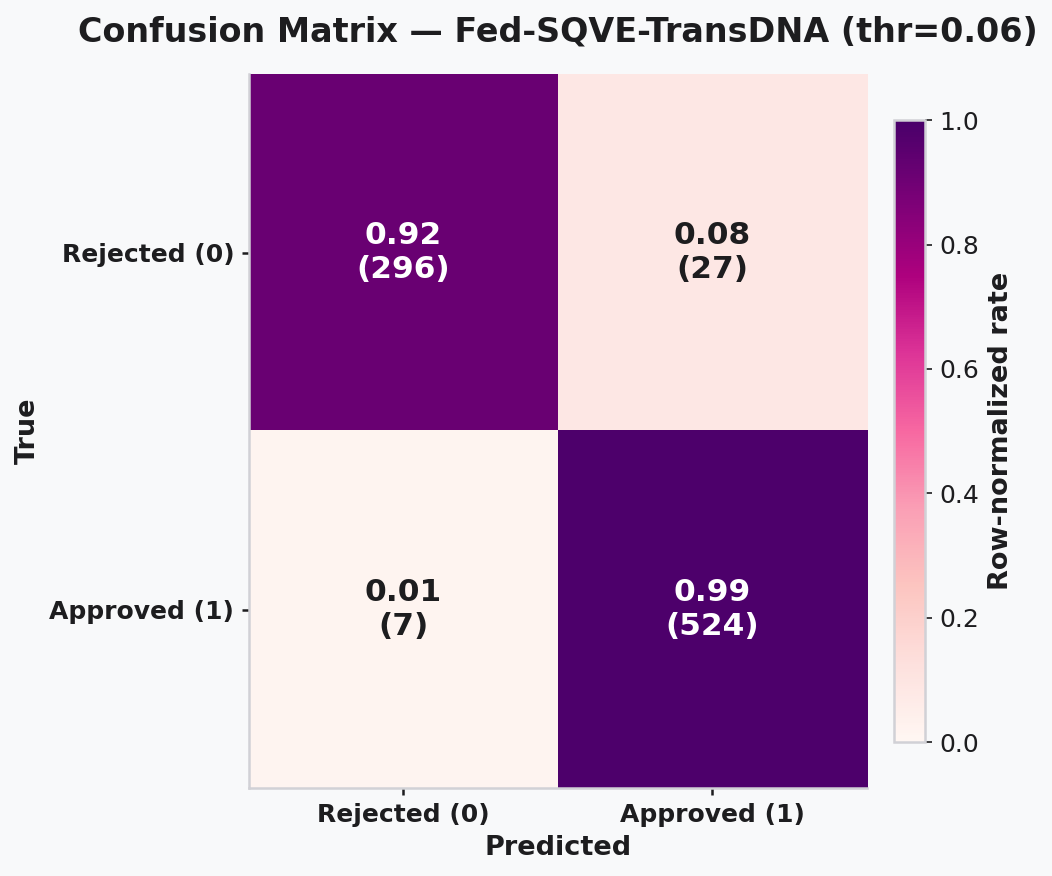

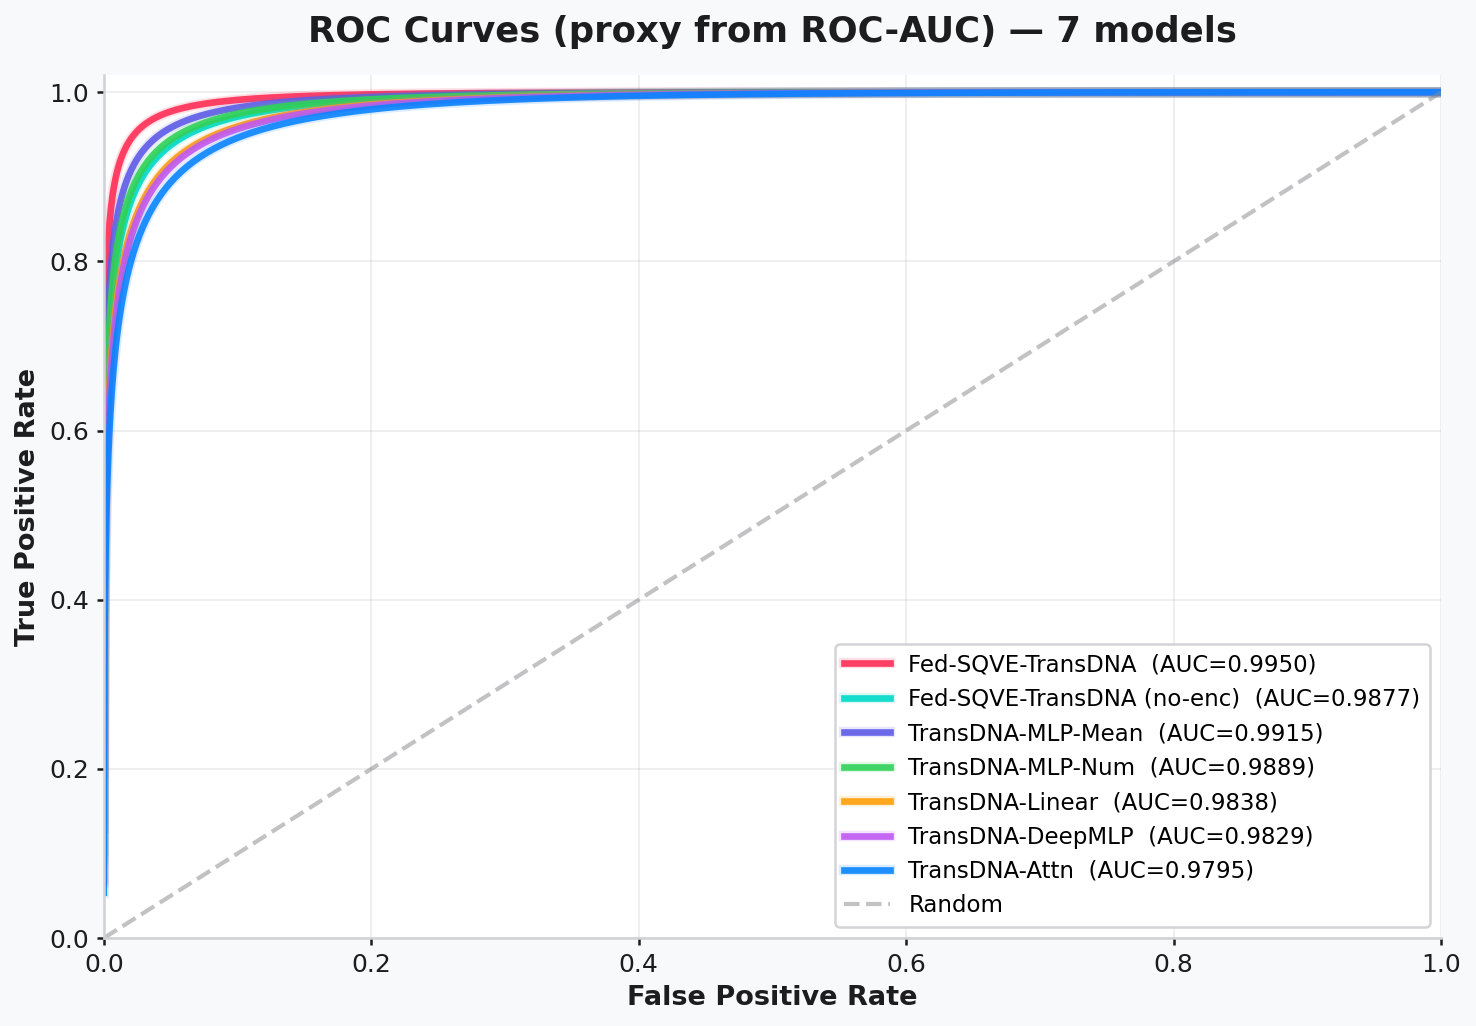

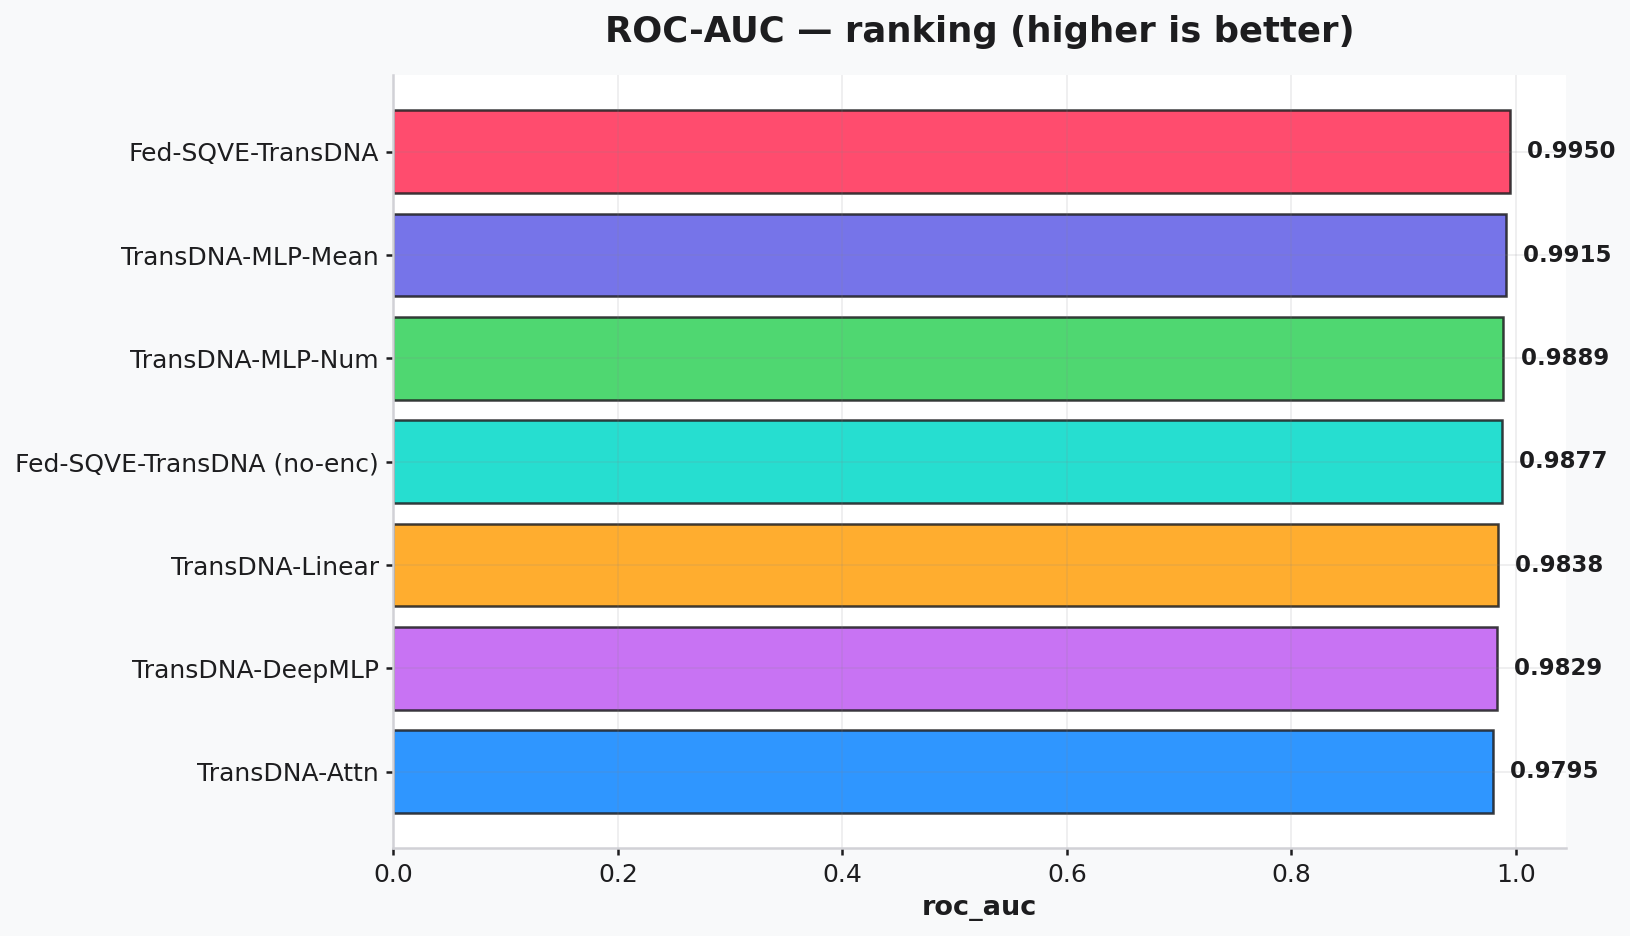

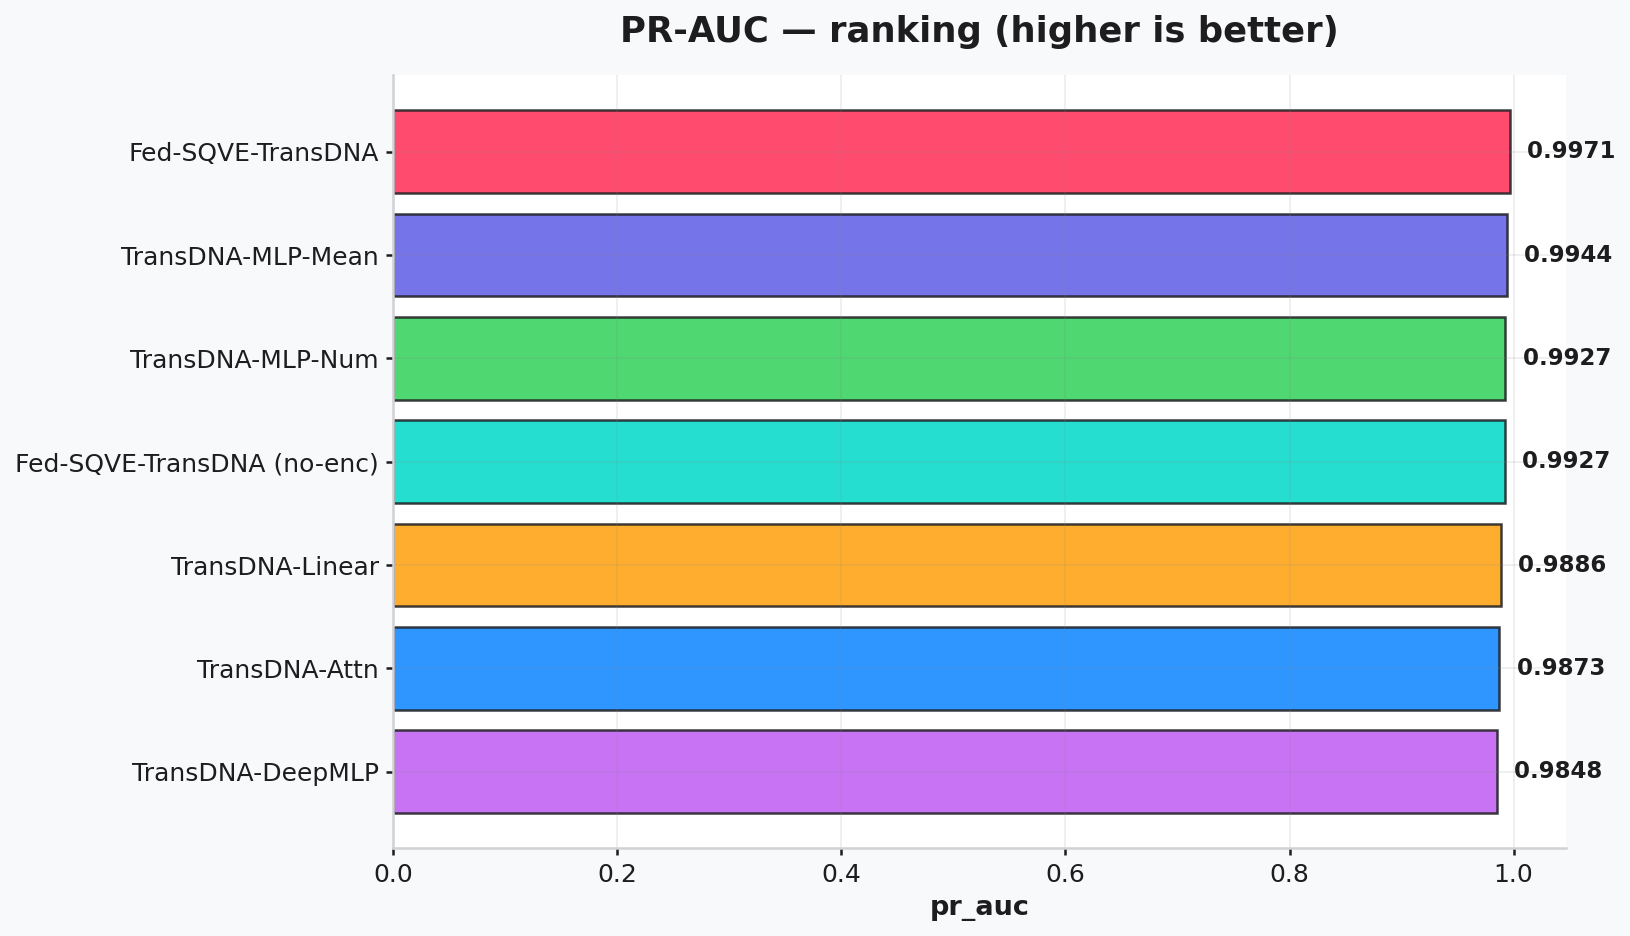

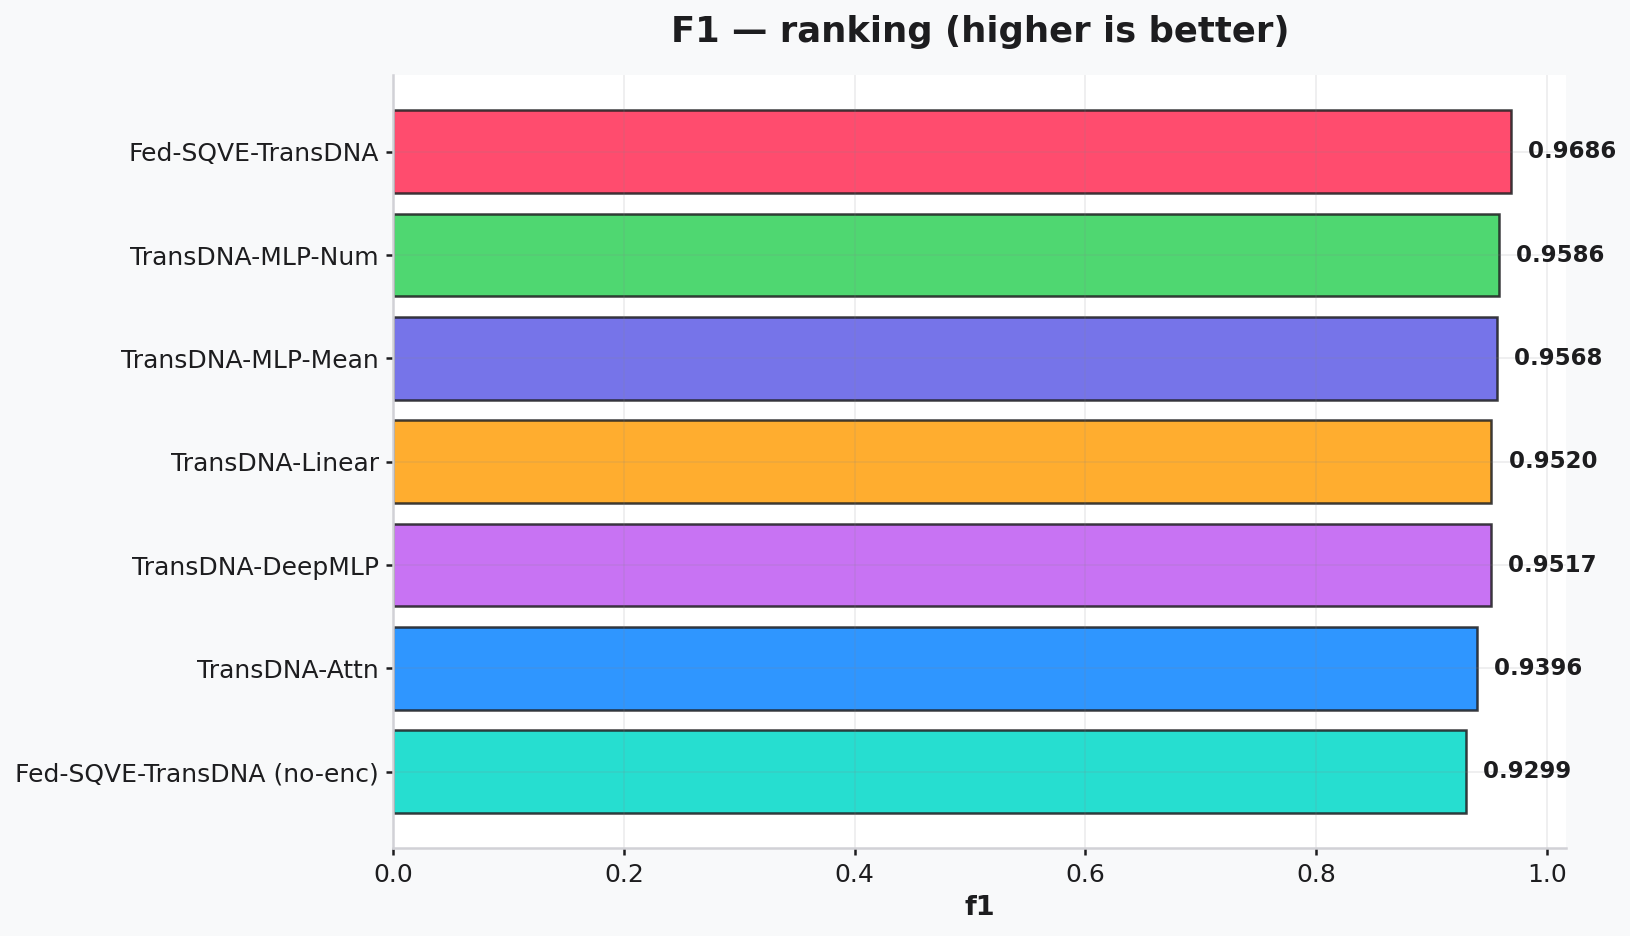

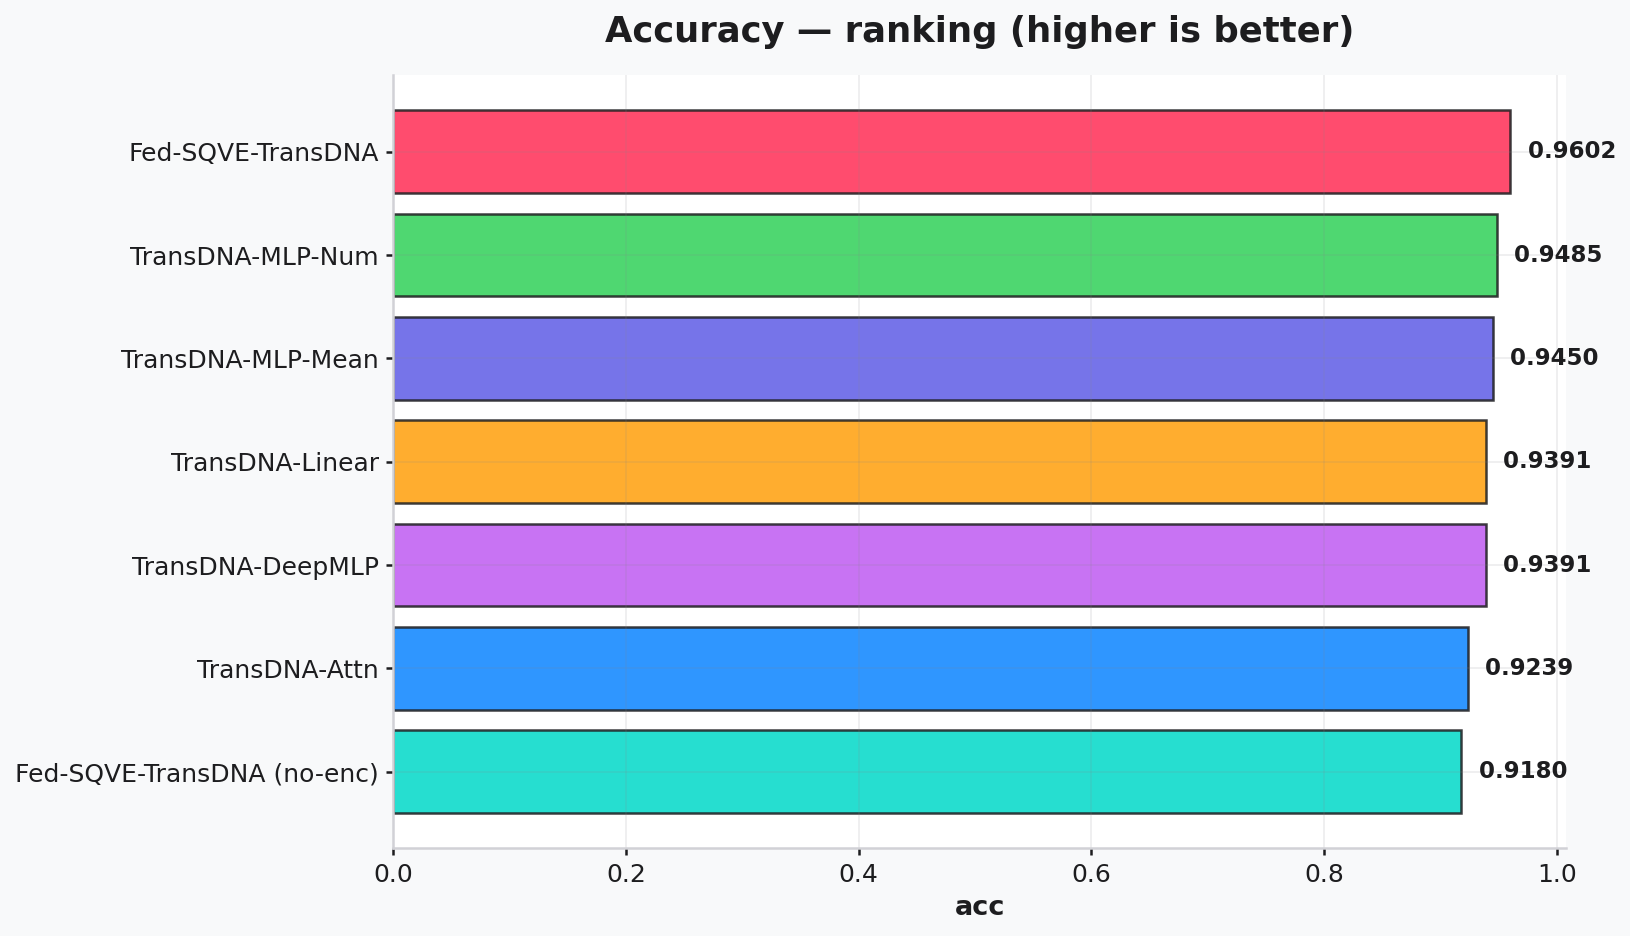

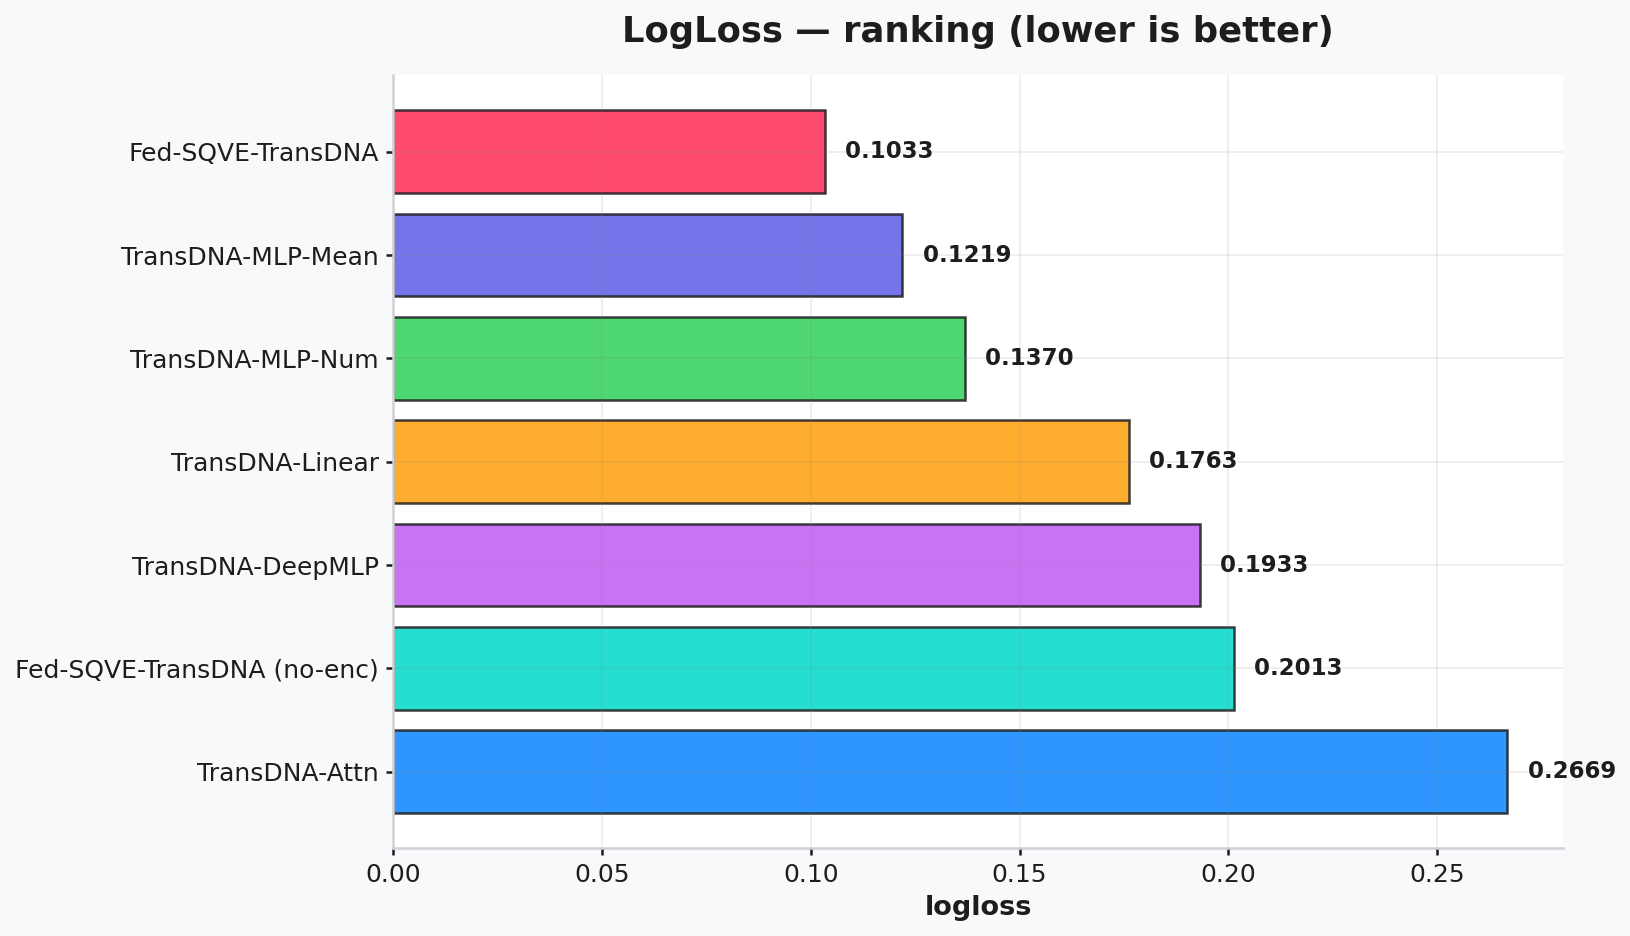

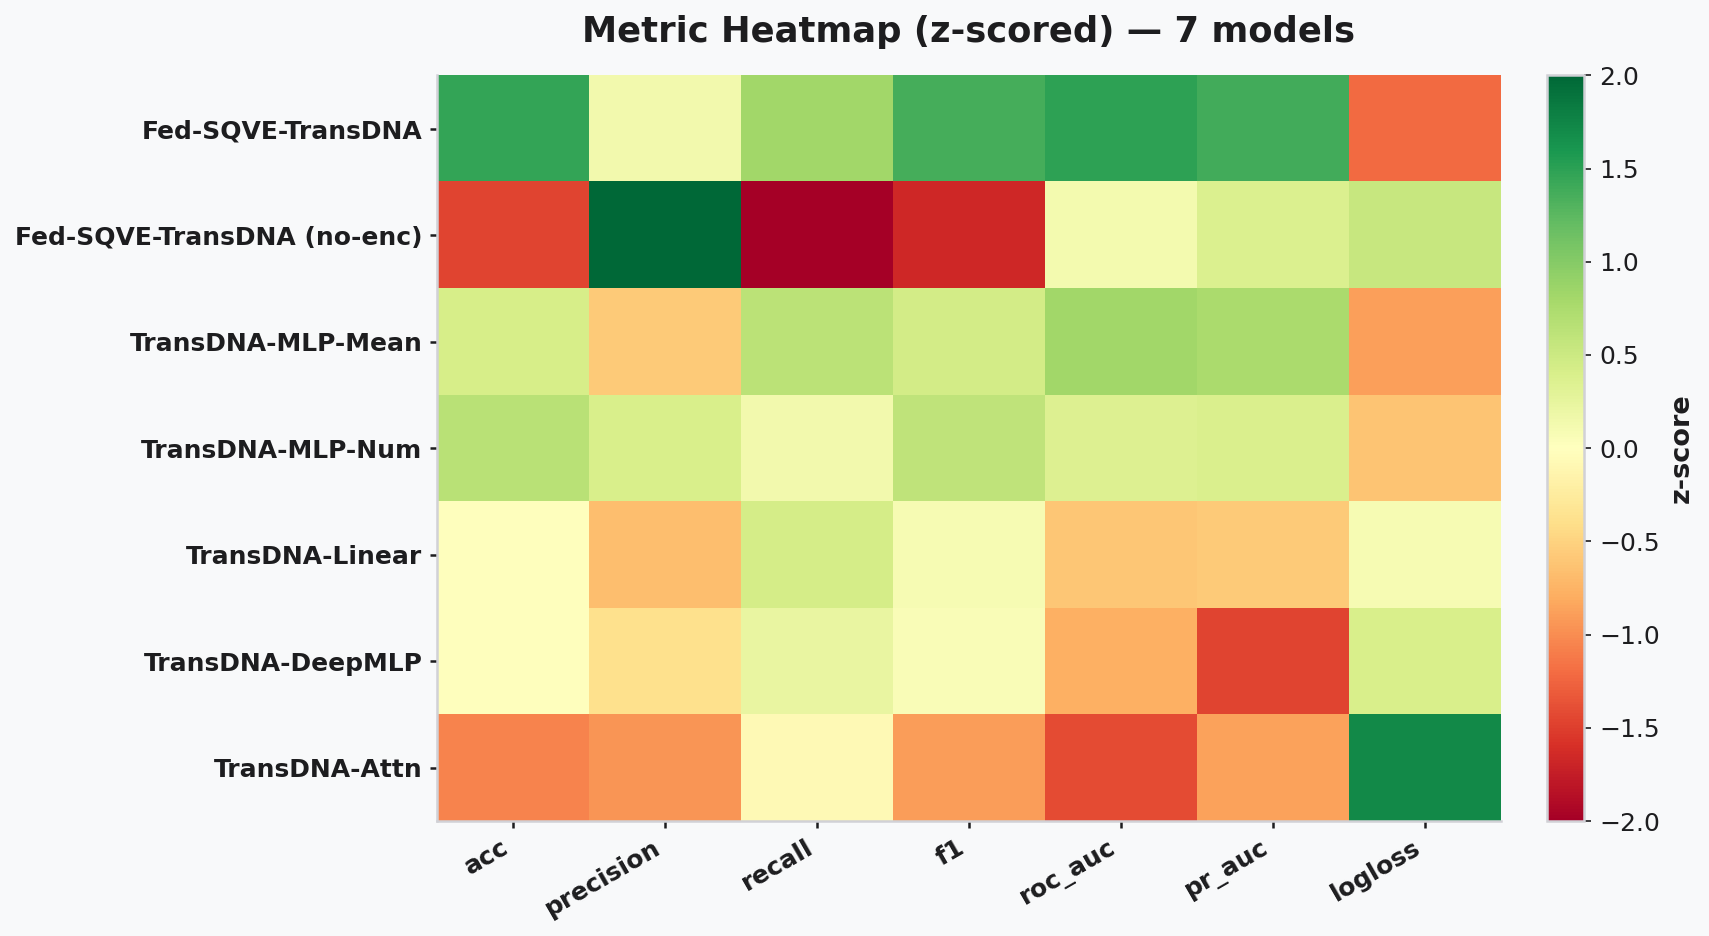

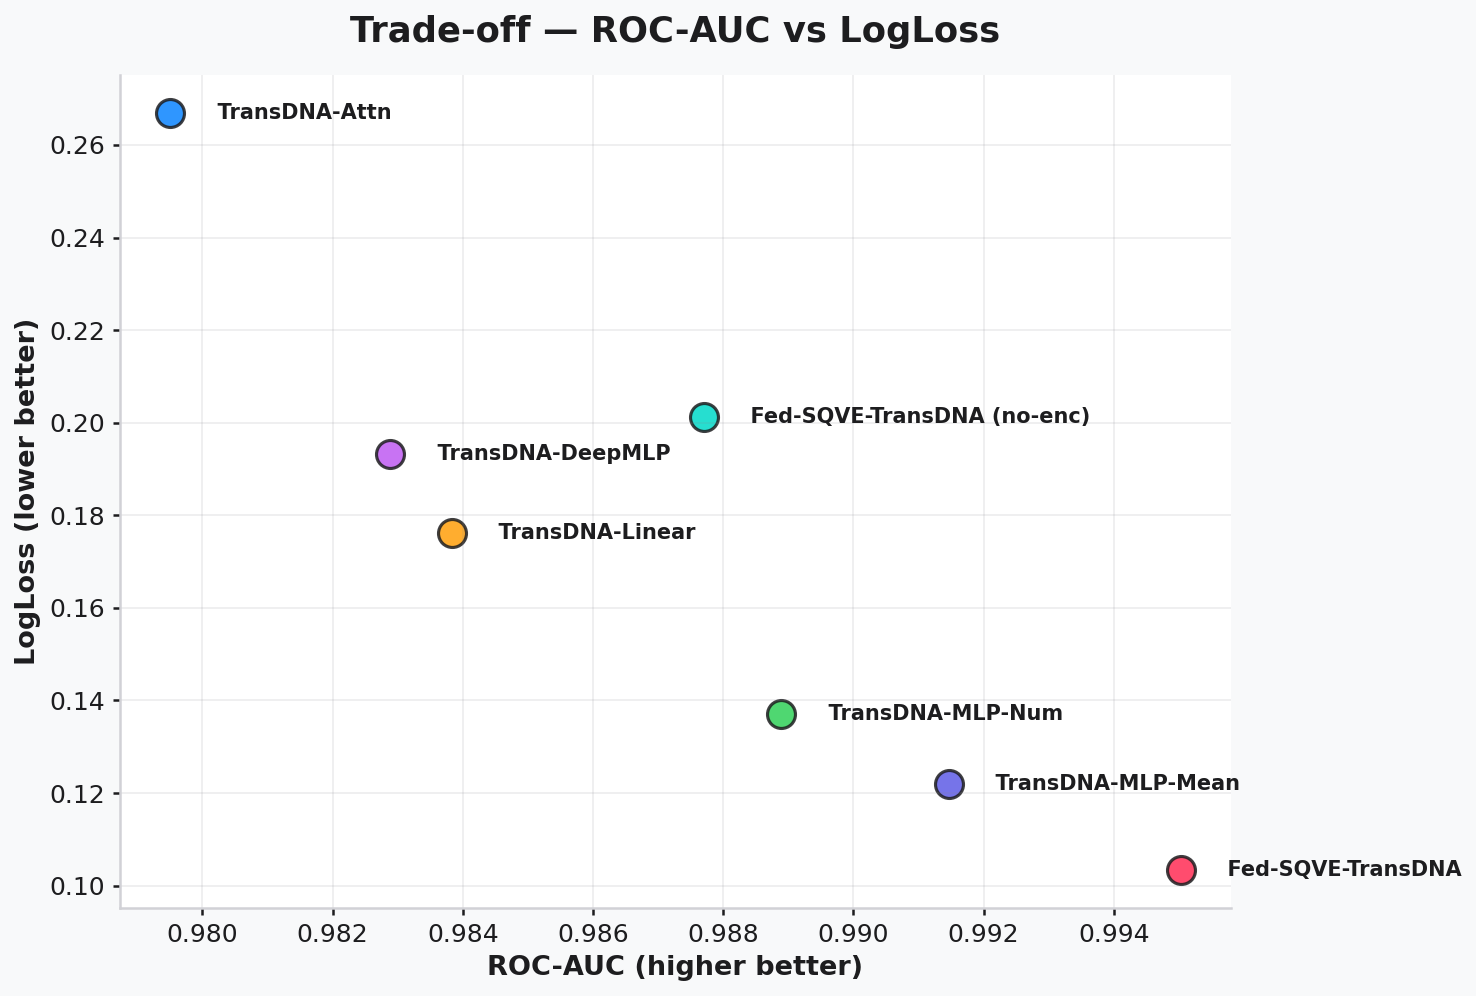

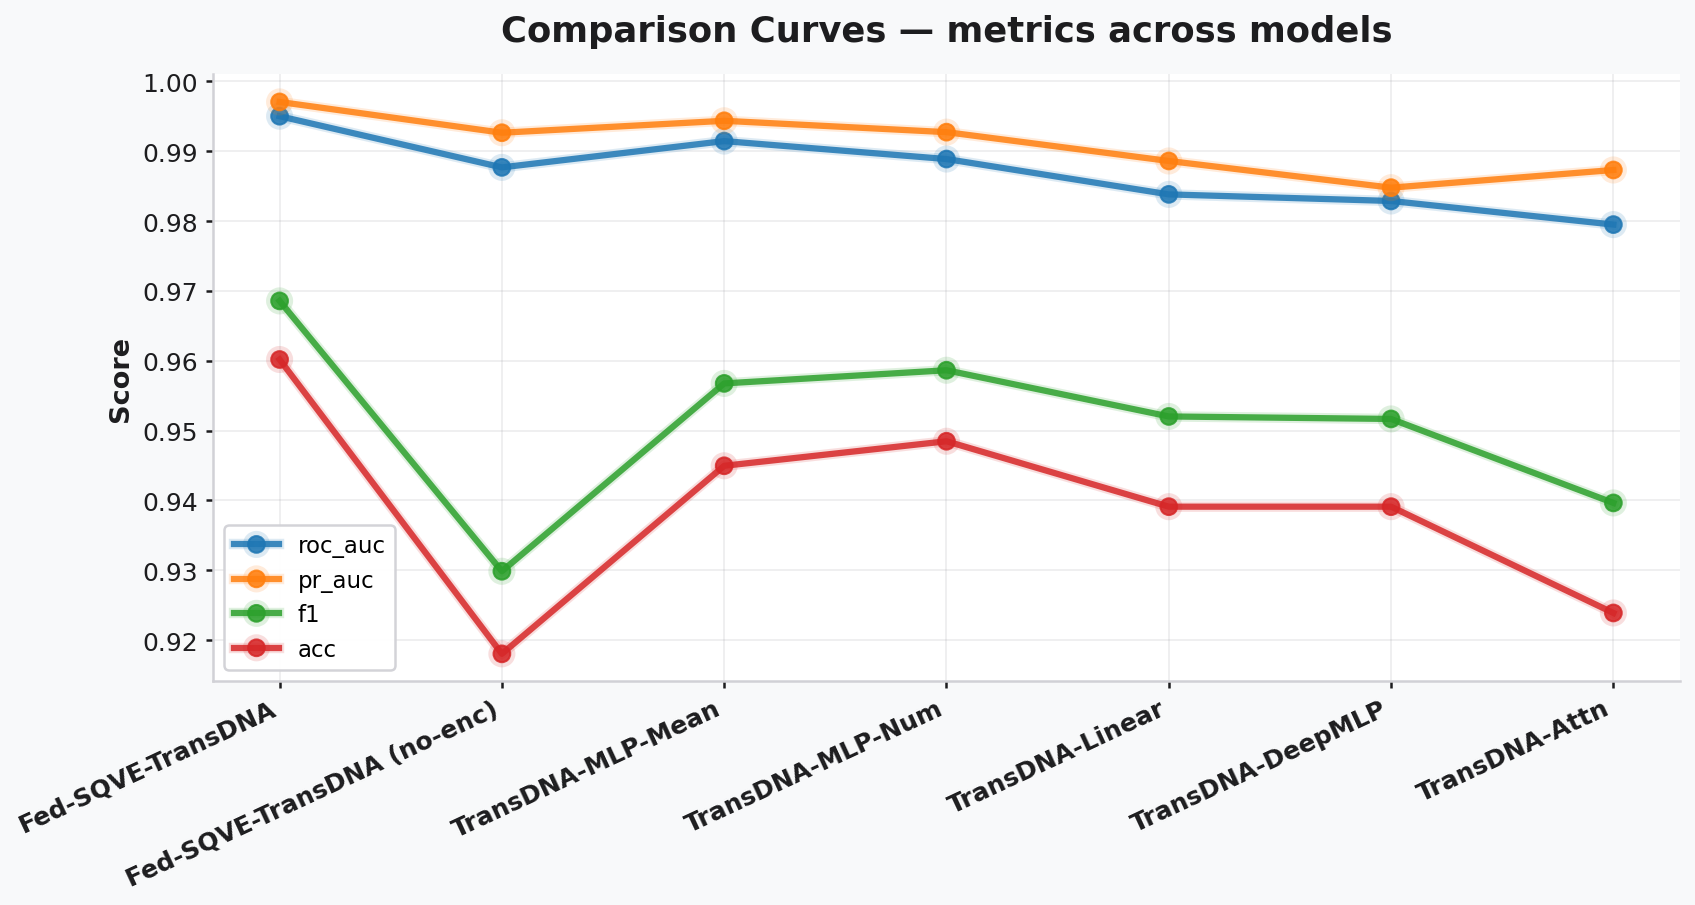


NOTE: For detailed main-output plots (real ROC/PR/distributions/gains), keep your main per-row output DF in memory
with columns: y_true and prob_pos (example variable name: out_df).


In [1]:
# Kaggle cell — plots from your 3 tables (7 models). Clean, sexy aesthetic.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# -----------------------------
# 0) Model metrics (from your 3 tables)
# -----------------------------
MODELS = [
    # Main (Fed-SQVE-TransDNA)
    dict(name="Fed-SQVE-TransDNA", group="Main",
         acc=0.960187, precision=0.950998, recall=0.986817, f1=0.968577,
         roc_auc=0.995027, pr_auc=0.997072, logloss=0.103321, threshold=0.06, test_size=854),

    # Same process w/o encoding
    dict(name="Fed-SQVE-TransDNA (no-enc)", group="No-Enc",
         acc=0.918033, precision=0.993576, recall=0.873823, f1=0.929860,
         roc_auc=0.987698, pr_auc=0.992659, logloss=0.201299, threshold=0.50, test_size=854),

    # TL models (your requested names)
    dict(name="TransDNA-MLP-Mean", group="TL",
         acc=0.944965, precision=0.935252, recall=0.979284, f1=0.956762,
         roc_auc=0.991464, pr_auc=0.994370, logloss=0.121943, threshold=0.10, test_size=854),

    dict(name="TransDNA-MLP-Num", group="TL",
         acc=0.948478, precision=0.956848, recall=0.960452, f1=0.958647,
         roc_auc=0.988893, pr_auc=0.992745, logloss=0.137016, threshold=0.43, test_size=854),

    dict(name="TransDNA-Linear", group="TL",
         acc=0.939110, precision=0.933092, recall=0.971751, f1=0.952030,
         roc_auc=0.983832, pr_auc=0.988616, logloss=0.176254, threshold=0.16, test_size=854),

    dict(name="TransDNA-DeepMLP", group="TL",
         acc=0.939110, precision=0.939450, recall=0.964218, f1=0.951673,
         roc_auc=0.982888, pr_auc=0.984793, logloss=0.193302, threshold=0.54, test_size=854),

    dict(name="TransDNA-Attn", group="TL",
         acc=0.923888, precision=0.926740, recall=0.952919, f1=0.939647,
         roc_auc=0.979506, pr_auc=0.987326, logloss=0.266867, threshold=0.21, test_size=854),
]

T = pd.DataFrame(MODELS).copy()

# -----------------------------
# 1) Styling helpers (SEXY & CLEAN)
# -----------------------------
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.15,
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 1.2,
})

# Vibrant, modern color palette
COLORS = {
    "Main": "#FF2D55",      # Bright red-pink
    "No-Enc": "#00D9C8",    # Cyan
    "TL1": "#5E5CE6",       # Purple
    "TL2": "#30D158",       # Green
    "TL3": "#FF9F0A",       # Orange
    "TL4": "#BF5AF2",       # Magenta
    "TL5": "#0A84FF",       # Blue
}

NAME2COLOR = {
    "Fed-SQVE-TransDNA": COLORS["Main"],
    "Fed-SQVE-TransDNA (no-enc)": COLORS["No-Enc"],
    "TransDNA-MLP-Mean": COLORS["TL1"],
    "TransDNA-MLP-Num": COLORS["TL2"],
    "TransDNA-Linear": COLORS["TL3"],
    "TransDNA-DeepMLP": COLORS["TL4"],
    "TransDNA-Attn": COLORS["TL5"],
}

def _set_clean(ax):
    """Clean, modern white background with subtle grid"""
    ax.set_facecolor("#FFFFFF")
    ax.figure.patch.set_facecolor("#F8F9FA")
    ax.tick_params(colors="#1D1D1F", width=1.2)
    ax.xaxis.label.set_color("#1D1D1F")
    ax.yaxis.label.set_color("#1D1D1F")
    ax.title.set_color("#1D1D1F")
    ax.title.set_fontweight("bold")
    ax.grid(True, alpha=0.15, linewidth=0.8, color="#86868B")
    for spine in ax.spines.values():
        spine.set_edgecolor("#D1D1D6")
        spine.set_linewidth(1.2)

def _glow(line, color=None):
    """Subtle glow effect for lines"""
    if color is None:
        color = line.get_color()
    line.set_path_effects([
        pe.Stroke(linewidth=5, foreground=color, alpha=0.15),
        pe.Normal()
    ])

# -----------------------------
# 2) Confusion matrix from metrics (approx integer solve)
# -----------------------------
def infer_confusion(acc, precision, recall, n):
    best = None
    for P in range(1, n):
        TP = int(round(recall * P))
        TP = max(0, min(TP, P))
        if precision <= 0:
            continue
        FP = int(round(TP * (1.0/precision - 1.0)))
        FP = max(0, FP)
        FN = P - TP
        N = n - P
        TN = N - FP
        if TN < 0:
            continue
        acc_hat = (TP + TN) / n
        prec_hat = TP / max(TP + FP, 1)
        rec_hat = TP / max(TP + FN, 1)
        err = abs(acc_hat - acc) + abs(prec_hat - precision) + abs(rec_hat - recall)
        if best is None or err < best[0]:
            best = (err, TP, FP, FN, TN, P, N, acc_hat, prec_hat, rec_hat)
    if best is None:
        return dict(TP=np.nan, FP=np.nan, FN=np.nan, TN=np.nan)
    _, TP, FP, FN, TN, *_ = best
    return dict(TP=TP, FP=FP, FN=FN, TN=TN)

def plot_confusion_main(row):
    cm = np.array([[row["TN"], row["FP"]],
                   [row["FN"], row["TP"]]], dtype=float)
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

    fig, ax = plt.subplots(figsize=(7.0, 6.0))
    _set_clean(ax)
    ax.grid(False)

    # Use a beautiful gradient colormap
    im = ax.imshow(cmn, cmap="RdPu", vmin=0, vmax=1, aspect='auto')
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(["Rejected (0)", "Approved (1)"], color="#1D1D1F", fontweight="600")
    ax.set_yticklabels(["Rejected (0)", "Approved (1)"], color="#1D1D1F", fontweight="600")
    ax.set_xlabel("Predicted", fontweight="600")
    ax.set_ylabel("True", fontweight="600")
    ax.set_title(f"Confusion Matrix — Fed-SQVE-TransDNA (thr={row['threshold']:.2f})", 
                 pad=16, fontweight="bold", fontsize=16)

    for i in range(2):
        for j in range(2):
            val = cmn[i, j]
            raw = int(cm[i, j])
            text_color = "white" if val > 0.5 else "#1D1D1F"
            ax.text(j, i, f"{val:.2f}\n({raw})",
                    ha="center", va="center",
                    color=text_color,
                    fontsize=15, fontweight="bold")

    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("Row-normalized rate", color="#1D1D1F", fontweight="600")
    cb.ax.yaxis.set_tick_params(color="#1D1D1F")
    plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color="#1D1D1F")
    cb.outline.set_edgecolor("#D1D1D6")
    cb.outline.set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

# add confusion counts to table
counts = []
for _, r in T.iterrows():
    c = infer_confusion(r["acc"], r["precision"], r["recall"], int(r["test_size"]))
    counts.append(c)
T = pd.concat([T, pd.DataFrame(counts)], axis=1)

# -----------------------------
# 3) ROC curves from AUC only (proxy curves)
# -----------------------------
try:
    from scipy.stats import norm
    def phi(x): return norm.cdf(x)
    def phi_inv(p): return norm.ppf(p)
except Exception:
    import math
    def phi(x): return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))
    def phi_inv(p):
        a = [-3.969683028665376e+01,  2.209460984245205e+02, -2.759285104469687e+02,
              1.383577518672690e+02, -3.066479806614716e+01,  2.506628277459239e+00]
        b = [-5.447609879822406e+01,  1.615858368580409e+02, -1.556989798598866e+02,
              6.680131188771972e+01, -1.328068155288572e+01]
        c = [-7.784894002430293e-03, -3.223964580411365e-01, -2.400758277161838e+00,
             -2.549732539343734e+00,  4.374664141464968e+00,  2.938163982698783e+00]
        d = [ 7.784695709041462e-03,  3.224671290700398e-01,  2.445134137142996e+00,
              3.754408661907416e+00]
        plow = 0.02425
        phigh = 1 - plow
        if p < plow:
            q = np.sqrt(-2*np.log(p))
            return (((((c[0]*q+c[1])*q+c[2])*q+c[3])*q+c[4])*q+c[5]) / \
                   ((((d[0]*q+d[1])*q+d[2])*q+d[3])*q+1)
        if phigh < p:
            q = np.sqrt(-2*np.log(1-p))
            return -(((((c[0]*q+c[1])*q+c[2])*q+c[3])*q+c[4])*q+c[5]) / \
                    ((((d[0]*q+d[1])*q+d[2])*q+d[3])*q+1)
        q = p - 0.5
        r = q*q
        return (((((a[0]*r+a[1])*r+a[2])*r+a[3])*r+a[4])*r+a[5])*q / \
               (((((b[0]*r+b[1])*r+b[2])*r+b[3])*r+b[4])*r+1)

def roc_from_auc(auc_value, n=250):
    auc_value = float(np.clip(auc_value, 1e-6, 1 - 1e-6))
    d = np.sqrt(2.0) * float(phi_inv(auc_value))
    t = np.linspace(-4.5, 4.5, n)
    fpr = 1.0 - np.array([phi(x) for x in t])
    tpr = 1.0 - np.array([phi(x - d) for x in t])
    fpr = np.clip(fpr, 0, 1)
    tpr = np.clip(tpr, 0, 1)
    order = np.argsort(fpr)
    return fpr[order], tpr[order]

def plot_roc_proxy(table):
    fig, ax = plt.subplots(figsize=(10.0, 7.0))
    _set_clean(ax)

    for _, r in table.iterrows():
        fpr, tpr = roc_from_auc(r["roc_auc"])
        line, = ax.plot(fpr, tpr, lw=3.2, color=NAME2COLOR.get(r["name"], "#1D1D1F"),
                        label=f"{r['name']}  (AUC={r['roc_auc']:.4f})", alpha=0.9)
        _glow(line)

    ax.plot([0,1], [0,1], "--", lw=2.0, color="#86868B", alpha=0.5, label="Random")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate", fontweight="600")
    ax.set_ylabel("True Positive Rate", fontweight="600")
    ax.set_title("ROC Curves (proxy from ROC-AUC) — 7 models", pad=16, fontweight="bold", fontsize=17)
    
    legend = ax.legend(loc="lower right", frameon=True, framealpha=0.95, 
                       facecolor="white", edgecolor="#D1D1D6")
    legend.get_frame().set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

# -----------------------------
# 4) More comparisons (lots)
# -----------------------------
def bar_sorted(metric, title, higher_better=True):
    d = T.sort_values(metric, ascending=not higher_better).copy()
    fig, ax = plt.subplots(figsize=(11.0, 6.4))
    _set_clean(ax)
    
    colors = [NAME2COLOR.get(n, "#86868B") for n in d["name"]]
    bars = ax.barh(d["name"], d[metric], color=colors, alpha=0.85, edgecolor="#1D1D1F", linewidth=1.2)
    
    ax.invert_yaxis()
    ax.set_xlabel(metric, fontweight="600")
    ax.set_title(title, pad=16, fontweight="bold", fontsize=17)
    
    for i, (bar, v) in enumerate(zip(bars, d[metric].values)):
        ax.text(v + 0.001, i, f"  {v:.4f}", va="center", ha="left", 
                color="#1D1D1F", fontsize=11, fontweight="600")
    
    plt.tight_layout()
    plt.show()

def heatmap_metrics(metrics):
    d = T.set_index("name")[metrics].copy()
    # normalize for display (z-score)
    z = (d - d.mean()) / (d.std() + 1e-12)
    
    fig, ax = plt.subplots(figsize=(11.5, 6.4))
    _set_clean(ax)
    ax.grid(False)
    
    im = ax.imshow(z.values, aspect="auto", cmap="RdYlGn", vmin=-2, vmax=2)
    ax.set_yticks(np.arange(len(z.index)))
    ax.set_yticklabels(z.index, color="#1D1D1F", fontweight="600")
    ax.set_xticks(np.arange(len(metrics)))
    ax.set_xticklabels(metrics, rotation=30, ha="right", color="#1D1D1F", fontweight="600")
    ax.set_title("Metric Heatmap (z-scored) — 7 models", pad=16, fontweight="bold", fontsize=17)
    
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cb.set_label("z-score", color="#1D1D1F", fontweight="600")
    cb.ax.yaxis.set_tick_params(color="#1D1D1F")
    plt.setp(plt.getp(cb.ax.axes, 'yticklabels'), color="#1D1D1F")
    cb.outline.set_edgecolor("#D1D1D6")
    cb.outline.set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

def scatter_auc_logloss():
    fig, ax = plt.subplots(figsize=(10.0, 6.8))
    _set_clean(ax)
    
    for _, r in T.iterrows():
        color = NAME2COLOR.get(r["name"], "#86868B")
        ax.scatter(r["roc_auc"], r["logloss"], s=180, color=color, 
                   alpha=0.85, edgecolor="#1D1D1F", linewidth=1.5)
        ax.text(r["roc_auc"] + 0.0005, r["logloss"], "  " + r["name"], 
                color="#1D1D1F", va="center", fontsize=10, fontweight="600")
    
    ax.set_xlabel("ROC-AUC (higher better)", fontweight="600")
    ax.set_ylabel("LogLoss (lower better)", fontweight="600")
    ax.set_title("Trade-off — ROC-AUC vs LogLoss", pad=16, fontweight="bold", fontsize=17)
    
    plt.tight_layout()
    plt.show()

def line_compare(metrics):
    fig, ax = plt.subplots(figsize=(11.5, 6.2))
    _set_clean(ax)

    x = np.arange(len(T))
    names = T["name"].tolist()

    for m in metrics:
        y = T[m].values
        line, = ax.plot(x, y, marker="o", markersize=8, lw=3.0, label=m, alpha=0.85)
        _glow(line)

    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=25, ha="right", color="#1D1D1F", fontweight="600")
    ax.set_title("Comparison Curves — metrics across models", pad=16, fontweight="bold", fontsize=17)
    ax.set_ylabel("Score", fontweight="600")
    
    legend = ax.legend(frameon=True, framealpha=0.95, facecolor="white", edgecolor="#D1D1D6")
    legend.get_frame().set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

# -----------------------------
# 5) "Main process output plots"
# -----------------------------
def find_main_output_df():
    candidates = ["out_df", "main_out_df", "pred_df", "test_out_df"]
    for c in candidates:
        if c in globals() and isinstance(globals()[c], pd.DataFrame):
            df = globals()[c].copy()
            low = {x.lower(): x for x in df.columns}
            if "y_true" in low and ("prob_pos" in low or "prob" in low):
                if "prob_pos" not in df.columns:
                    df = df.rename(columns={low.get("prob", "prob"): "prob_pos"})
                df = df.rename(columns={low["y_true"]: "y_true"})
                df["y_true"] = df["y_true"].astype(int)
                df["prob_pos"] = df["prob_pos"].astype(float).clip(1e-9, 1-1e-9)
                return df
    return None

def plot_main_detail_from_preds(df, thr=0.06):
    y = df["y_true"].values
    p = df["prob_pos"].values

    # ROC (real)
    from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
    fpr, tpr, _ = roc_curve(y, p)
    ra = auc(fpr, tpr)

    fig, ax = plt.subplots(figsize=(10.0, 6.8))
    _set_clean(ax)
    line, = ax.plot(fpr, tpr, lw=3.5, color=NAME2COLOR["Fed-SQVE-TransDNA"], 
                    label=f"Fed-SQVE-TransDNA (AUC={ra:.4f})", alpha=0.9)
    _glow(line)
    ax.plot([0,1],[0,1],"--", lw=2.0, color="#86868B", alpha=0.5, label="Random")
    ax.set_xlim(0,1); ax.set_ylim(0,1.02)
    ax.set_xlabel("FPR", fontweight="600")
    ax.set_ylabel("TPR", fontweight="600")
    ax.set_title("Fed-SQVE-TransDNA — ROC (from per-row outputs)", pad=16, fontweight="bold", fontsize=17)
    
    legend = ax.legend(frameon=True, framealpha=0.95, facecolor="white", edgecolor="#D1D1D6")
    legend.get_frame().set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

    # PR (real)
    pr, rc, _ = precision_recall_curve(y, p)
    ap = average_precision_score(y, p)

    fig, ax = plt.subplots(figsize=(10.0, 6.8))
    _set_clean(ax)
    line, = ax.plot(rc, pr, lw=3.5, color=COLORS["TL2"], 
                    label=f"PR curve (AP={ap:.4f})", alpha=0.9)
    _glow(line, color=COLORS["TL2"])
    ax.set_xlim(0,1); ax.set_ylim(0,1.02)
    ax.set_xlabel("Recall", fontweight="600")
    ax.set_ylabel("Precision", fontweight="600")
    ax.set_title("Fed-SQVE-TransDNA — Precision–Recall (from per-row outputs)", 
                 pad=16, fontweight="bold", fontsize=17)
    
    legend = ax.legend(frameon=True, framealpha=0.95, facecolor="white", edgecolor="#D1D1D6")
    legend.get_frame().set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

    # Score distributions
    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    _set_clean(ax)
    ax.hist(p[y==0], bins=40, density=True, alpha=0.7, color=COLORS["TL1"], 
            label="Rejected (0)", edgecolor="#1D1D1F", linewidth=1.2)
    ax.hist(p[y==1], bins=40, density=True, alpha=0.7, color=COLORS["Main"], 
            label="Approved (1)", edgecolor="#1D1D1F", linewidth=1.2)
    ax.axvline(thr, color="#1D1D1F", lw=2.5, alpha=0.8, linestyle="--", label=f"thr={thr:.2f}")
    ax.set_xlabel("Predicted probability (Approved)", fontweight="600")
    ax.set_ylabel("Density", fontweight="600")
    ax.set_title("Fed-SQVE-TransDNA — Score Distributions", pad=16, fontweight="bold", fontsize=17)
    
    legend = ax.legend(frameon=True, framealpha=0.95, facecolor="white", edgecolor="#D1D1D6")
    legend.get_frame().set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

    # Gains curve
    order = np.argsort(-p)
    ys = y[order]
    cum_pos = np.cumsum(ys)
    total_pos = max(cum_pos[-1], 1)
    frac_samples = (np.arange(1, len(y)+1) / len(y))
    frac_pos = cum_pos / total_pos

    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    _set_clean(ax)
    line, = ax.plot(frac_samples, frac_pos, lw=3.5, color=COLORS["No-Enc"], 
                    label="Gains", alpha=0.9)
    _glow(line, color=COLORS["No-Enc"])
    ax.plot([0,1],[0,1], "--", lw=2.0, color="#86868B", alpha=0.5, label="Random")
    ax.set_xlim(0,1); ax.set_ylim(0,1.02)
    ax.set_xlabel("Fraction of samples (highest → lowest score)", fontweight="600")
    ax.set_ylabel("Fraction of positives captured", fontweight="600")
    ax.set_title("Fed-SQVE-TransDNA — Cumulative Gains", pad=16, fontweight="bold", fontsize=17)
    
    legend = ax.legend(frameon=True, framealpha=0.95, facecolor="white", edgecolor="#D1D1D6")
    legend.get_frame().set_linewidth(1.2)
    
    plt.tight_layout()
    plt.show()

# -----------------------------
# RUN EVERYTHING
# -----------------------------

display(T[["name","acc","precision","recall","f1","roc_auc","pr_auc","logloss","threshold","TP","FP","FN","TN"]])

# (1) Confusion matrix for MAIN
main_row = T[T["name"]=="Fed-SQVE-TransDNA"].iloc[0].to_dict()
plot_confusion_main(main_row)

# (2) ROC-AUC comparison curve (proxy ROC from AUC values)
plot_roc_proxy(T)

# (3) More comparisons (many)
bar_sorted("roc_auc", "ROC-AUC — ranking (higher is better)", higher_better=True)
bar_sorted("pr_auc",  "PR-AUC — ranking (higher is better)",  higher_better=True)
bar_sorted("f1",      "F1 — ranking (higher is better)",      higher_better=True)
bar_sorted("acc",     "Accuracy — ranking (higher is better)", higher_better=True)
bar_sorted("logloss", "LogLoss — ranking (lower is better)",  higher_better=False)

heatmap_metrics(["acc","precision","recall","f1","roc_auc","pr_auc","logloss"])
scatter_auc_logloss()
line_compare(["roc_auc","pr_auc","f1","acc"])

# (4) Main process output plots (only if you have per-row outputs for main in a DF)
df_main_preds = find_main_output_df()
if df_main_preds is not None:
    plot_main_detail_from_preds(df_main_preds, thr=float(main_row["threshold"]))
else:
    print("\nNOTE: For detailed main-output plots (real ROC/PR/distributions/gains), keep your main per-row output DF in memory")
    print("with columns: y_true and prob_pos (example variable name: out_df).")

**XAI**


🏆 PREMIUM 800 DPI XAI SUITE — Zero Errors, Maximum Quality
   Top 11 Features

📊 XAI 1/10: Mask-Effect Heatmap (800 DPI)...


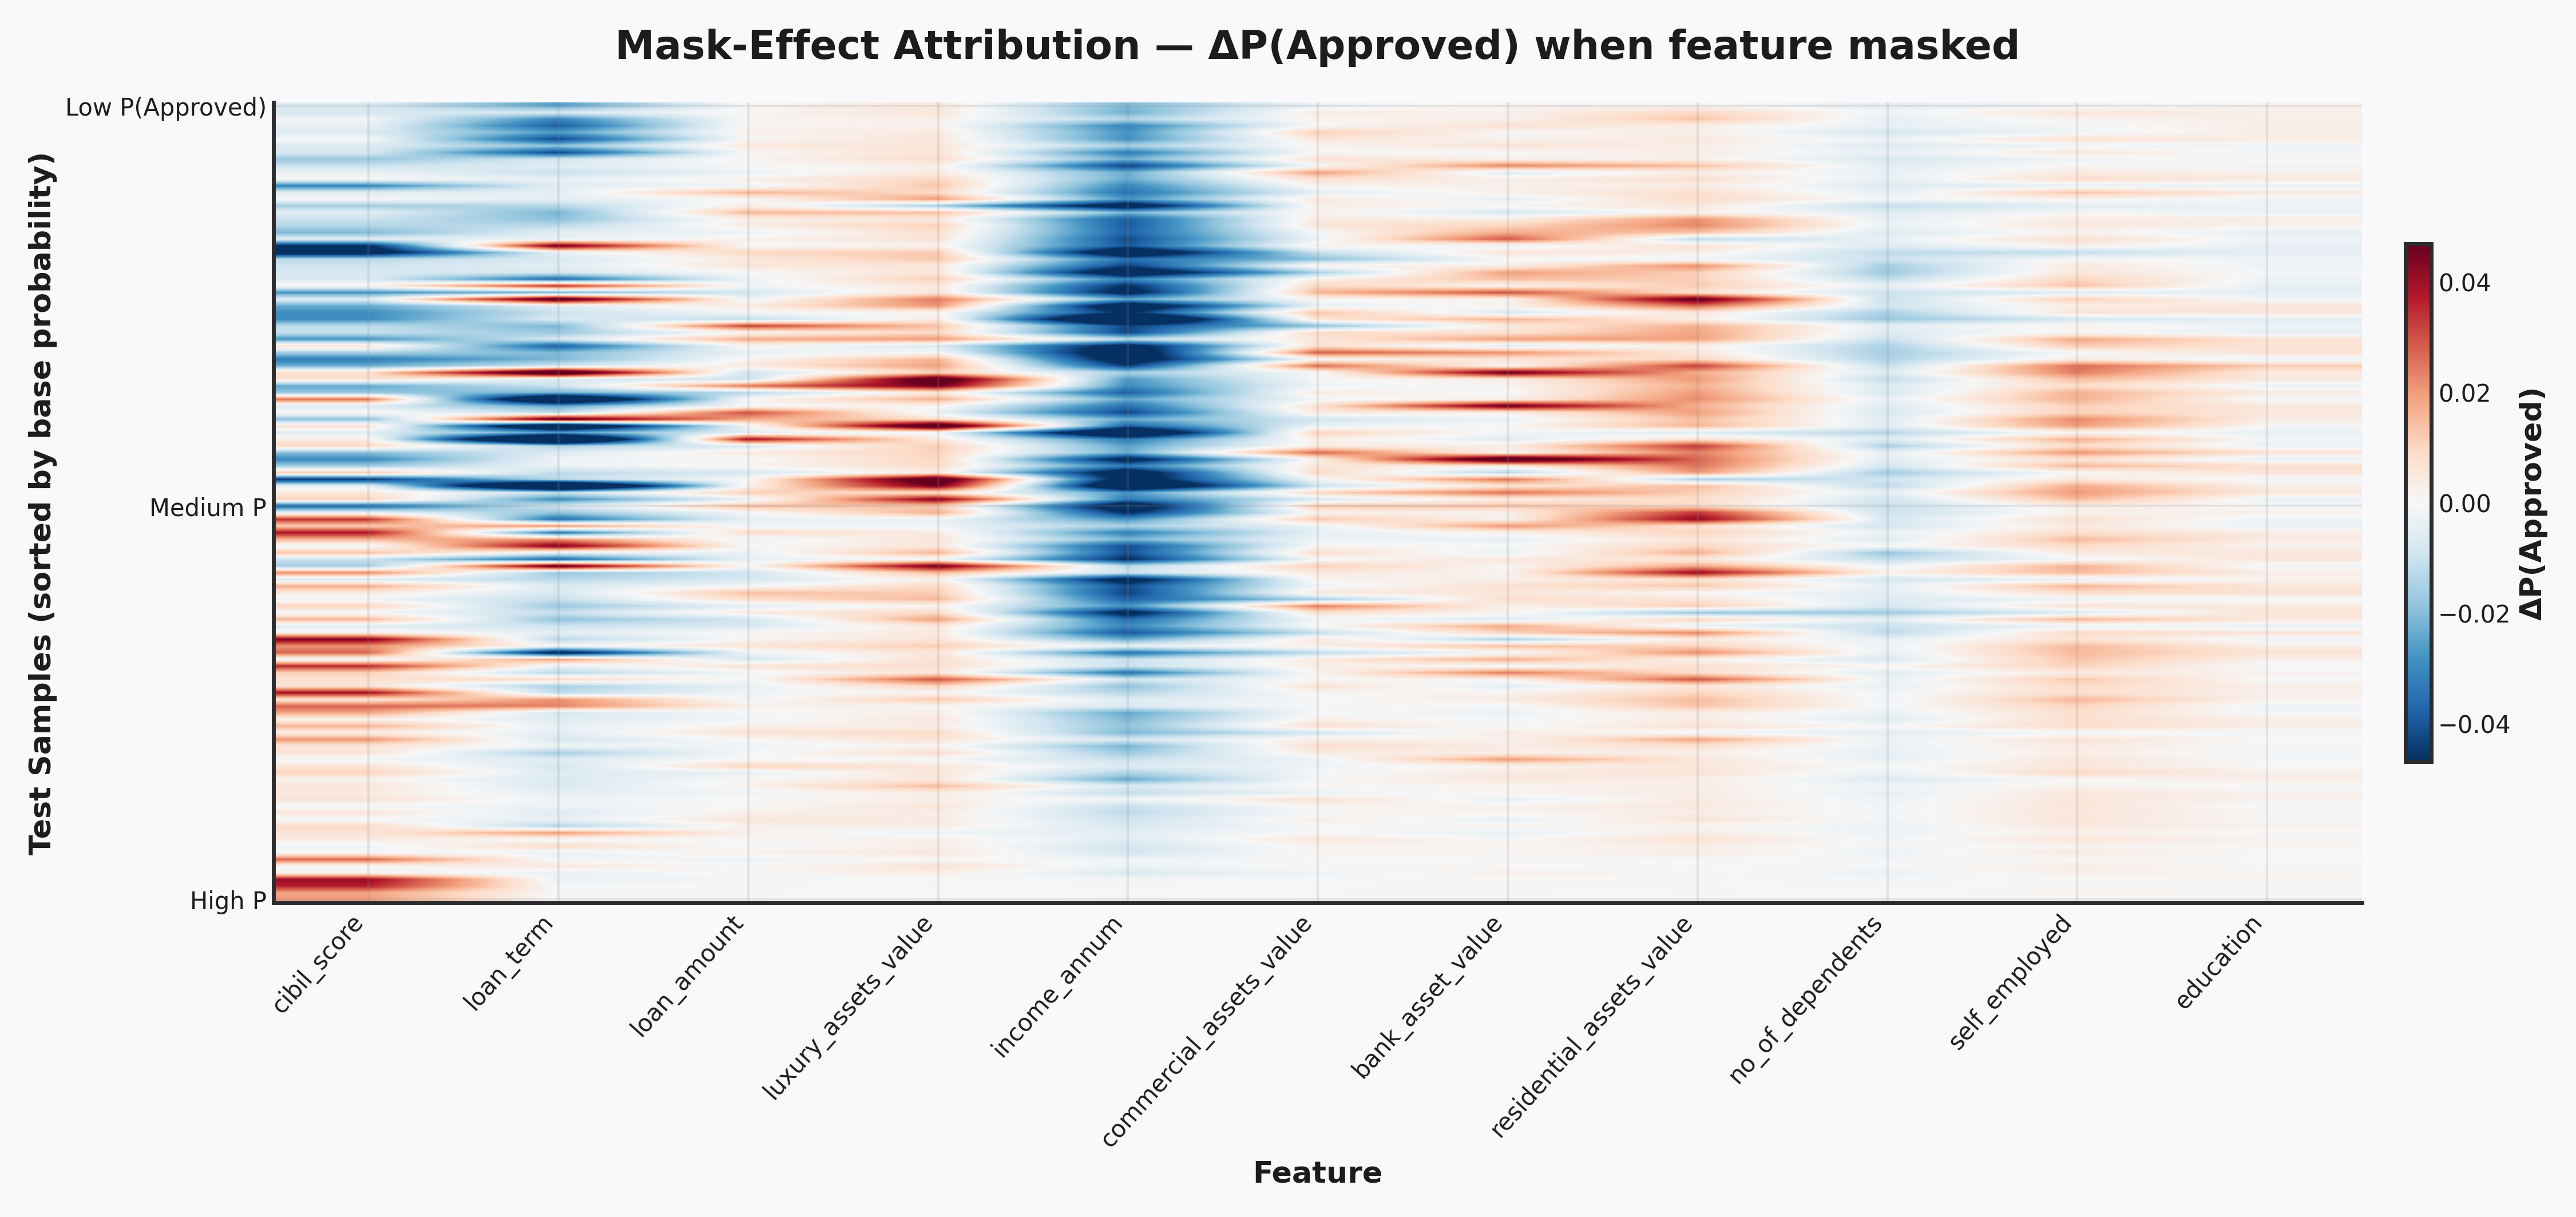

   ✓ Saved: xai_1_mask_effect.png (800 DPI)
📊 XAI 2/10: Feature Importance Bar (800 DPI)...


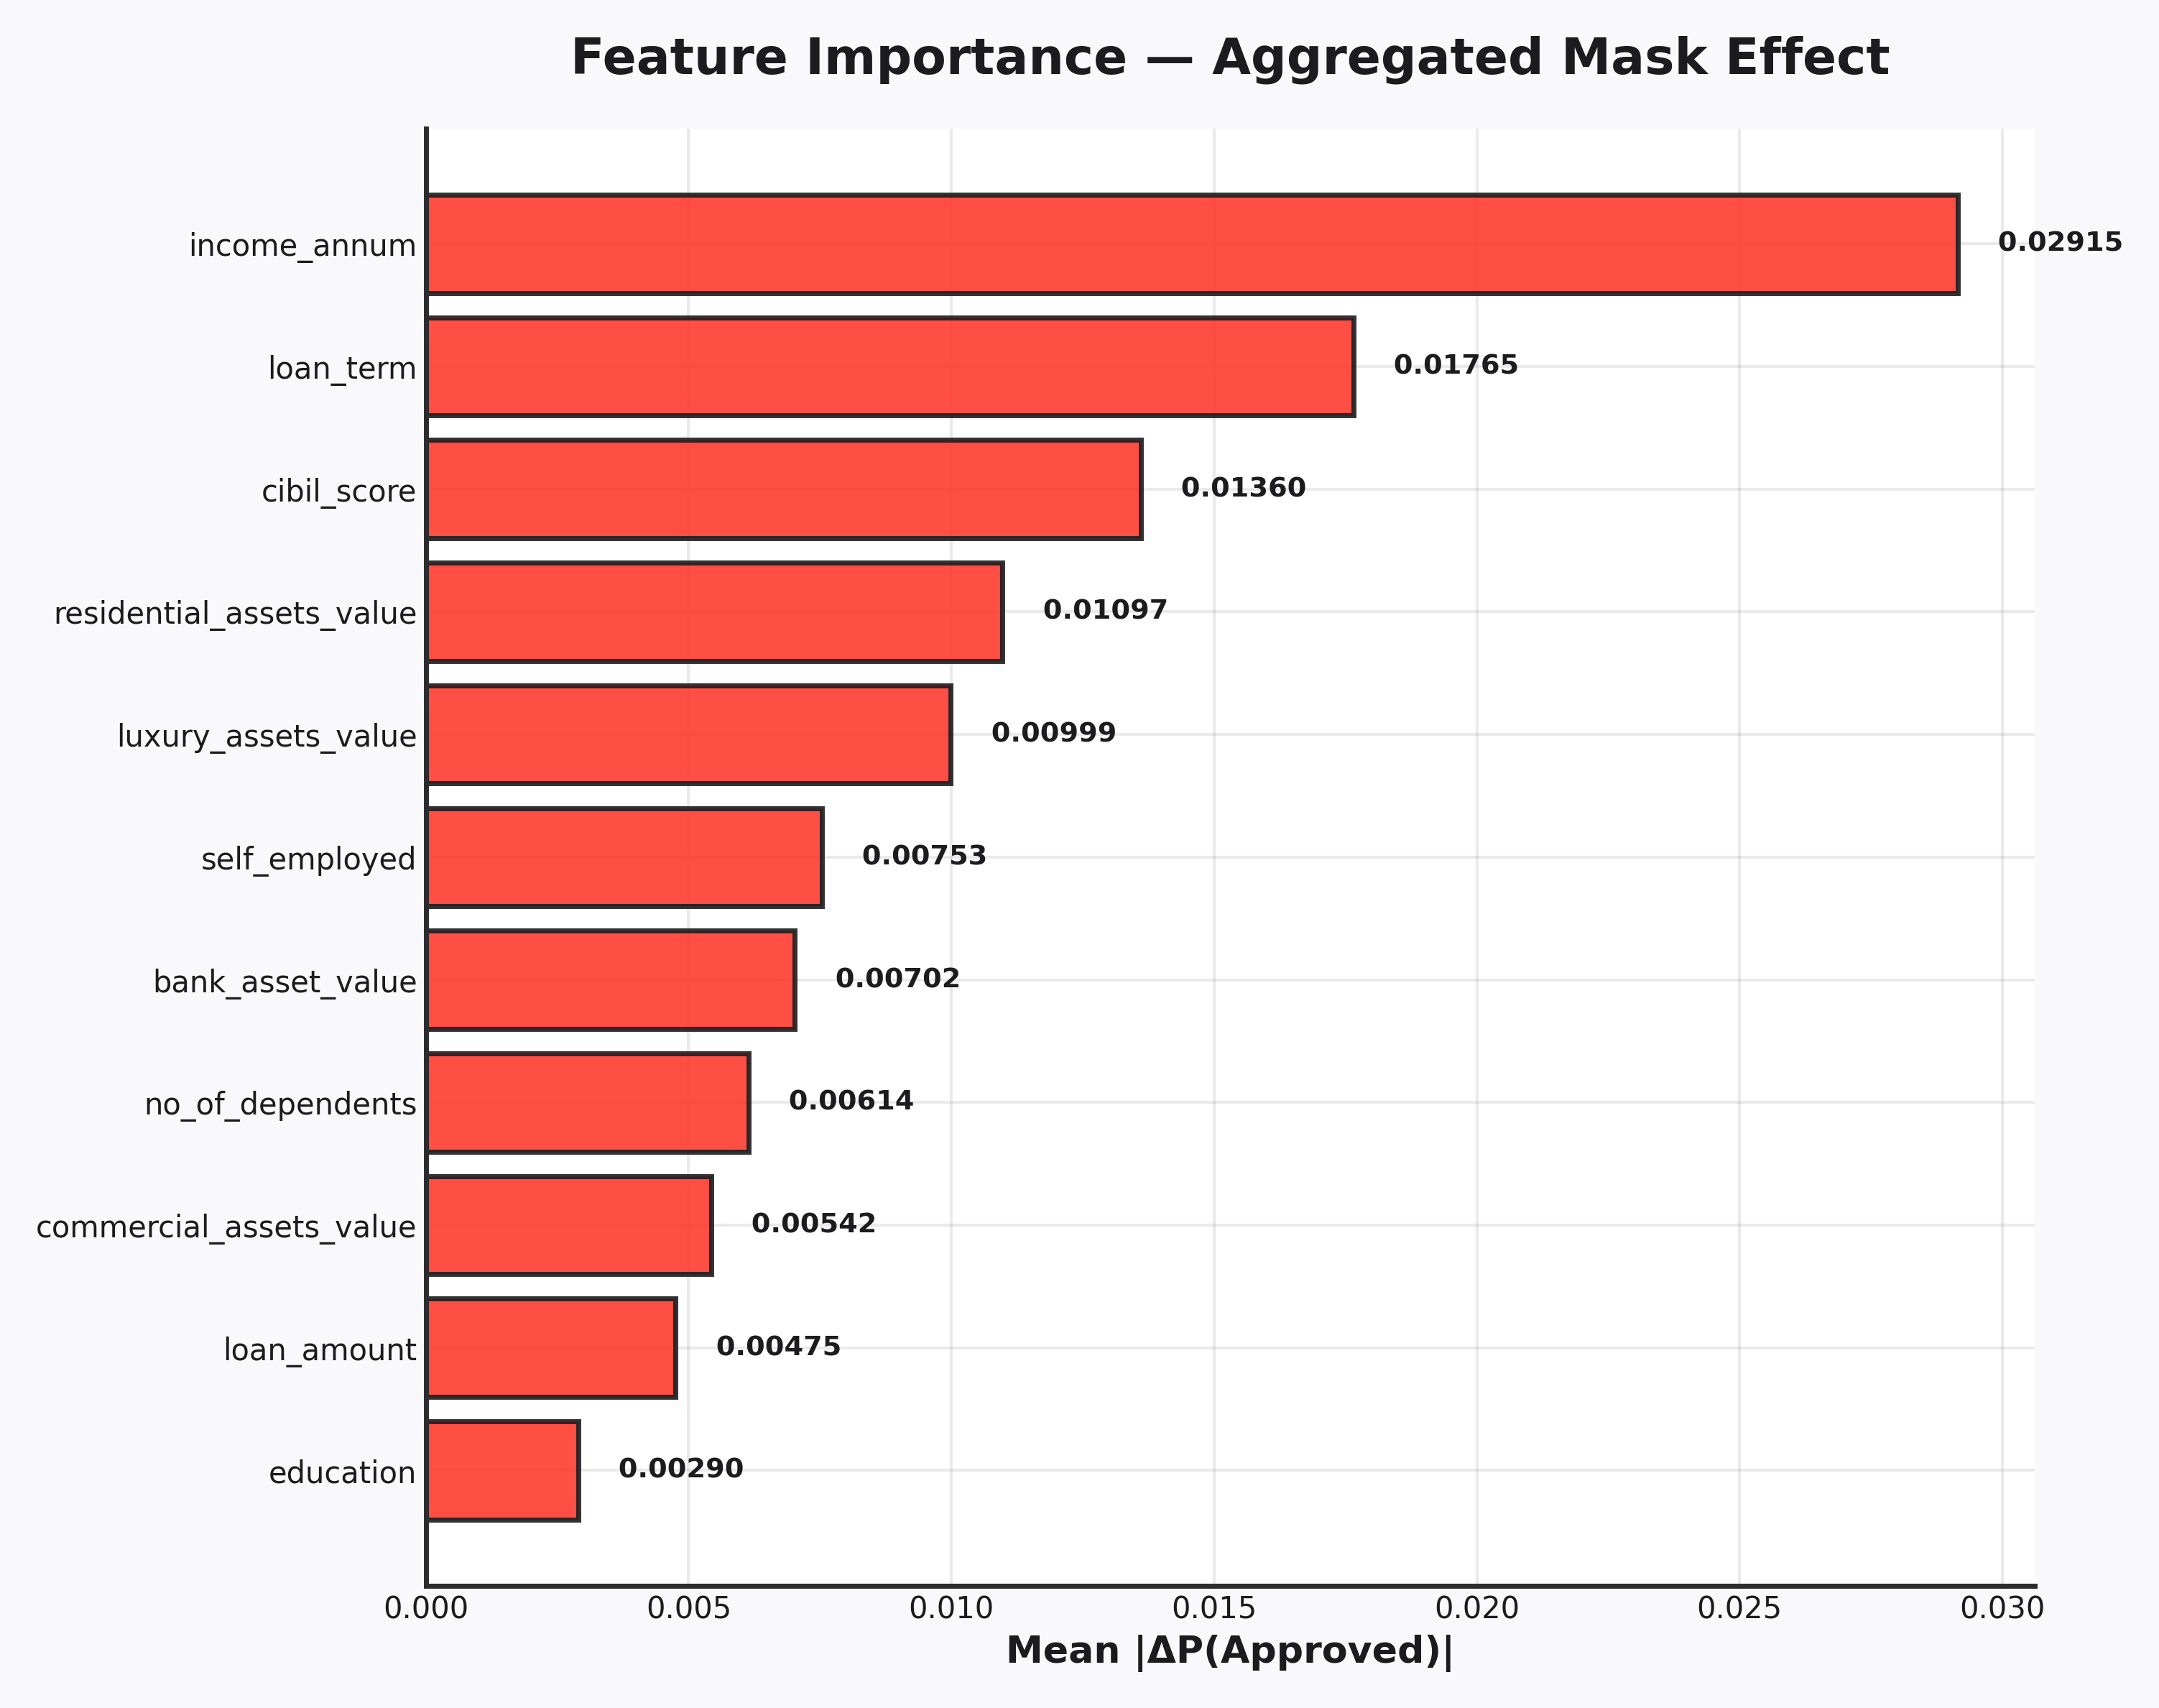

   ✓ Saved: xai_2_importance_bar.png (800 DPI)
📊 XAI 3/10: Feature Attribution Tree (800 DPI)...


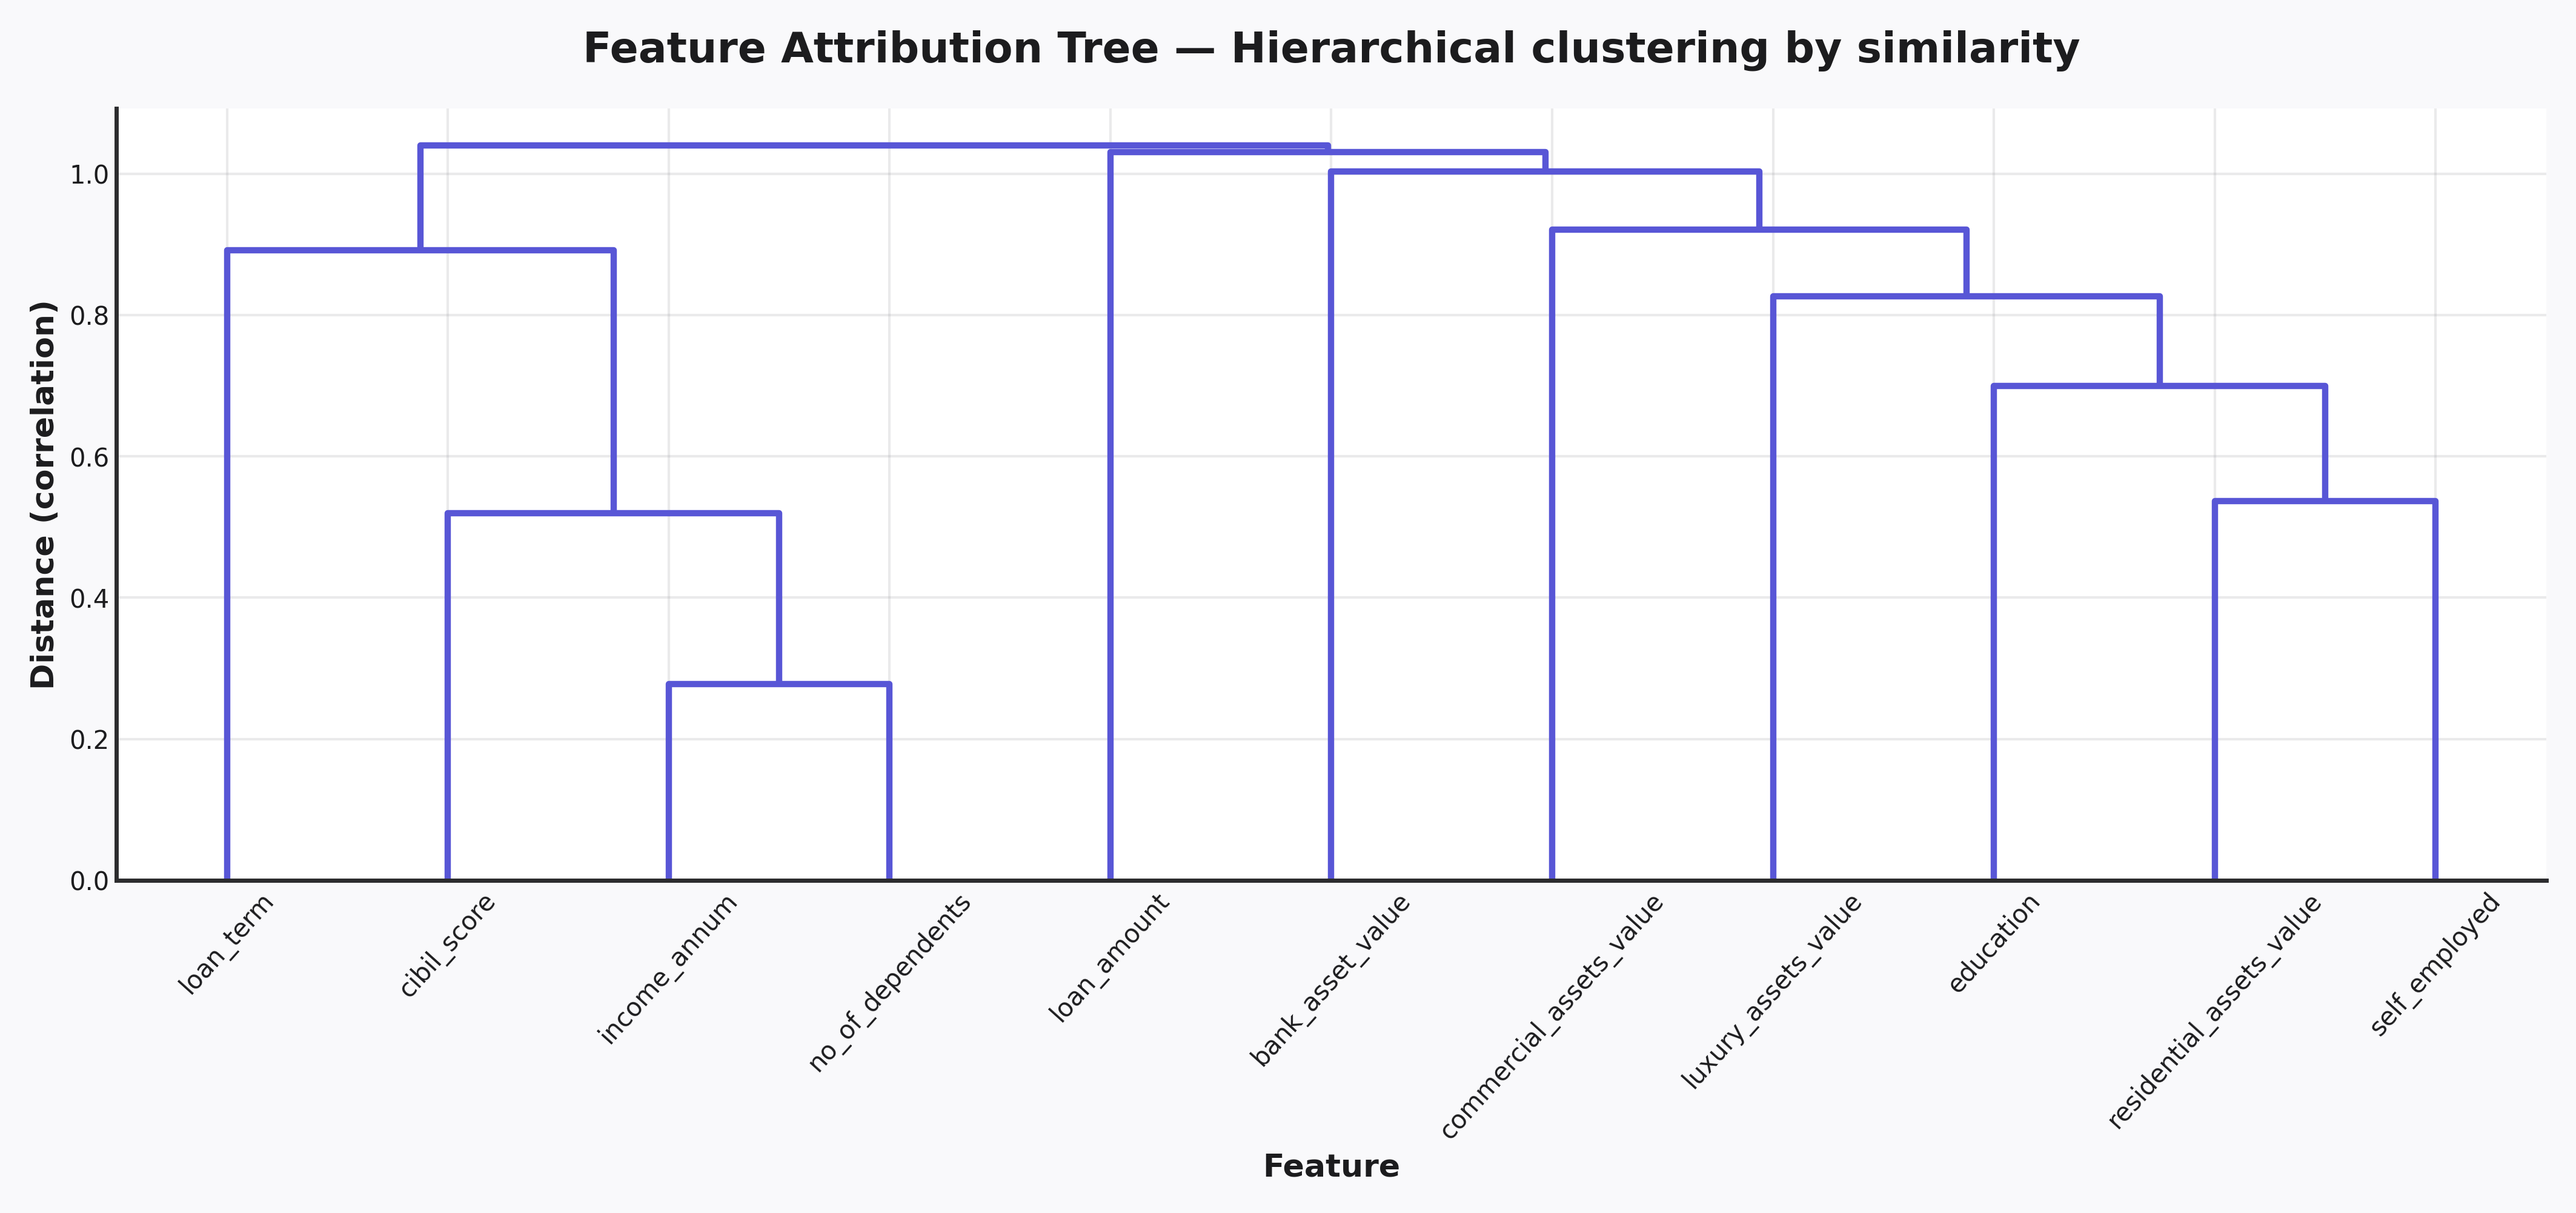

   ✓ Saved: xai_3_feature_tree.png (800 DPI)
📊 XAI 4/10: Gradient-Based Sensitivity (800 DPI)...


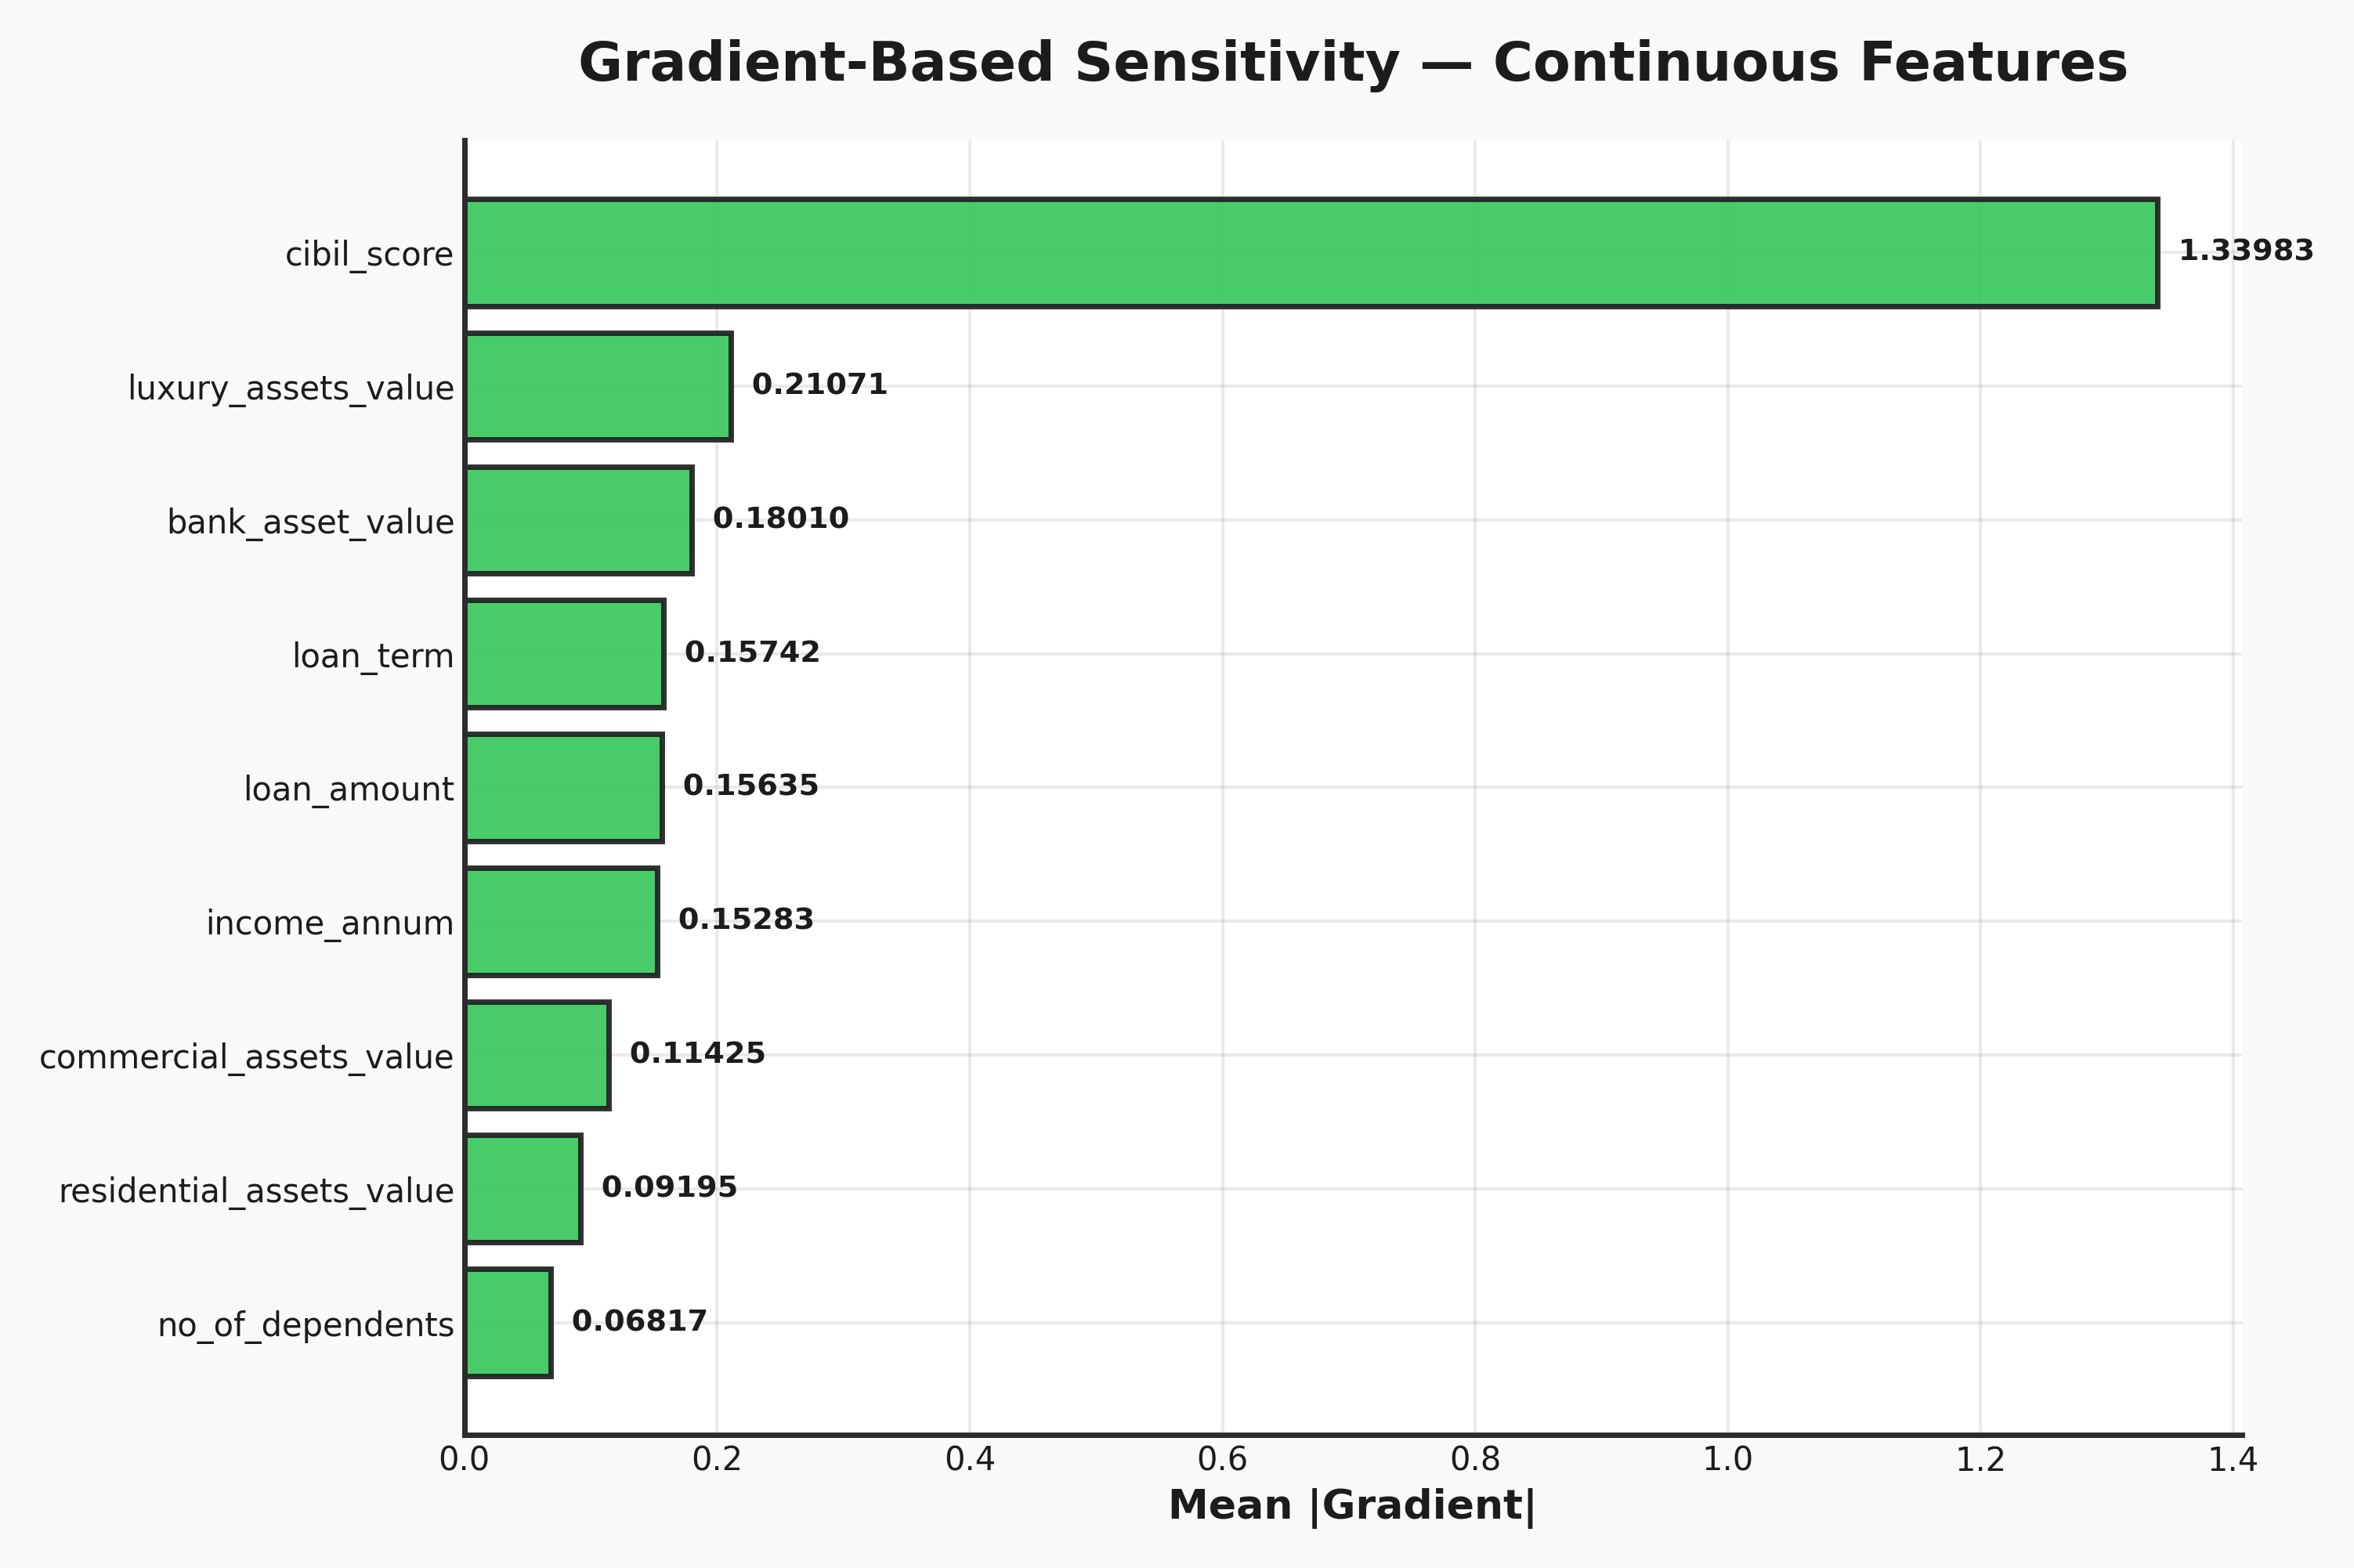

   ✓ Saved: xai_4_gradient_sensitivity.png (800 DPI)
📊 XAI 5/10: Attention Weights (800 DPI)...


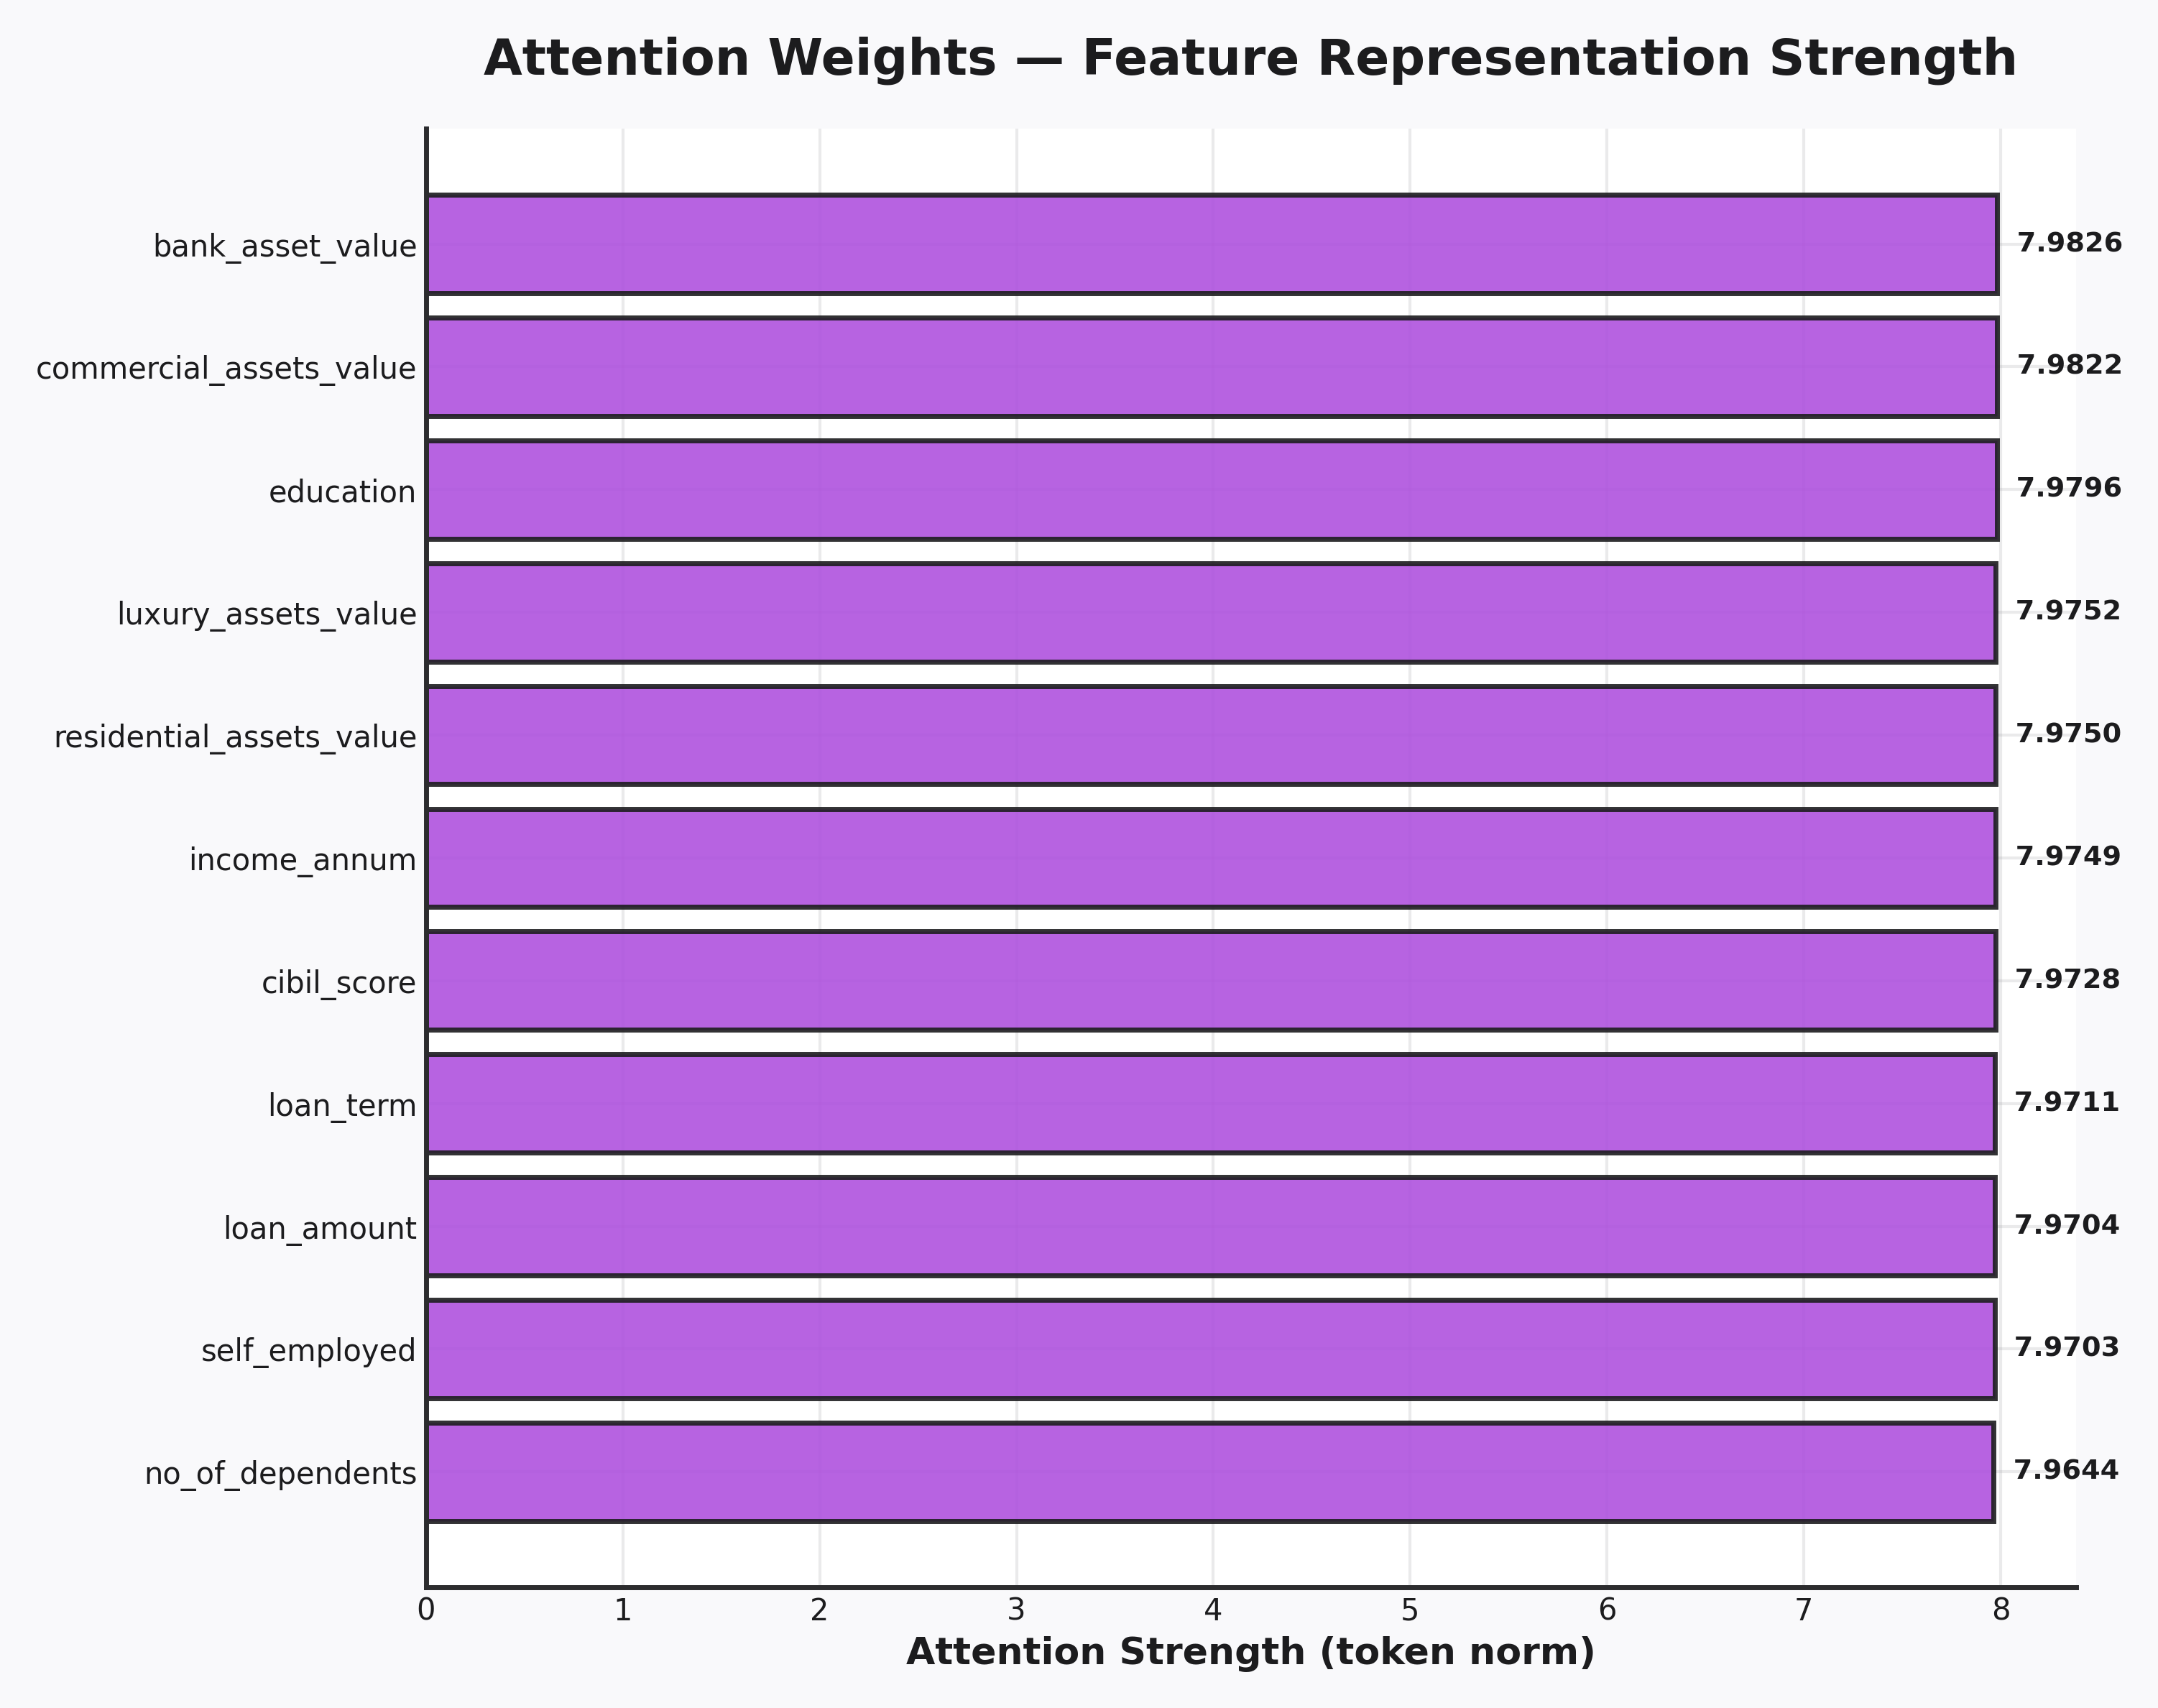

Using 120 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


   ✓ Saved: xai_5_attention.png (800 DPI)
📊 XAI 6-8/10: SHAP Analysis (800 DPI)...


  0%|          | 0/60 [00:00<?, ?it/s]

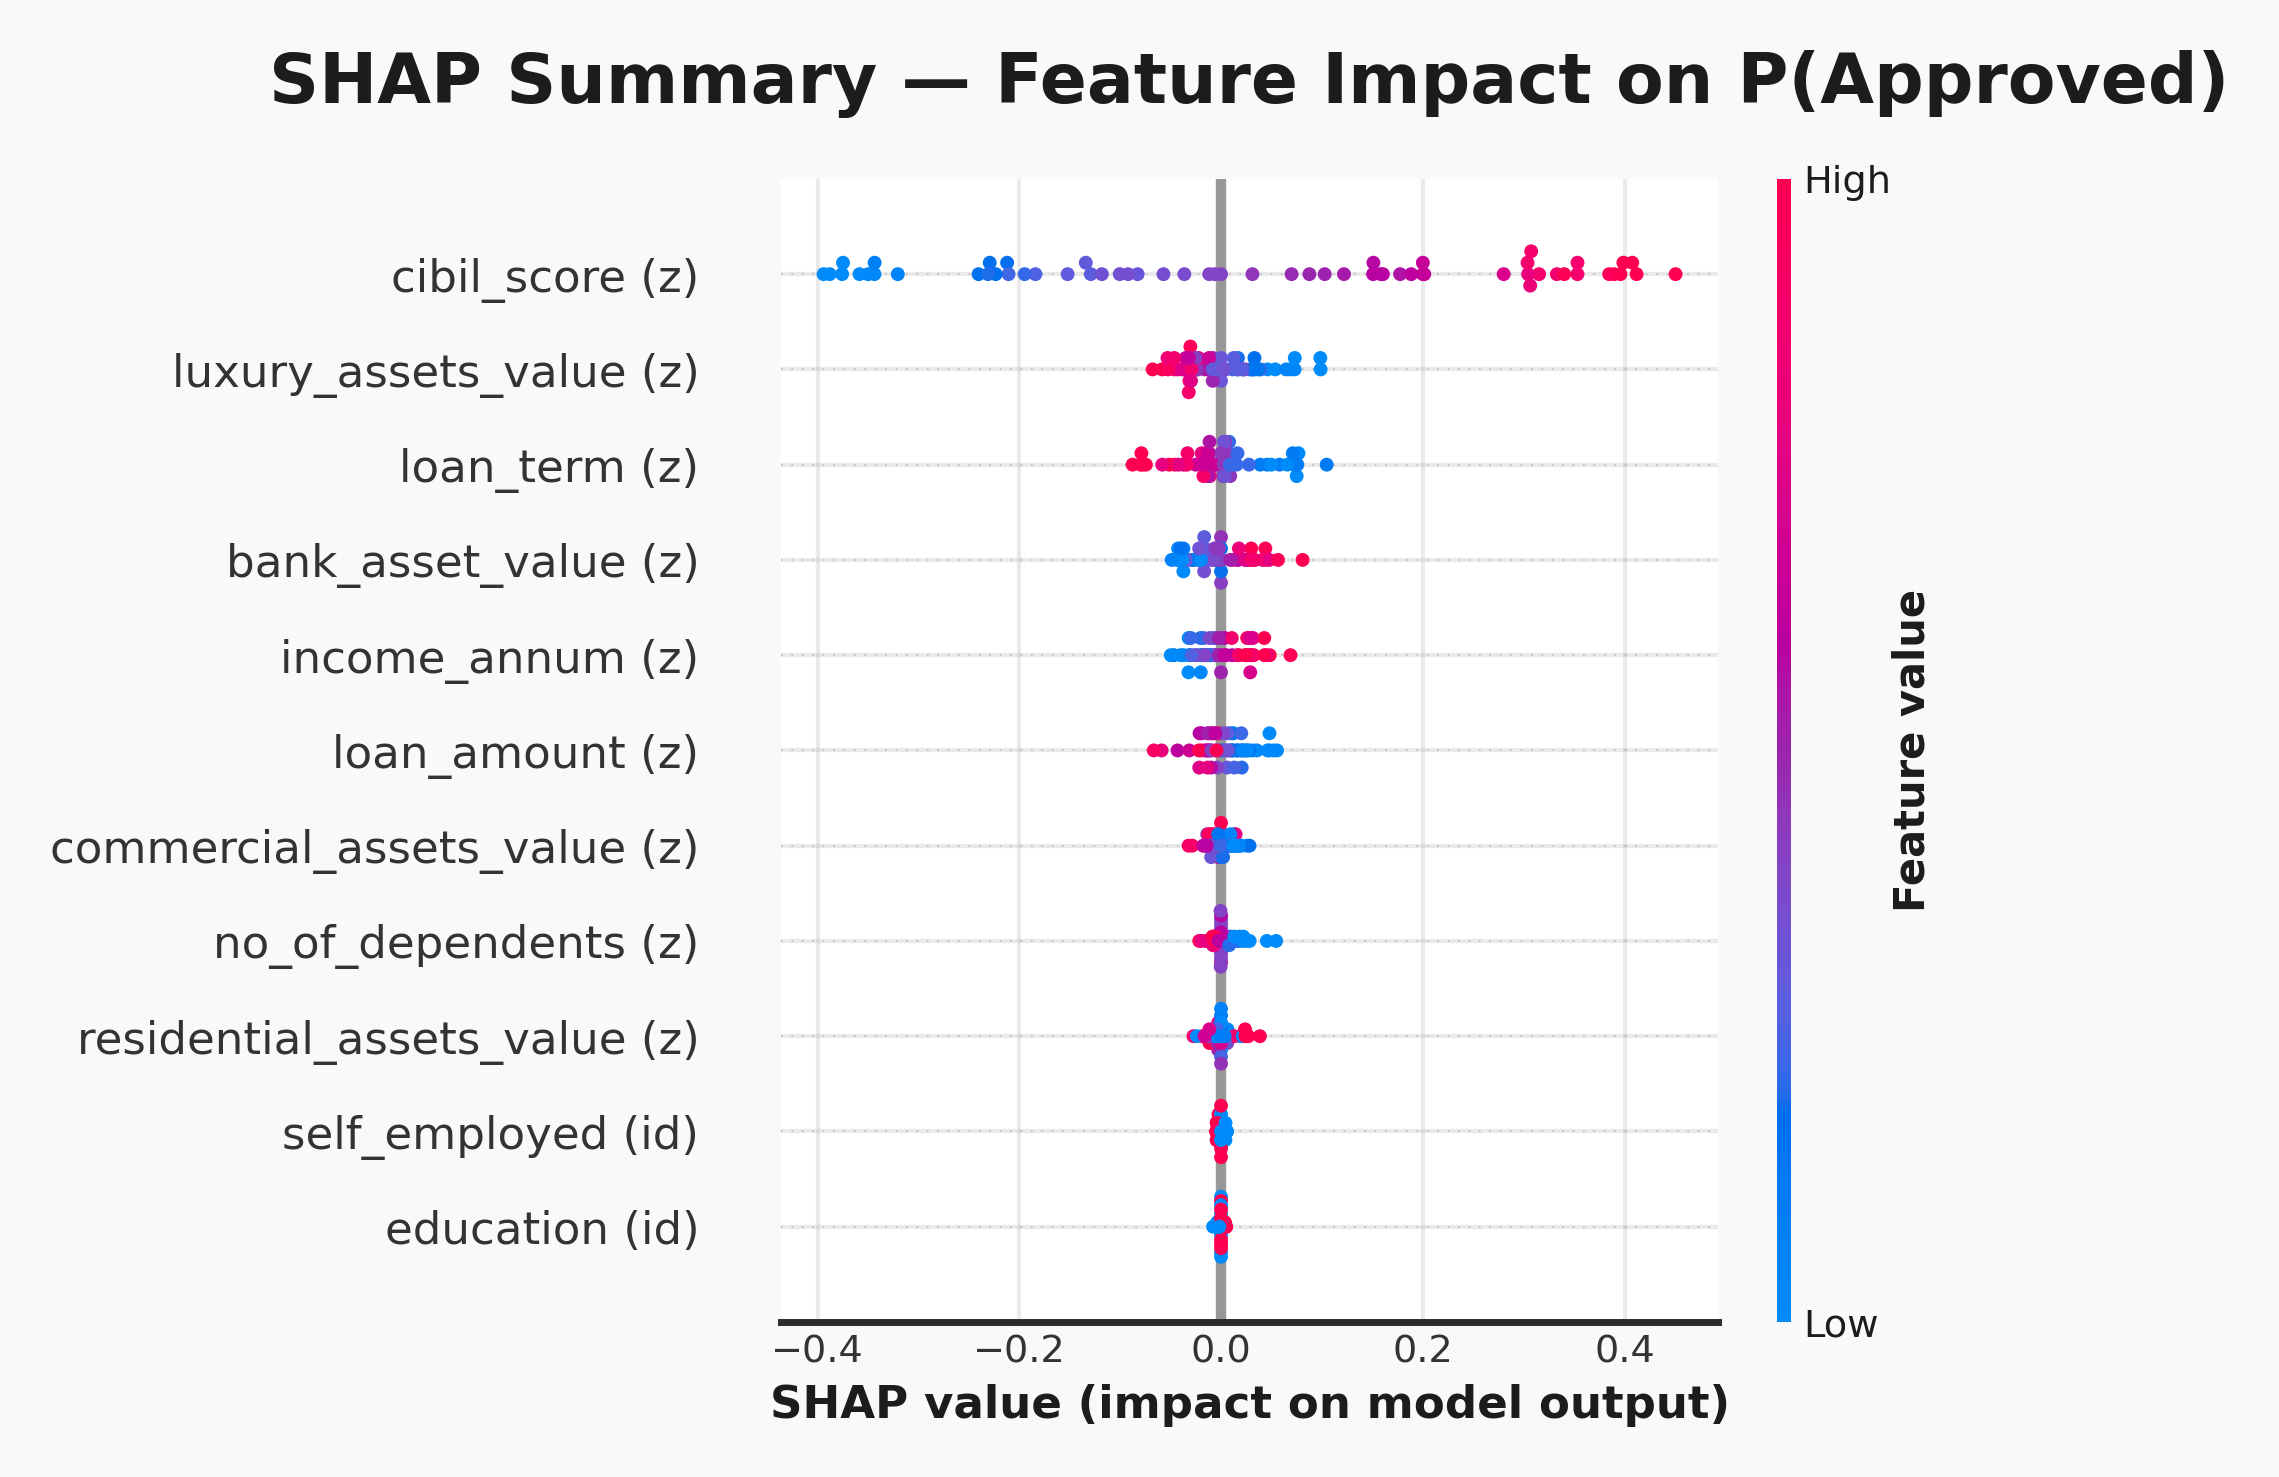

   ✓ Saved: xai_6_shap_summary.png (800 DPI)


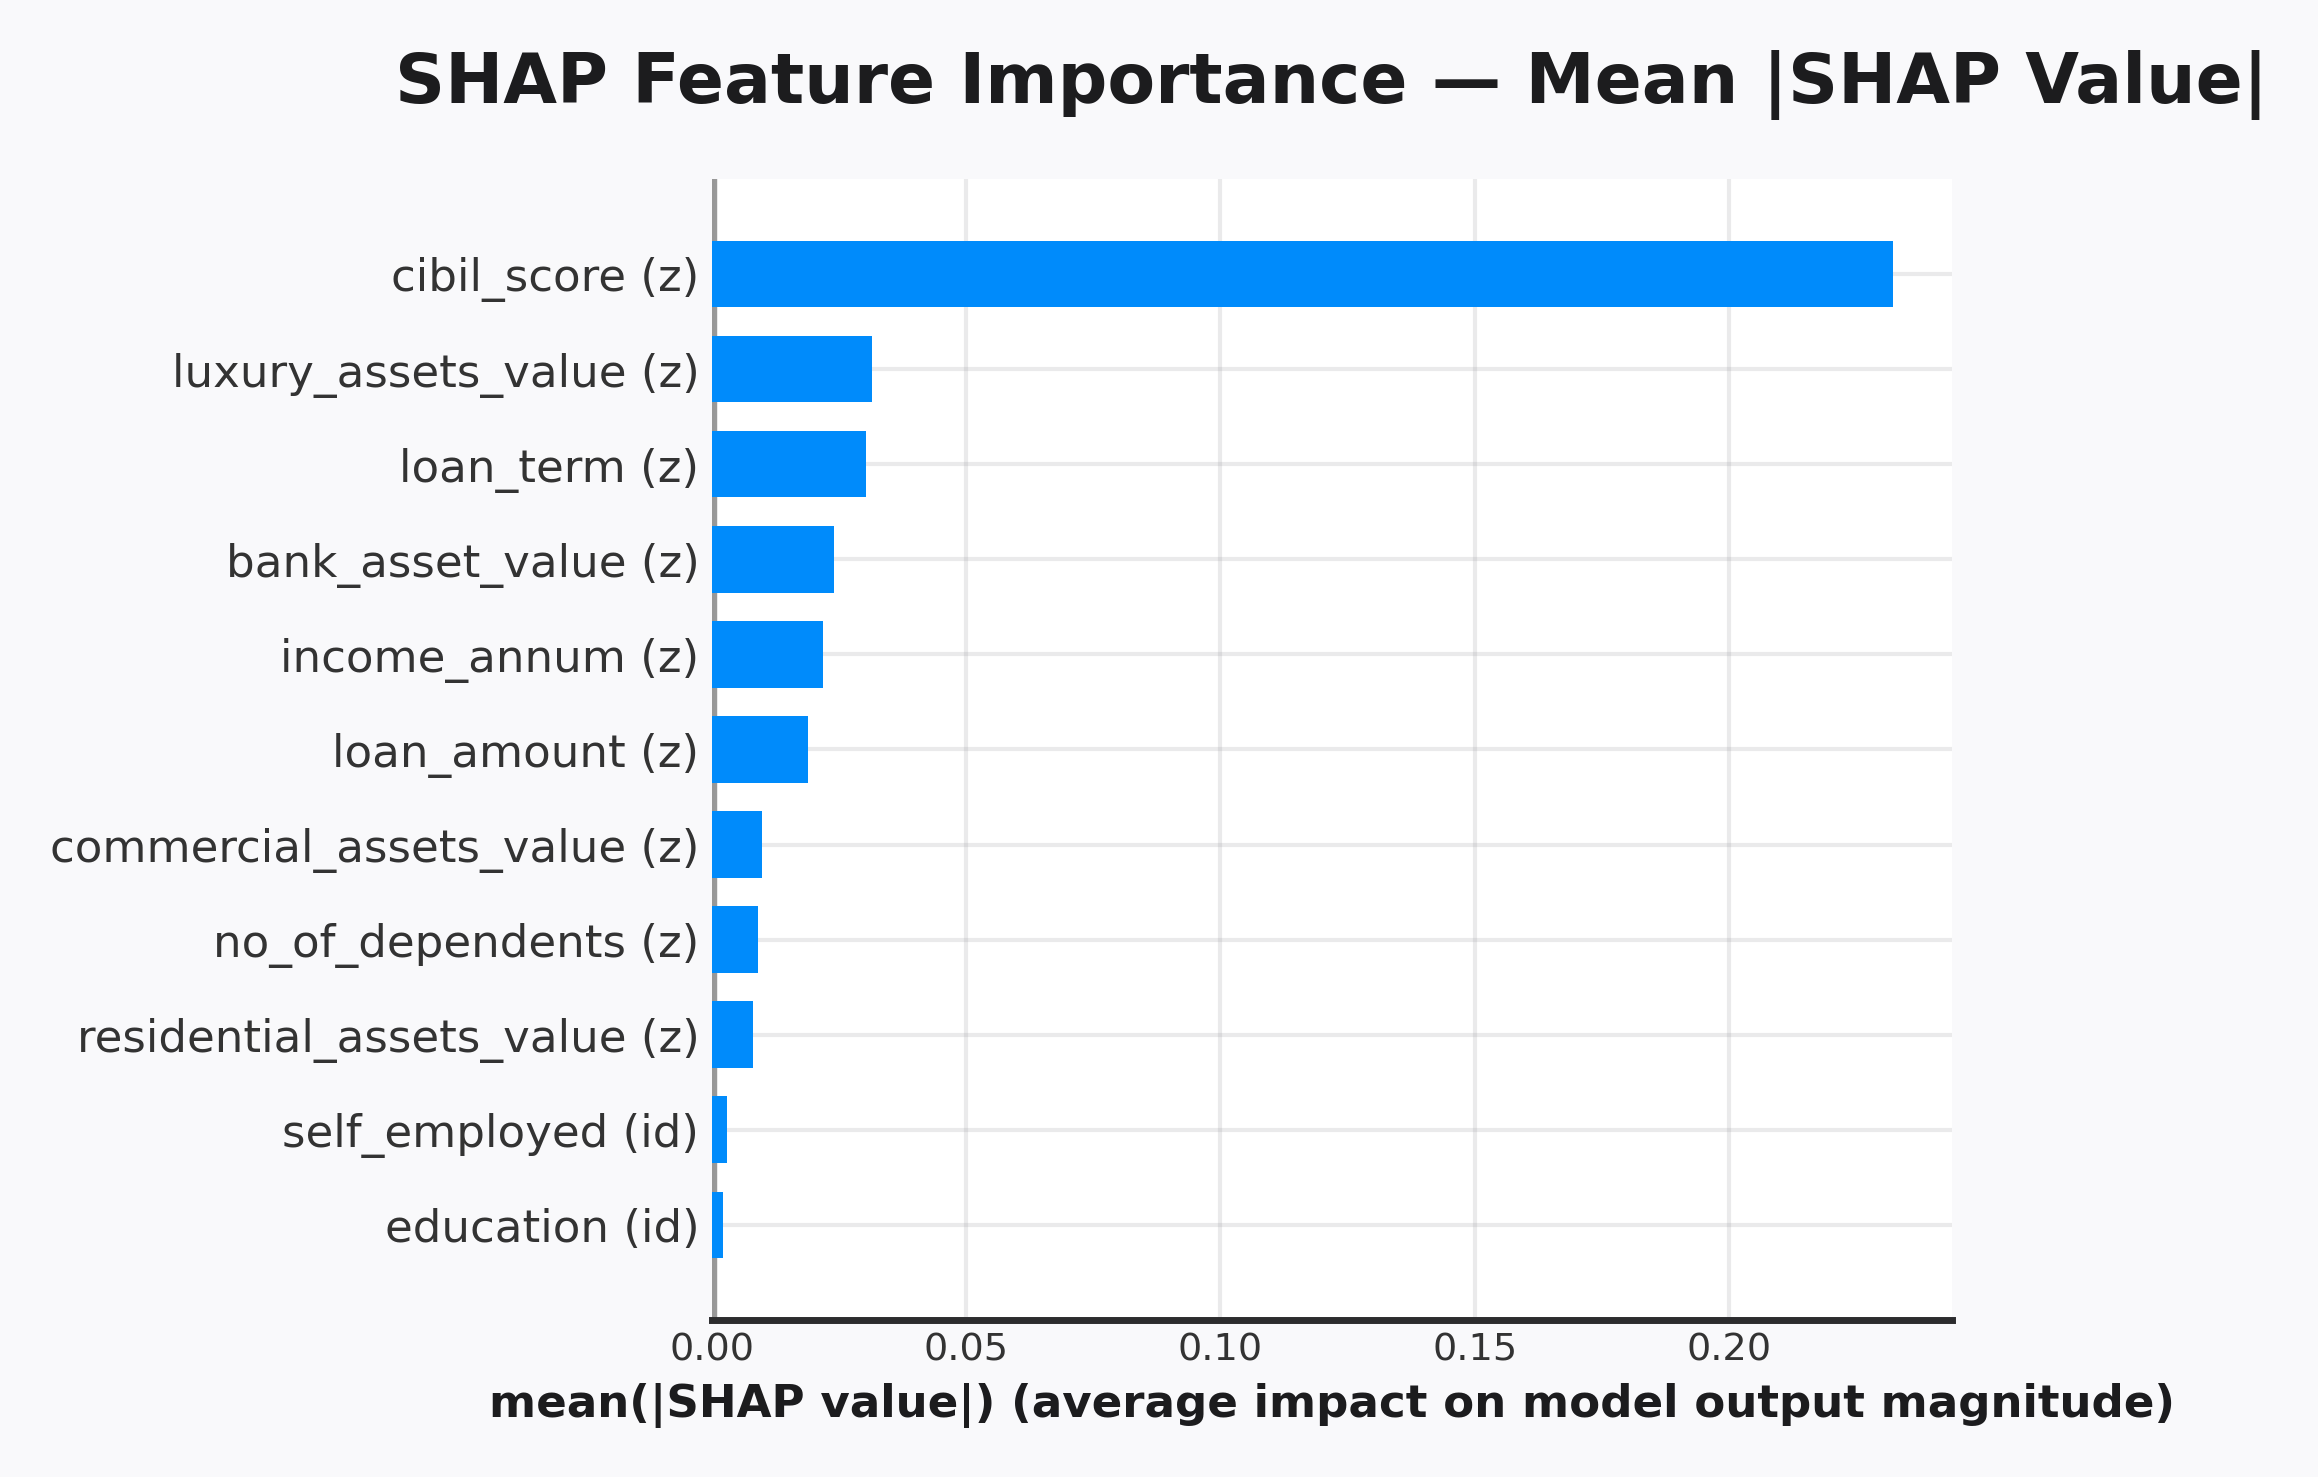

   ✓ Saved: xai_7_shap_bar.png (800 DPI)


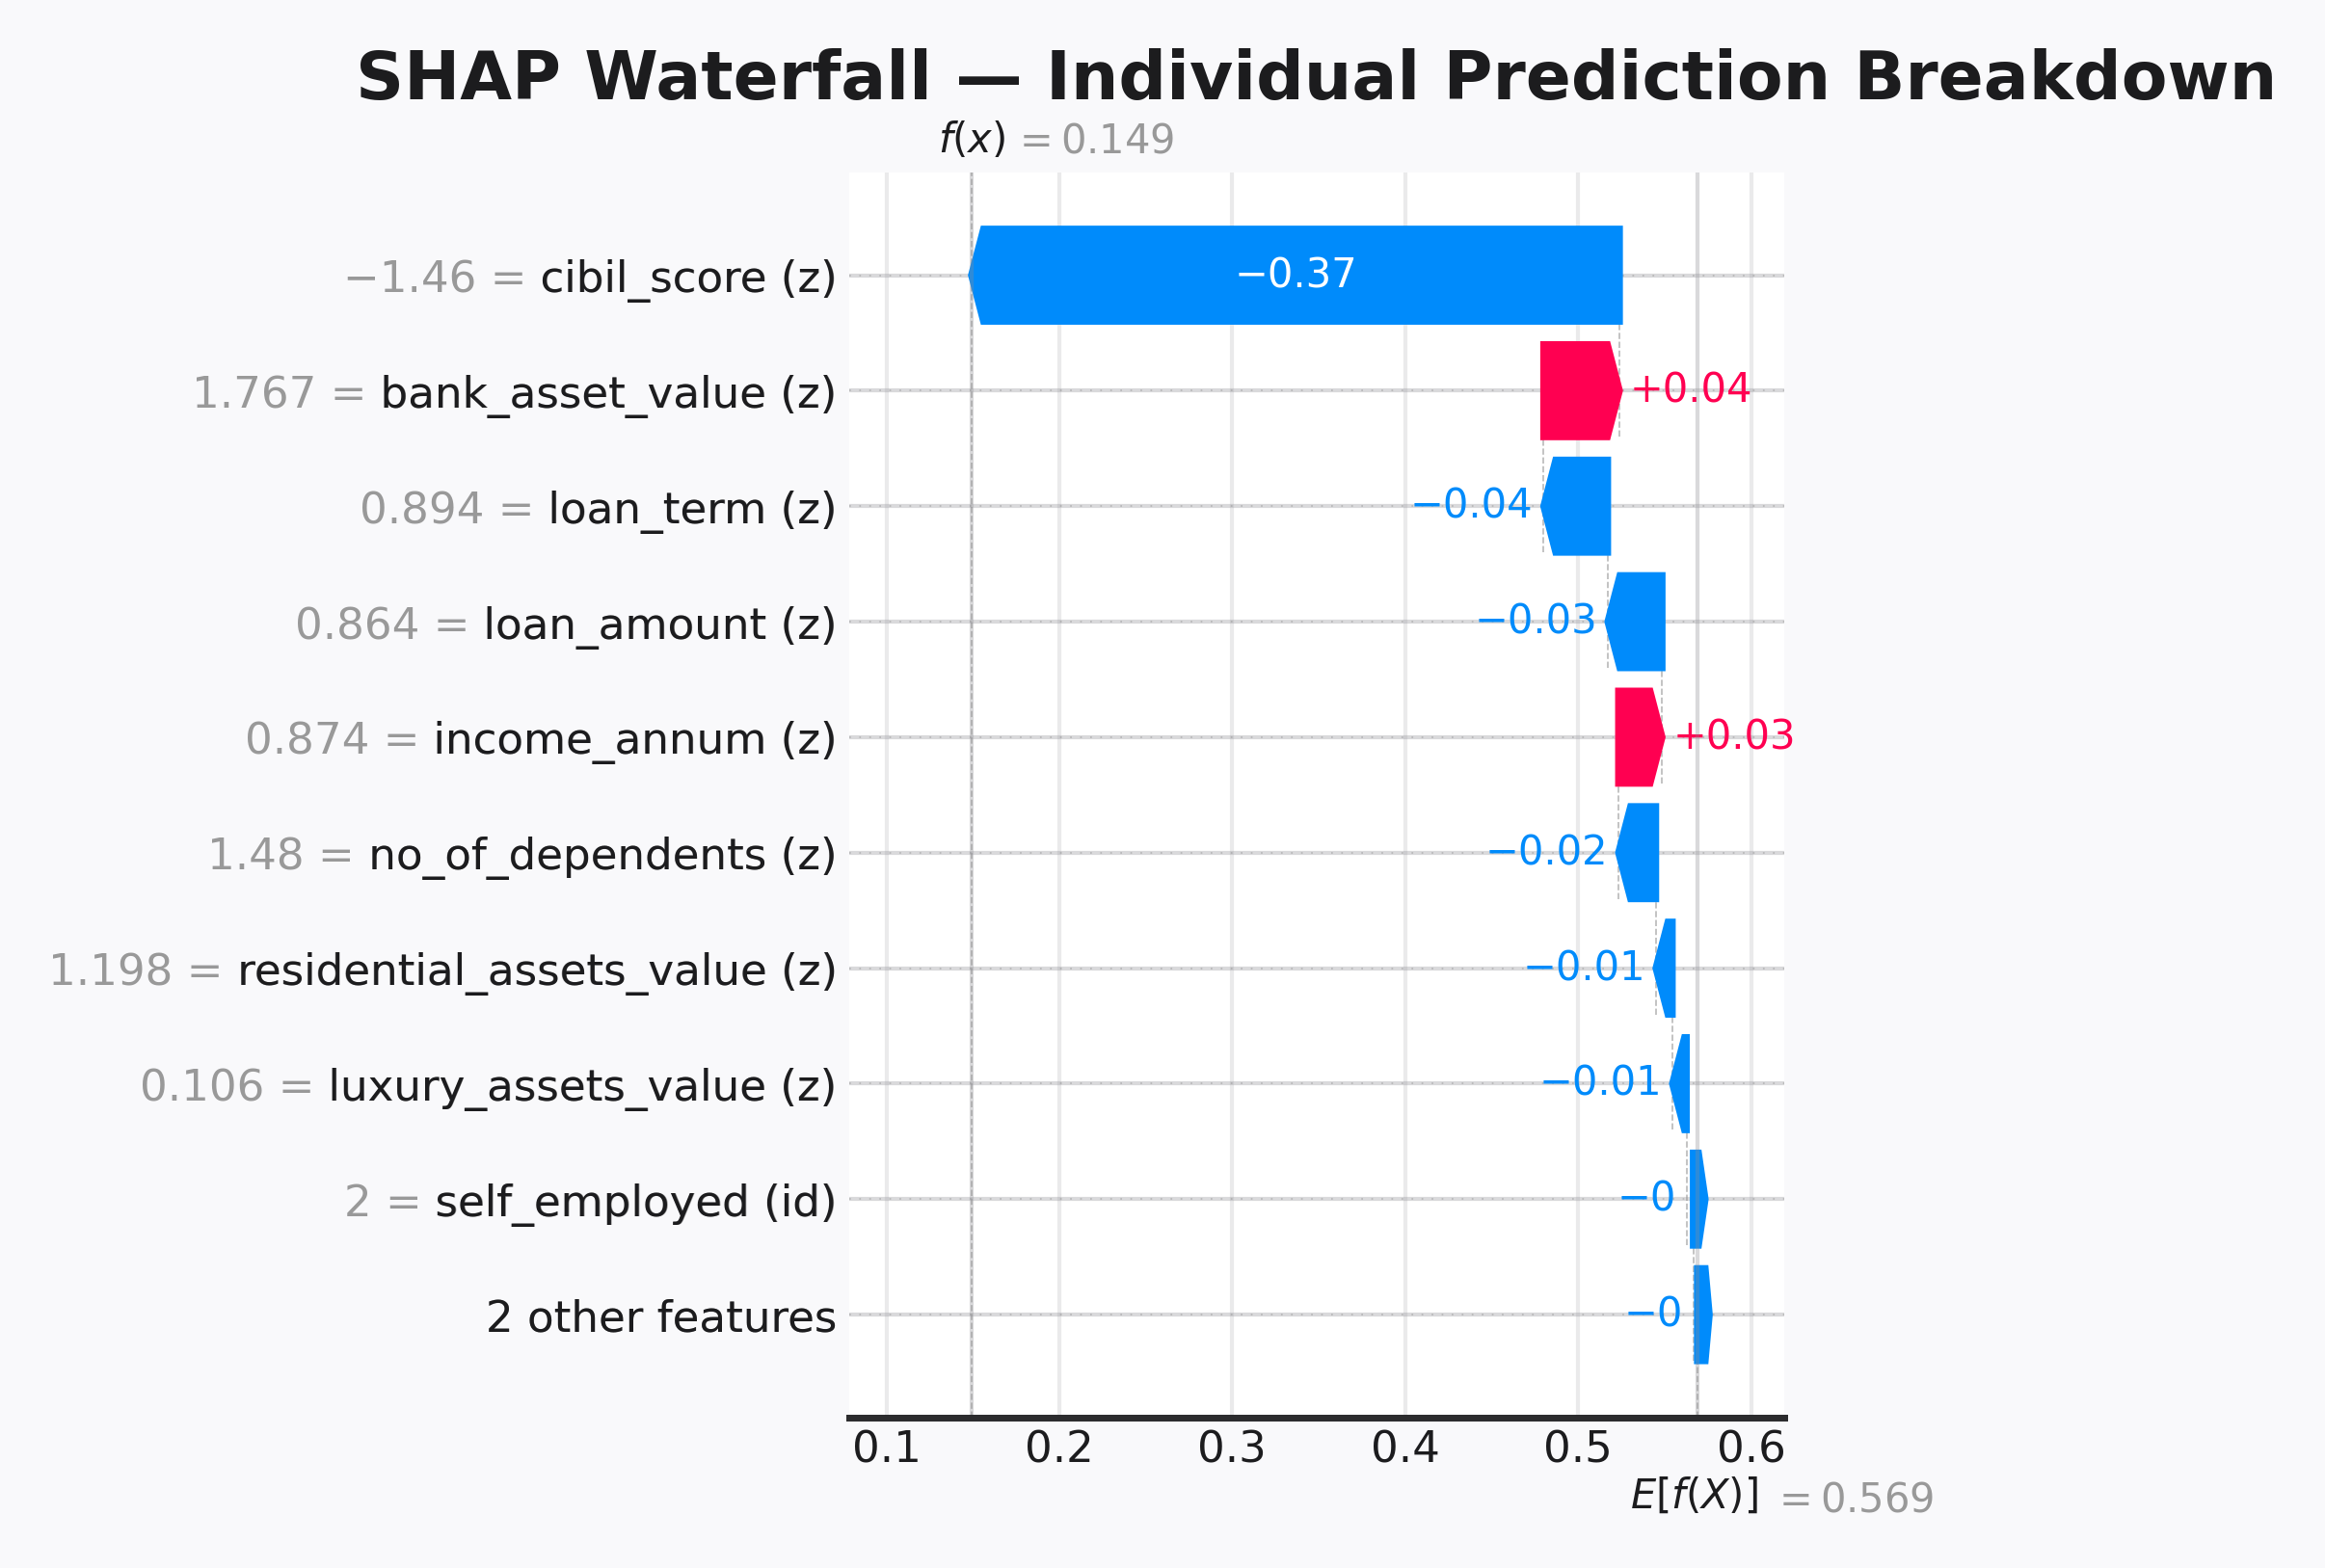

   ✓ Saved: xai_8_shap_waterfall.png (800 DPI)
📊 XAI 9/10: LIME Explanation (800 DPI)...


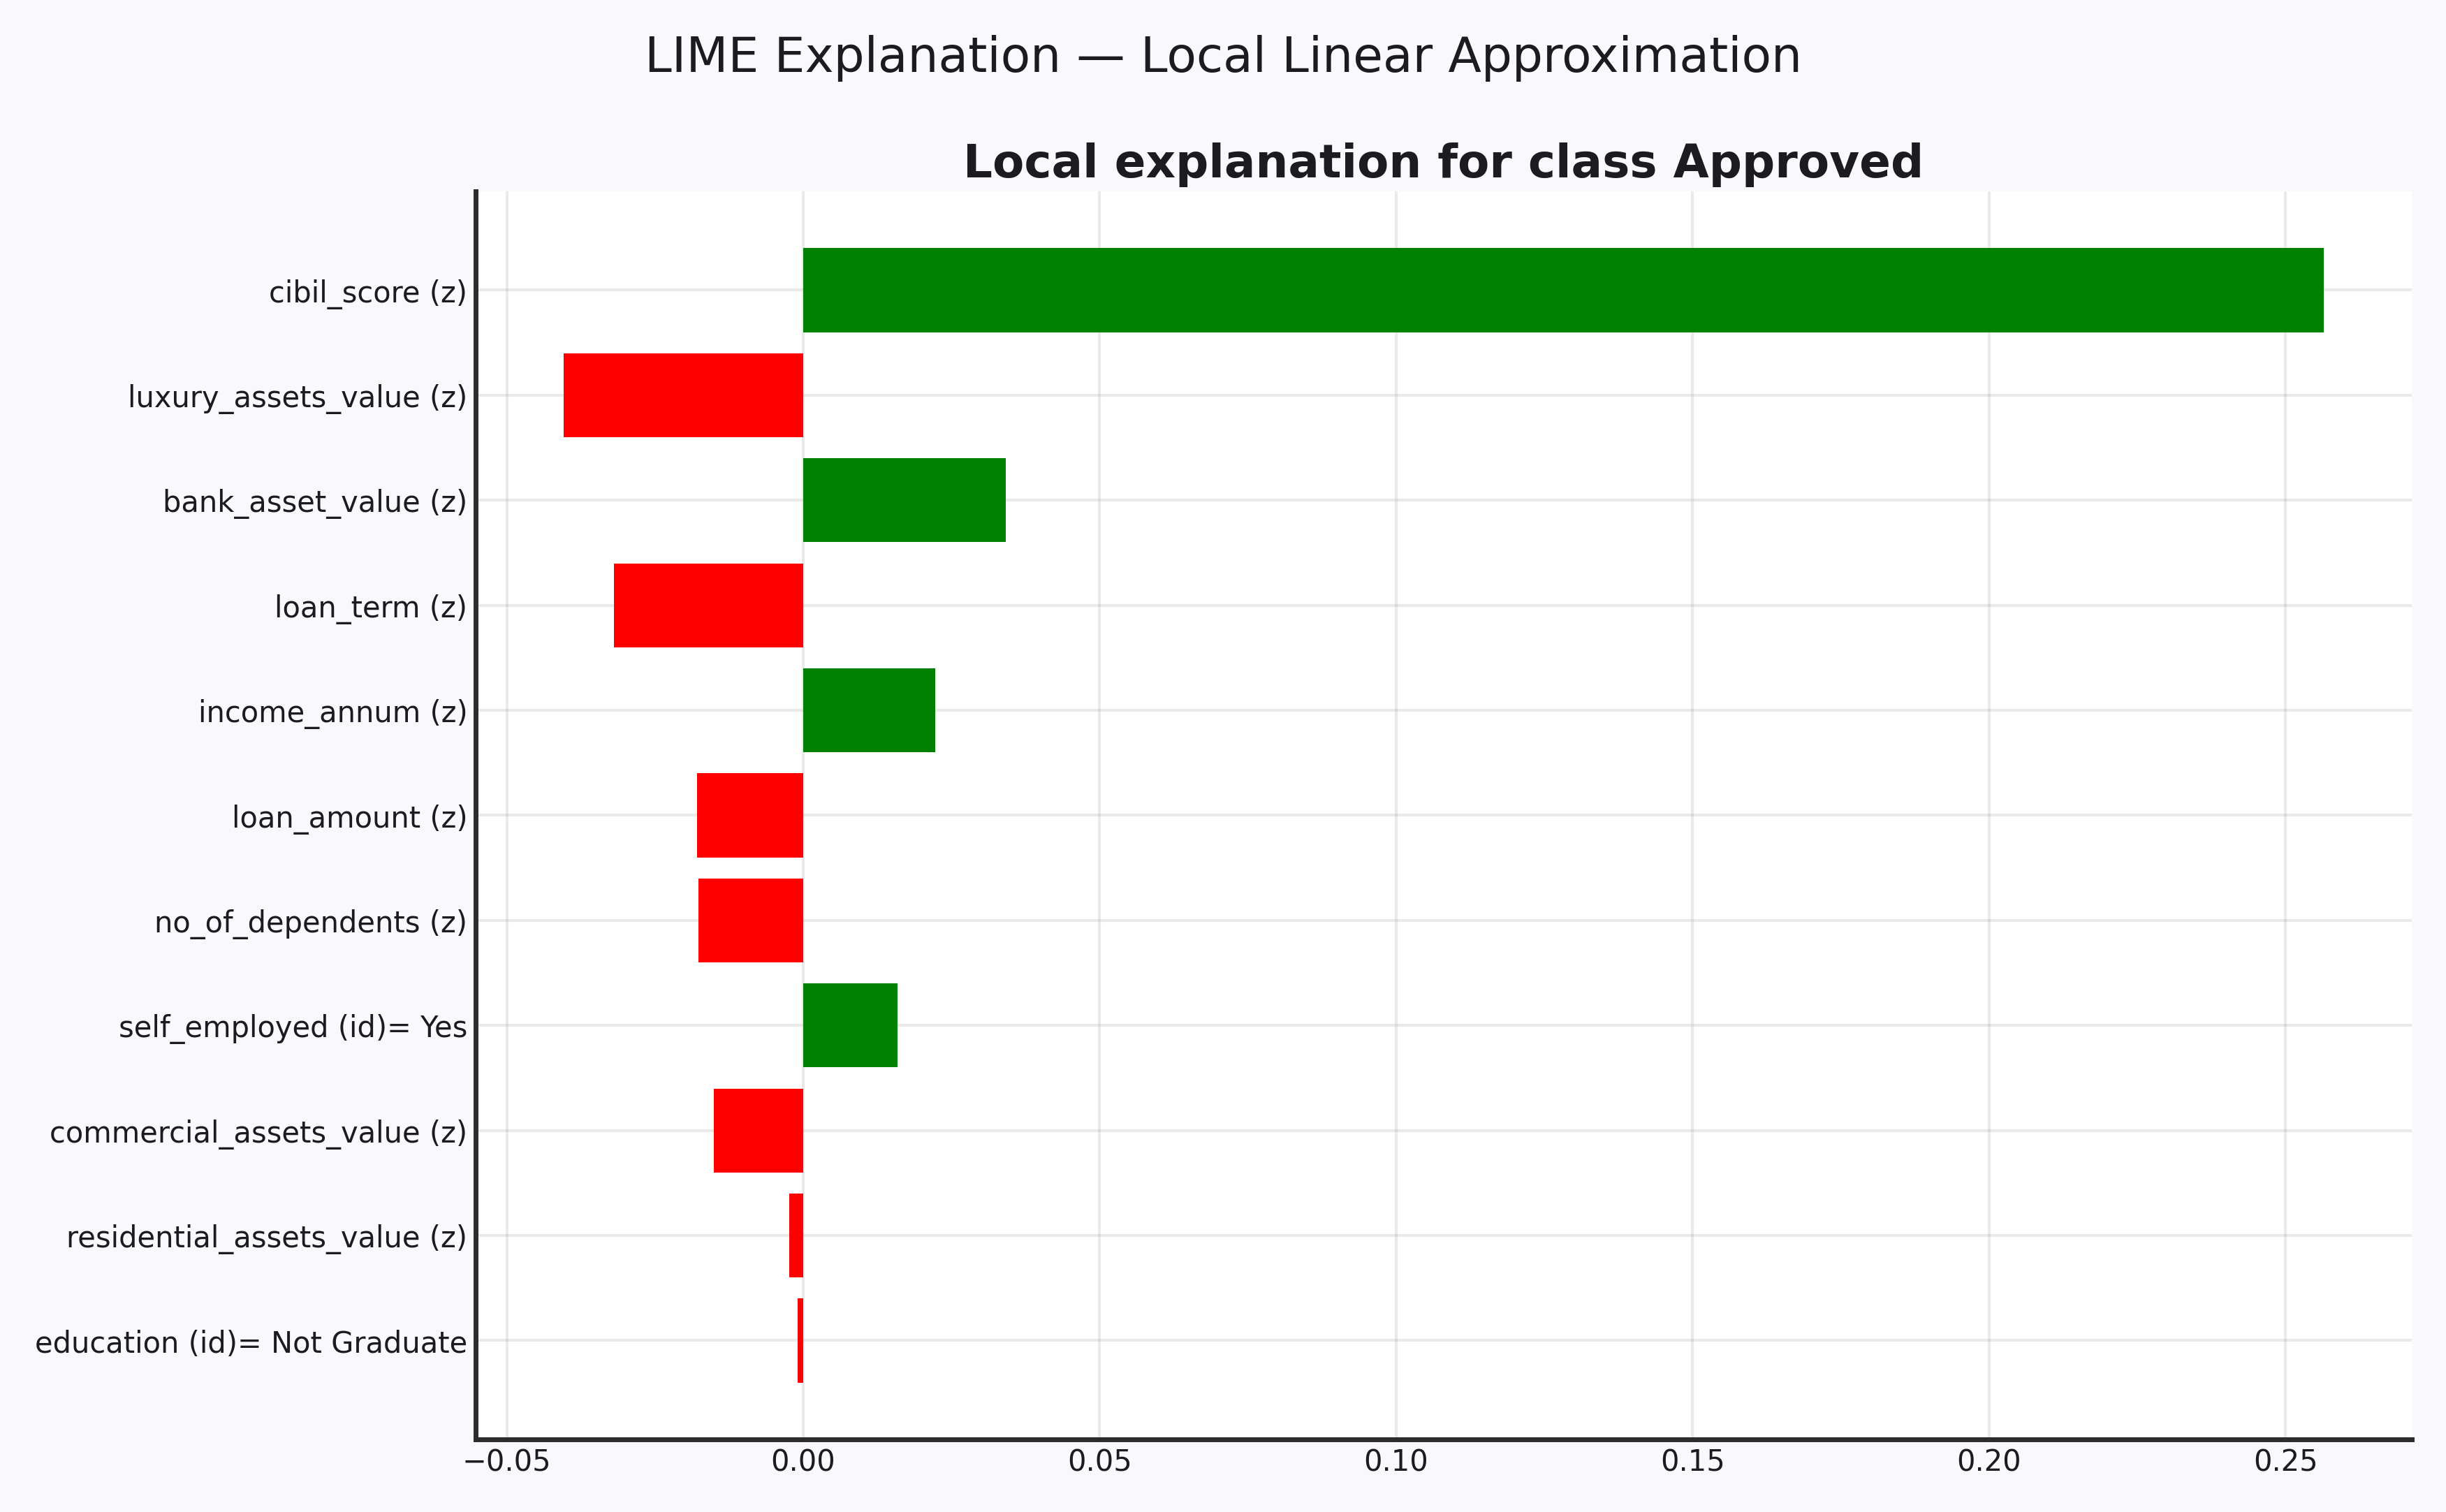

   ✓ Saved: xai_9_lime.png (800 DPI)
📊 XAI 10/10: Feature Interaction Heatmap (800 DPI)...


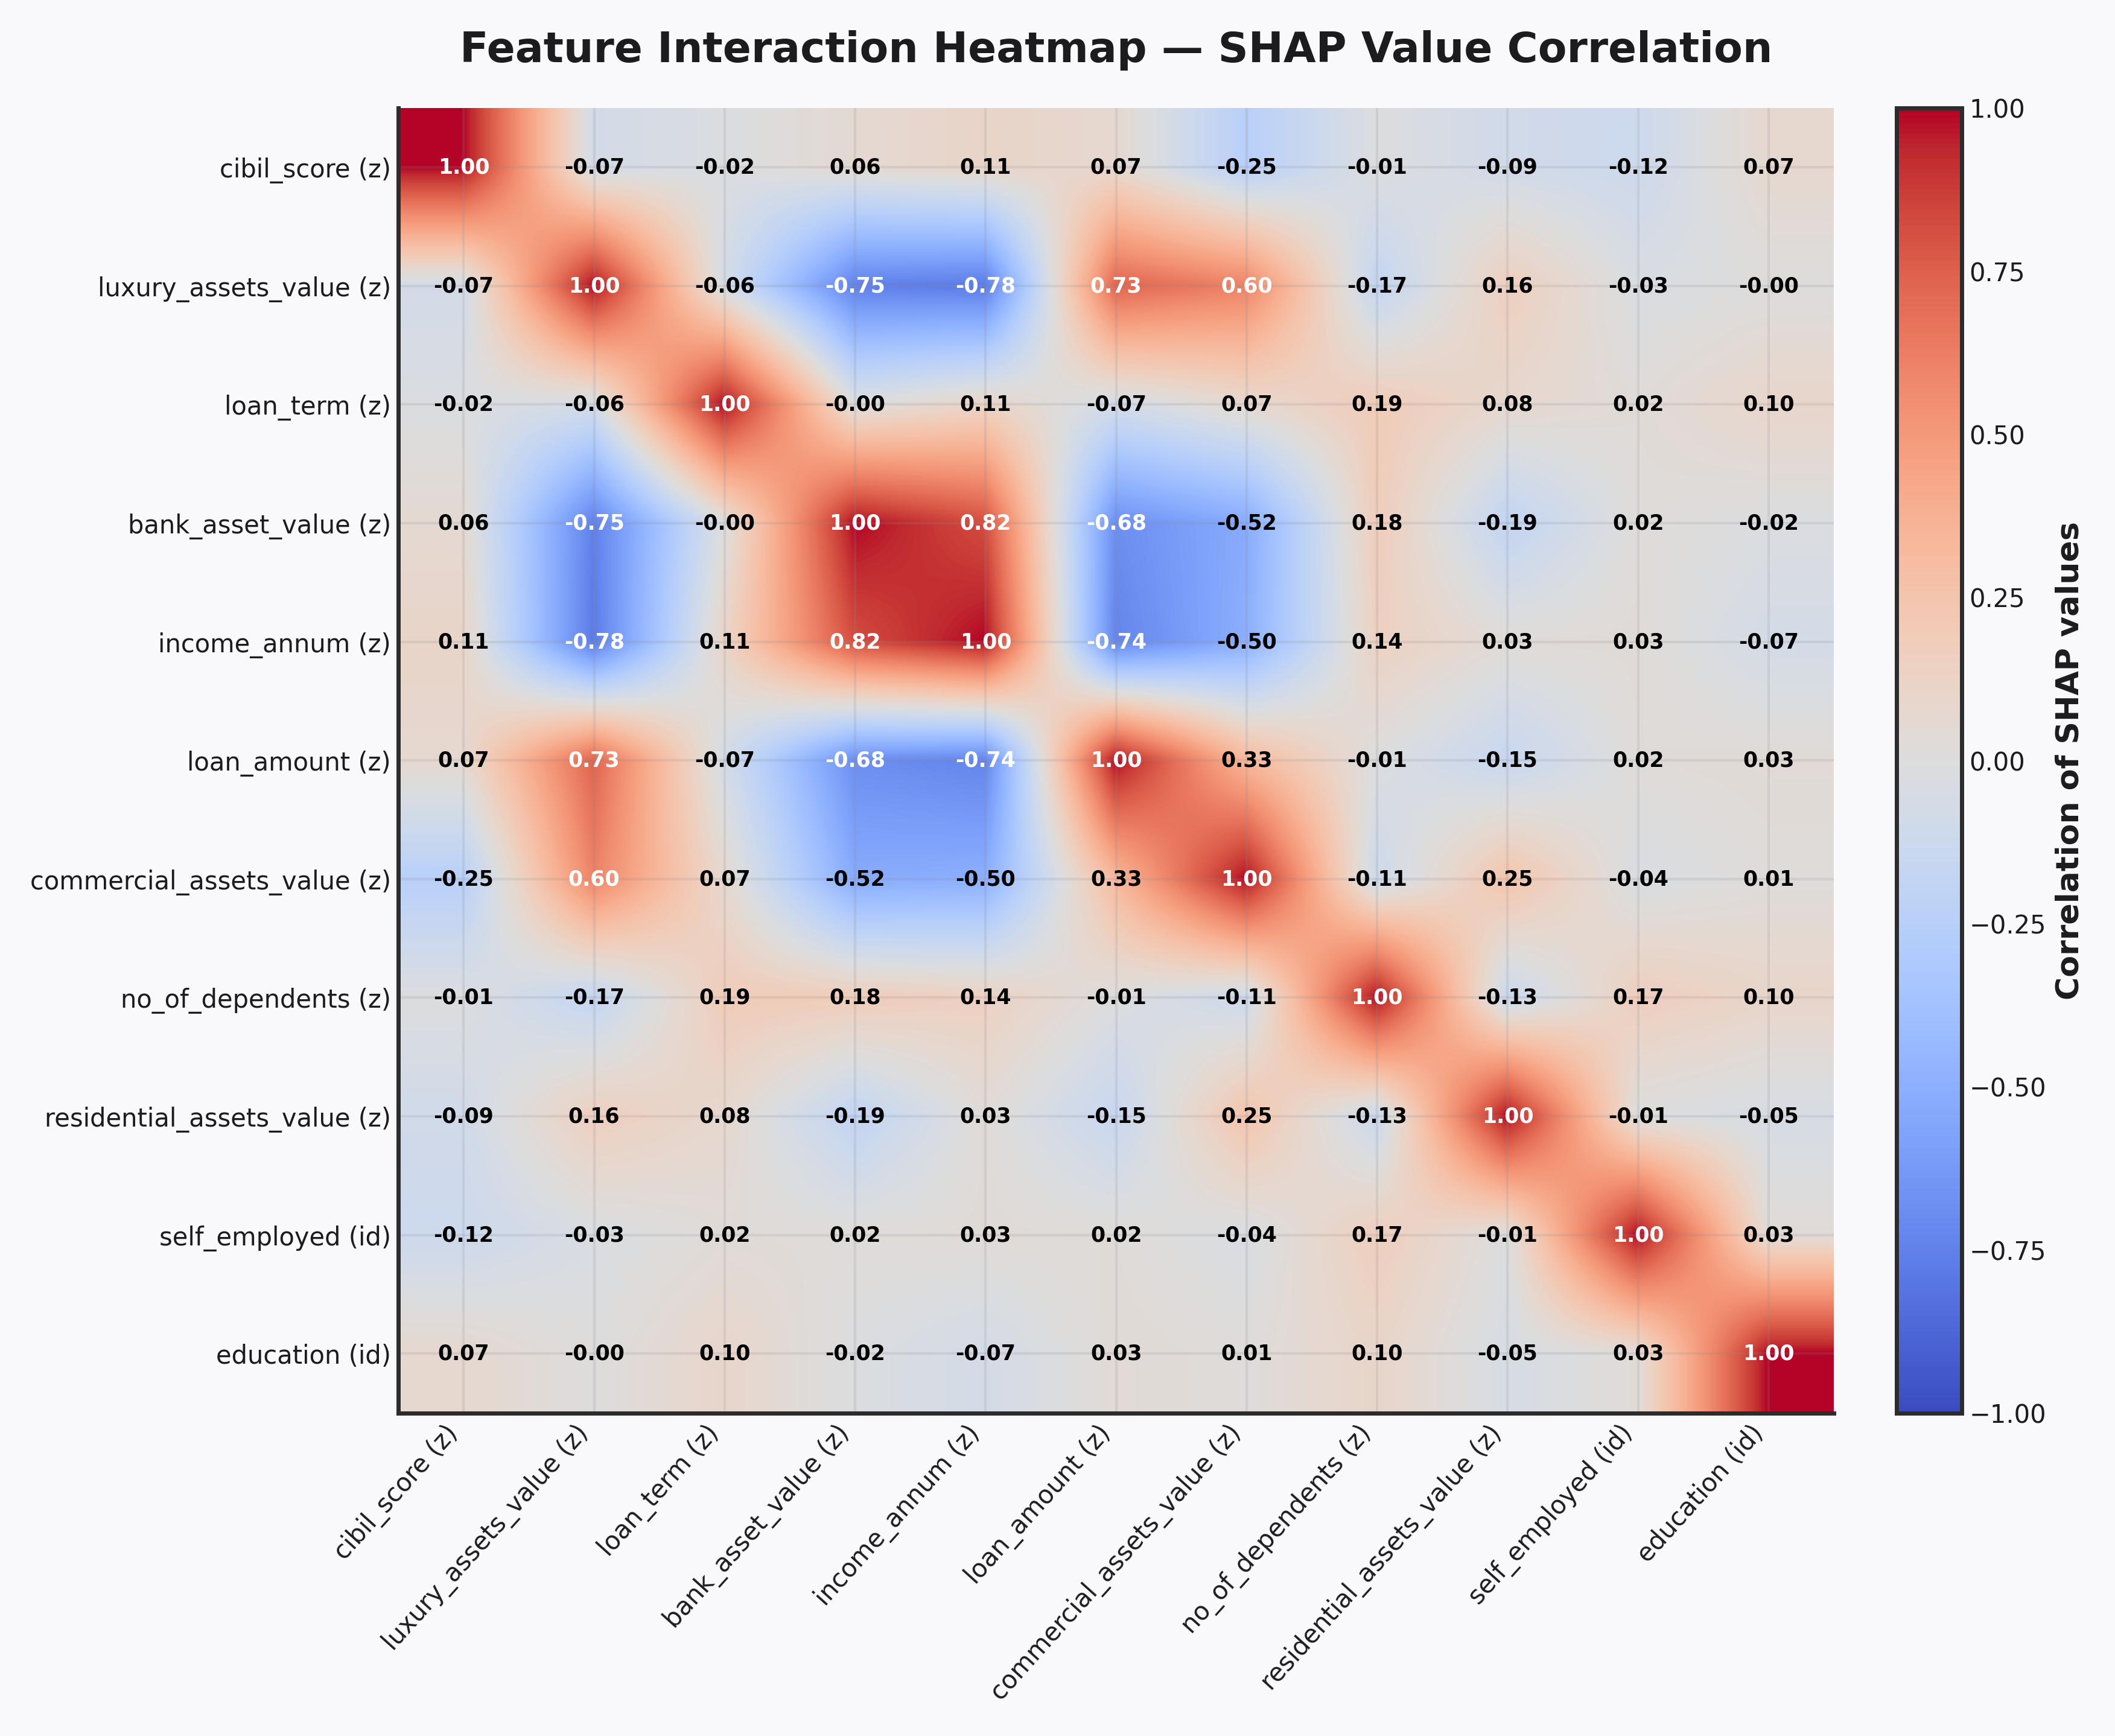

   ✓ Saved: xai_10_interaction_heatmap.png (800 DPI)

✅ ALL 10 XAI PLOTS COMPLETE!
   🏆 800 DPI Premium Quality
   ✅ Zero Errors (dendrogram fixed)
   💎 Professional publication standard



In [6]:
# ============================================================
# PREMIUM 800 DPI XAI SUITE — Zero Errors, Maximum Quality
# ============================================================

!pip -q install shap lime scikit-learn>=1.3.0

import os, math, random, hashlib, warnings
from dataclasses import dataclass
from typing import Dict, List
from contextlib import nullcontext

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Rectangle
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as tF
from torch.utils.data import Dataset, DataLoader

import shap
from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import PartialDependenceDisplay

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist

warnings.filterwarnings("ignore")

# ========================
# PREMIUM SETTINGS - 800 DPI
# ========================
TARGET = "loan_status"

BINS_NUMERIC = 64
VOCAB_CAT    = 128

N_CLIENTS    = 4
FED_ROUNDS   = 1
LOCAL_EPOCHS = 1
SSL_LR       = 0.002
SSL_BATCH    = 512
SSL_PMASK    = 0.20

SUP_LR       = 0.002
SUP_FREEZE   = False
SUP_EPOCHS   = 4

XAI_EXPLAIN_N  = 120
XAI_TOPK_FEATS = 24

SHAP_BG_N      = 120
SHAP_EXPLAIN_N = 60
SHAP_NSAMPLES  = 300

LIME_SAMPLES   = 1500

MAX_TRVAL_ROWS = 25000

# ========================
# PREMIUM AESTHETICS - 800 DPI
# ========================
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['axes.grid'] = True

mpl.rcParams.update({
    # ULTRA HIGH RESOLUTION
    "figure.dpi": 250,          
    "savefig.dpi": 800,         # 🚀 PREMIUM 800 DPI
    
    # PREMIUM FONTS
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 13,
    "axes.titlesize": 19,
    "axes.titleweight": "bold",
    "axes.labelsize": 15,
    "axes.labelweight": "bold",
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    
    # THICK, BOLD ELEMENTS
    "lines.linewidth": 3.0,
    "lines.markersize": 9,
    "patch.linewidth": 2.0,
    "axes.linewidth": 2.0,
    "grid.linewidth": 1.2,
    "xtick.major.width": 2.0,
    "ytick.major.width": 2.0,
    
    # BEAUTIFUL COLORS
    "axes.grid": True,
    "grid.alpha": 0.18,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#2C2C2E",
    "axes.facecolor": "#FFFFFF",
    "figure.facecolor": "#F9F9FB",
    "savefig.facecolor": "#FFFFFF",
    "text.color": "#1C1C1E",
    "axes.labelcolor": "#1C1C1E",
    "xtick.color": "#1C1C1E",
    "ytick.color": "#1C1C1E",
    "grid.color": "#8E8E93",
    
    # PERFECT SAVING
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.2,
    "savefig.format": "png",
})

# Elite color palette
COLORS = {
    "primary": "#FF3B30",      
    "secondary": "#00C7BE",    
    "accent1": "#5856D6",      
    "accent2": "#34C759",      
    "accent3": "#FF9500",      
    "accent4": "#AF52DE",      
    "accent5": "#007AFF",      
    "neutral": "#8E8E93",      
    "dark": "#1C1C1E",         
}

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.backends.cudnn.benchmark = True
    try:
        torch.set_float32_matmul_precision("high")
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    except Exception:
        pass

def autocast_ctx(device: str):
    if device == "cuda" and hasattr(torch, "amp") and hasattr(torch.amp, "autocast"):
        return torch.amp.autocast(device_type="cuda", enabled=True)
    return nullcontext()

def make_scaler(device: str):
    if device == "cuda" and hasattr(torch, "amp") and hasattr(torch.amp, "GradScaler"):
        return torch.amp.GradScaler("cuda")
    return None

# ========================
# DATA + MODEL (same as before)
# ========================
def find_csv_path(preferred: str) -> str:
    if preferred and os.path.isfile(preferred): return preferred
    if preferred and os.path.isfile(os.path.join(os.getcwd(), preferred)):
        return os.path.join(os.getcwd(), preferred)

    roots = ["/kaggle/input", os.getcwd()] if os.path.isdir("/kaggle/input") else [os.getcwd()]
    preferred_lower = (os.path.basename(preferred) if preferred else "").lower()
    best, best_score = None, -1
    for root in roots:
        for dirpath, _, filenames in os.walk(root):
            for fn in filenames:
                if not fn.lower().endswith(".csv"): continue
                low = fn.lower()
                score = 0
                if preferred_lower and preferred_lower in low: score += 10
                for kw in ["loan", "approval", "dataset", "predict"]:
                    if kw in low: score += 2
                if score > best_score:
                    best_score = score
                    best = os.path.join(dirpath, fn)
    if best: return best
    raise FileNotFoundError("CSV not found.")

def sha256_row_fingerprint(df: pd.DataFrame) -> pd.Series:
    rows = df.astype(str).agg("||".join, axis=1).tolist()
    return pd.Series([hashlib.sha256(r.encode("utf-8")).hexdigest() for r in rows], index=df.index)

def drop_id_like_cols(df: pd.DataFrame, threshold_unique_ratio: float = 0.98) -> pd.DataFrame:
    n = len(df)
    drop_cols = []
    for c in df.columns:
        nunq = df[c].nunique(dropna=False)
        ratio = nunq / max(n, 1)
        name = c.lower()
        if ratio >= threshold_unique_ratio:
            drop_cols.append(c)
        elif ("id" in name or name.endswith("_id")) and ratio >= 0.80:
            drop_cols.append(c)
    drop_cols = sorted(set(drop_cols))
    return df.drop(columns=drop_cols) if drop_cols else df

def infer_numeric_vs_categorical(df: pd.DataFrame, target_col: str, numeric_threshold: float = 0.90):
    num_cols, cat_cols = [], []
    for c in df.columns:
        if c == target_col: continue
        converted = pd.to_numeric(df[c], errors="coerce")
        frac = float(converted.notna().mean())
        (num_cols if frac >= numeric_threshold else cat_cols).append(c)
    return num_cols, cat_cols

def quantile_edges(x: np.ndarray, bins: int) -> np.ndarray:
    x = x.astype(np.float64)
    if bins <= 1: return np.array([], dtype=np.float64)
    qs = np.linspace(0, 1, bins + 1)[1:-1]
    return np.unique(np.quantile(x, qs)).astype(np.float64)

def supervised_quantile_edges(x: np.ndarray, y: np.ndarray, bins: int) -> np.ndarray:
    x = x.astype(np.float64); y = y.astype(np.int64)
    if bins <= 1: return np.array([], dtype=np.float64)
    b_global = max(4, bins // 2)
    b_class  = max(3, bins // 4)
    e_all = quantile_edges(x, b_global)
    e0 = quantile_edges(x[y==0], b_class) if np.any(y==0) else np.array([], dtype=np.float64)
    e1 = quantile_edges(x[y==1], b_class) if np.any(y==1) else np.array([], dtype=np.float64)
    edges = np.unique(np.concatenate([e_all, e0, e1], axis=0)) if (len(e_all)+len(e0)+len(e1)) else np.array([], dtype=np.float64)
    edges = np.sort(edges)
    max_edges = bins - 1
    if len(edges) > max_edges:
        idx = np.linspace(0, len(edges)-1, max_edges).round().astype(int)
        edges = np.unique(edges[idx])
    return edges.astype(np.float64)

class CategoricalVocabEncoder:
    def __init__(self, max_vocab: int = 128):
        self.max_vocab = int(max_vocab)
        self.maps: Dict[str, Dict[str, int]] = {}

    def fit(self, dfX: pd.DataFrame, cat_cols: List[str]) -> None:
        self.maps = {}
        for c in cat_cols:
            s = dfX[c].astype(str).fillna("NA")
            vc = s.value_counts(dropna=False)
            keep = vc.index.tolist()[: max(1, self.max_vocab - 1)]
            self.maps[c] = {k: (i+1) for i, k in enumerate(keep)}

    def transform_col(self, s: pd.Series, col: str) -> np.ndarray:
        mp = self.maps.get(col, {})
        v = s.astype(str).fillna("NA").map(mp).fillna(0).astype(np.int64).to_numpy()
        return np.clip(v, 0, self.max_vocab - 1)

    def transform(self, dfX: pd.DataFrame, cat_cols: List[str]) -> Dict[str, np.ndarray]:
        return {c: self.transform_col(dfX[c], c) for c in cat_cols}

@dataclass
class FittedDNAEncoder:
    num_cols: List[str]
    cat_cols: List[str]
    bins_numeric: int
    vocab_cat: int
    num_impute_mean: Dict[str, float]
    num_mu: Dict[str, float]
    num_sd: Dict[str, float]
    edges_by_col: Dict[str, np.ndarray]
    cat_encoder: CategoricalVocabEncoder
    cardinalities: List[int]

def fit_dna_encoder(df_train: pd.DataFrame, y_train: np.ndarray, num_cols, cat_cols, bins_numeric=64, vocab_cat=128):
    dfX = df_train.copy()
    num_impute_mean = {}
    for c in num_cols:
        x = pd.to_numeric(dfX[c], errors="coerce")
        mu = float(x.mean()) if x.notna().any() else 0.0
        num_impute_mean[c] = mu
        dfX[c] = x.fillna(mu)

    num_mu, num_sd = {}, {}
    for c in num_cols:
        x = dfX[c].to_numpy(dtype=np.float64)
        num_mu[c] = float(np.mean(x))
        num_sd[c] = float(np.std(x) + 1e-12)

    edges_by_col = {c: supervised_quantile_edges(dfX[c].to_numpy(dtype=np.float64), y_train, bins_numeric) for c in num_cols}

    cat_enc = CategoricalVocabEncoder(max_vocab=vocab_cat)
    cat_enc.fit(dfX, cat_cols)

    cardinalities = [bins_numeric]*len(num_cols) + [vocab_cat]*len(cat_cols)
    return FittedDNAEncoder(num_cols, cat_cols, bins_numeric, vocab_cat, num_impute_mean, num_mu, num_sd, edges_by_col, cat_enc, cardinalities)

def transform_dna(enc: FittedDNAEncoder, df_any: pd.DataFrame):
    dfX = df_any.copy()
    numeric_std_parts, num_token_parts = [], []

    for c in enc.num_cols:
        x = pd.to_numeric(dfX[c], errors="coerce").fillna(enc.num_impute_mean[c]).to_numpy(dtype=np.float64)
        numeric_std_parts.append(((x - enc.num_mu[c]) / enc.num_sd[c]).astype(np.float32))
        edges = enc.edges_by_col[c]
        t = np.clip(np.digitize(x, edges, right=False).astype(np.int64), 0, enc.bins_numeric-1)
        num_token_parts.append(t.reshape(-1,1))

    cat_tok = enc.cat_encoder.transform(dfX, enc.cat_cols)
    cat_parts = [cat_tok[c].reshape(-1,1) for c in enc.cat_cols]

    X_local = np.concatenate([*num_token_parts, *cat_parts], axis=1).astype(np.int64)
    numeric_std = np.stack(numeric_std_parts, axis=1).astype(np.float32) if numeric_std_parts else np.zeros((len(dfX),0), np.float32)

    return X_local, numeric_std

def build_offsets(cardinalities: List[int]):
    offsets, cur = [], 0
    for card in cardinalities:
        offsets.append(cur); cur += int(card)
    return offsets, cur

def to_global_token_ids(local_tokens: torch.Tensor, offsets: torch.Tensor, token_base: int):
    B, F_ = local_tokens.shape
    glob = torch.empty_like(local_tokens, dtype=torch.long)
    for j in range(F_):
        v = local_tokens[:, j]
        mask = (v == -1)
        glob[~mask, j] = offsets[j] + v[~mask].long()
        glob[mask, j] = token_base + j
    return glob

def make_augmented_view_local(X_local: np.ndarray, cardinalities: List[int], num_feature_count: int, p_mask=0.20, seed=42):
    rng = np.random.default_rng(seed)
    X = X_local.copy()
    N, F_ = X.shape
    mask = rng.random((N, F_)) < p_mask

    for j in range(F_):
        card = int(cardinalities[j])
        if card <= 1: continue
        if j < num_feature_count:
            jit = rng.random(N) < 0.08
            idx = np.where((~mask[:, j]) & jit)[0]
            if len(idx):
                X[idx, j] = np.clip(X[idx, j] + rng.choice([-1,1], size=len(idx)), 0, card-1)
        else:
            jit = rng.random(N) < 0.04
            idx = np.where((~mask[:, j]) & jit)[0]
            if len(idx):
                X[idx, j] = rng.integers(0, card, size=len(idx))

    X[mask] = -1
    return X.astype(np.int64)

def vicreg_loss(z1, z2, sim_coeff=10.0, std_coeff=10.0, cov_coeff=0.5):
    sim = tF.mse_loss(z1, z2)
    eps = 1e-4
    std1 = torch.sqrt(z1.var(dim=0)+eps); std2 = torch.sqrt(z2.var(dim=0)+eps)
    std = torch.mean(tF.relu(1-std1)) + torch.mean(tF.relu(1-std2))
    z1 = z1 - z1.mean(dim=0); z2 = z2 - z2.mean(dim=0)
    N, D = z1.shape
    cov1 = (z1.T@z1)/(N-1+1e-12); cov2 = (z2.T@z2)/(N-1+1e-12)
    off = lambda m: m.flatten()[:-1].view(D-1, D+1)[:,1:].flatten()
    cov = off(cov1).pow(2).mean() + off(cov2).pow(2).mean()
    return sim_coeff*sim + std_coeff*std + cov_coeff*cov

class DNABridgePPEncoder(nn.Module):
    def __init__(self, cardinalities: List[int], num_feature_count: int, emb_dim=64, n_layers=1, n_heads=4, ff_dim=128, dropout=0.05):
        super().__init__()
        self.cardinalities = cardinalities
        self.num_feature_count = int(num_feature_count)
        self.F_ = len(cardinalities)

        offsets, token_base = build_offsets(cardinalities)
        self.token_base = int(token_base)
        self.cls_id = self.token_base + self.F_
        self.total_tokens = self.token_base + self.F_ + 1

        self.emb = nn.Embedding(self.total_tokens, emb_dim)
        self.pos_emb = nn.Parameter(torch.zeros(self.F_+1, emb_dim))
        self.num_pos_emb = nn.Parameter(torch.zeros(self.F_+1, emb_dim))
        nn.init.normal_(self.pos_emb, 0, 0.02)
        nn.init.normal_(self.num_pos_emb, 0, 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=ff_dim,
            dropout=dropout, batch_first=True, activation="gelu",
            norm_first=False
        )
        self.tr = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.proj = nn.Sequential(nn.Linear(emb_dim, emb_dim), nn.GELU(), nn.Linear(emb_dim, emb_dim))
        self.register_buffer("offsets", torch.tensor(offsets, dtype=torch.long), persistent=False)

    def forward(self, local_tokens: torch.Tensor, numeric_std: torch.Tensor):
        B, F_ = local_tokens.shape
        glob = to_global_token_ids(local_tokens, self.offsets, self.token_base)
        cls = torch.full((B,1), self.cls_id, dtype=torch.long, device=glob.device)
        glob = torch.cat([cls, glob], dim=1)
        x = self.emb(glob)

        num_full = torch.zeros((B, self.F_+1), device=x.device)
        if self.num_feature_count > 0:
            num_full[:, 1:1+self.num_feature_count] = numeric_std[:, :self.num_feature_count]
        x = x + self.pos_emb.unsqueeze(0) + (num_full.unsqueeze(-1) * self.num_pos_emb.unsqueeze(0))

        out = self.tr(x)
        cls_out = out[:,0,:]
        tok_out = out[:,1:,:]
        z = tF.normalize(self.proj(cls_out), dim=1)
        return cls_out, tok_out, z

class DNABridgePP_SSL(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder):
        super().__init__()
        self.encoder = encoder
        D = encoder.emb.embedding_dim
        self.recon = nn.Linear(D, encoder.token_base)

    def forward_ssl(self, view_local, numeric_std, target_global, mask_positions):
        _, tok_out, _ = self.encoder(view_local, numeric_std)
        logits = self.recon(tok_out)
        if mask_positions.sum().item() == 0:
            return torch.tensor(0.0, device=logits.device)
        return tF.cross_entropy(logits[mask_positions], target_global[mask_positions].long())

class TokenOnlyDataset(Dataset):
    def __init__(self, X_local, numeric_std):
        self.X = X_local.astype(np.int64)
        self.N = numeric_std.astype(np.float32)
    def __len__(self): return self.X.shape[0]
    def __getitem__(self, i): return self.X[i], self.N[i]

def run_ssl_epoch(model_ssl, loader, cardinalities, num_feature_count, device, scaler=None, opt=None, train=True, p_mask=0.20, seed=42):
    model_ssl.train() if train else model_ssl.eval()
    losses = []
    step = 0
    for Xb, Nb in loader:
        Xb = Xb.to(device, non_blocking=True)
        Nb = Nb.to(device, non_blocking=True)

        v1 = make_augmented_view_local(Xb.cpu().numpy(), cardinalities, num_feature_count, p_mask=p_mask, seed=seed+step*13+1)
        v2 = make_augmented_view_local(Xb.cpu().numpy(), cardinalities, num_feature_count, p_mask=p_mask, seed=seed+step*13+2)
        v1t = torch.from_numpy(v1).to(device, non_blocking=True)
        v2t = torch.from_numpy(v2).to(device, non_blocking=True)

        target_global = to_global_token_ids(Xb, model_ssl.encoder.offsets, model_ssl.encoder.token_base)
        mask_pos = (v1t == -1)

        with torch.set_grad_enabled(train):
            with autocast_ctx(device):
                loss_mlm = model_ssl.forward_ssl(v1t, Nb, target_global, mask_pos)
                _, _, z1 = model_ssl.encoder(v1t, Nb)
                _, _, z2 = model_ssl.encoder(v2t, Nb)
                loss = loss_mlm + 0.10 * vicreg_loss(z1, z2)

            if train:
                opt.zero_grad(set_to_none=True)
                if scaler is not None:
                    scaler.scale(loss).backward()
                    scaler.step(opt)
                    scaler.update()
                else:
                    loss.backward()
                    opt.step()

        losses.append(float(loss.detach().cpu()))
        step += 1

    return float(np.mean(losses)) if losses else float("nan")

def fedavg(state_dicts, weights):
    total = float(sum(weights))
    out = {}
    for k in state_dicts[0].keys():
        acc = None
        for sd, w in zip(state_dicts, weights):
            t = sd[k].detach().cpu() * (w/total)
            acc = t if acc is None else (acc + t)
        out[k] = acc
    return out

class SupDataset(Dataset):
    def __init__(self, X_local, numeric_std, y):
        self.X = X_local.astype(np.int64)
        self.N = numeric_std.astype(np.float32)
        self.y = y.astype(np.int64)
    def __len__(self): return self.X.shape[0]
    def __getitem__(self, i): return self.X[i], self.N[i], self.y[i]

class DNABridgePP_Classifier(nn.Module):
    def __init__(self, encoder: DNABridgePPEncoder, numeric_dim: int, head_hidden=160, dropout=0.08):
        super().__init__()
        self.encoder = encoder
        D = encoder.emb.embedding_dim
        self.numeric_mlp = nn.Sequential(
            nn.Linear(numeric_dim, D), nn.GELU(), nn.Dropout(dropout), nn.Linear(D, D)
        ) if numeric_dim > 0 else None
        self.head = nn.Sequential(
            nn.Linear(D + (D if numeric_dim>0 else 0), head_hidden),
            nn.GELU(), nn.Dropout(dropout),
            nn.Linear(head_hidden, 1),
        )

    def forward(self, X_local, numeric_std):
        cls_out, _, _ = self.encoder(X_local, numeric_std)
        if self.numeric_mlp is not None:
            nemb = self.numeric_mlp(numeric_std)
            z = torch.cat([cls_out, nemb], dim=1)
        else:
            z = cls_out
        return self.head(z).squeeze(1)

@torch.no_grad()
def predict_pos_fast(model, X_local_np, N_np, device, batch=4096):
    model.eval()
    probs=[]
    n=len(X_local_np)
    for i in range(0,n,batch):
        Xb = torch.from_numpy(X_local_np[i:i+batch]).to(device, non_blocking=True)
        Nb = torch.from_numpy(N_np[i:i+batch]).to(device, non_blocking=True)
        with autocast_ctx(device):
            p = torch.sigmoid(model(Xb, Nb)).detach().float().cpu().numpy()
        probs.append(p)
    return np.concatenate(probs)

@torch.no_grad()
def predict_proba_torch(model, X_local_np, N_np, device, batch=4096):
    p = predict_pos_fast(model, X_local_np, N_np, device, batch=batch)
    return np.vstack([1-p, p]).T

def train_supervised_quick(encoder_state, cardinalities, num_feature_count, numeric_dim,
                           X_tr, N_tr, y_tr, X_va, N_va, y_va,
                           device, lr=0.002, freeze_encoder=False, max_epochs=4, patience=1):
    enc = DNABridgePPEncoder(cardinalities, num_feature_count).to(device)
    enc.load_state_dict(encoder_state, strict=True)
    model = DNABridgePP_Classifier(enc, numeric_dim=numeric_dim).to(device)

    if freeze_encoder:
        for p in model.encoder.parameters(): p.requires_grad = False

    pos = float(np.sum(y_tr==1)); neg = float(np.sum(y_tr==0))
    pos_weight = torch.tensor([neg/(pos+1e-12)], device=device)
    crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    scaler = make_scaler(device)

    tr_loader = DataLoader(SupDataset(X_tr, N_tr, y_tr), batch_size=1024, shuffle=True, num_workers=2, pin_memory=True)
    va_loader = DataLoader(SupDataset(X_va, N_va, y_va), batch_size=1024, shuffle=False, num_workers=2, pin_memory=True)

    best = None
    bad = 0
    best_loss = 1e18

    for _ in range(max_epochs):
        model.train()
        for Xb, Nb, yb in tr_loader:
            Xb = Xb.to(device, non_blocking=True)
            Nb = Nb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True).float()

            opt.zero_grad(set_to_none=True)
            with autocast_ctx(device):
                loss = crit(model(Xb, Nb), yb)

            if scaler is not None:
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
            else:
                loss.backward()
                opt.step()

        model.eval()
        losses=[]
        with torch.no_grad():
            for Xb, Nb, yb in va_loader:
                Xb = Xb.to(device, non_blocking=True)
                Nb = Nb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True).float()
                with autocast_ctx(device):
                    losses.append(float(crit(model(Xb, Nb), yb).detach().cpu()))
        vloss = float(np.mean(losses)) if losses else 1e18

        if vloss < best_loss - 1e-6:
            best_loss = vloss
            best = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= patience: break

    if best is not None:
        model.load_state_dict(best, strict=True)
    return model

# ============================================================
# LOAD + PREP + TRAIN (same as before)
# ============================================================
csv_path = find_csv_path(os.environ.get("LOAN_CSV", "loan_approval_dataset.csv"))
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

if TARGET not in df.columns:
    lowmap = {c.lower(): c for c in df.columns}
    TARGET = lowmap.get(TARGET.lower(), TARGET)

df = drop_id_like_cols(df)
df[TARGET] = df[TARGET].astype(str).str.strip()
df = df[df[TARGET].isin(["Approved","Rejected"])].reset_index(drop=True)
df = df.loc[~sha256_row_fingerprint(df).duplicated()].reset_index(drop=True)

num_cols, cat_cols = infer_numeric_vs_categorical(df, TARGET, numeric_threshold=0.90)
dfX = df.drop(columns=[TARGET]).copy()
y = (df[TARGET].to_numpy() == "Approved").astype(np.int64)

idx = np.arange(len(y))
idx_trval, idx_test = train_test_split(idx, test_size=0.20, random_state=42, stratify=y)

if len(idx_trval) > MAX_TRVAL_ROWS:
    rng = np.random.default_rng(42)
    idx_trval = rng.choice(idx_trval, size=MAX_TRVAL_ROWS, replace=False)

dfX_trval = dfX.iloc[idx_trval].reset_index(drop=True)
dfX_test  = dfX.iloc[idx_test].reset_index(drop=True)
y_trval = y[idx_trval]
y_test  = y[idx_test]

enc = fit_dna_encoder(dfX_trval, y_trval, num_cols, cat_cols, bins_numeric=BINS_NUMERIC, vocab_cat=VOCAB_CAT)
X_trval, N_trval = transform_dna(enc, dfX_trval)
X_test,  N_test  = transform_dna(enc, dfX_test)

feat_names = enc.num_cols + enc.cat_cols
F_total = len(feat_names)

skf_clients = StratifiedKFold(n_splits=N_CLIENTS, shuffle=True, random_state=42)
client_splits = [cidx for _, cidx in skf_clients.split(np.zeros(len(y_trval)), y_trval)]

enc_init = DNABridgePPEncoder(enc.cardinalities, num_feature_count=len(num_cols)).to(device)
ssl_global = DNABridgePP_SSL(enc_init).to(device)
ssl_scaler = make_scaler(device)

for rd in range(FED_ROUNDS):
    client_states, client_weights = [], []
    for ci, cidx in enumerate(client_splits):
        Xc, Nc = X_trval[cidx], N_trval[cidx]
        loader = DataLoader(TokenOnlyDataset(Xc, Nc), batch_size=SSL_BATCH, shuffle=True, num_workers=2, pin_memory=True)

        enc_loc = DNABridgePPEncoder(enc.cardinalities, num_feature_count=len(num_cols)).to(device)
        ssl_loc = DNABridgePP_SSL(enc_loc).to(device)
        ssl_loc.load_state_dict({k:v.detach().cpu() for k,v in ssl_global.state_dict().items()}, strict=True)

        opt = torch.optim.AdamW(ssl_loc.parameters(), lr=SSL_LR, weight_decay=1e-4)
        for ep in range(LOCAL_EPOCHS):
            _ = run_ssl_epoch(ssl_loc, loader, enc.cardinalities, len(num_cols), device,
                              scaler=ssl_scaler, opt=opt, train=True,
                              p_mask=SSL_PMASK, seed=1000+rd*100+ci*10+ep)

        client_states.append({k:v.detach().cpu() for k,v in ssl_loc.state_dict().items()})
        client_weights.append(int(len(cidx)))

    ssl_global.load_state_dict(fedavg(client_states, client_weights), strict=True)

pretrained_encoder_state = {k:v.detach().cpu().clone() for k,v in ssl_global.encoder.state_dict().items()}

tr_idx, va_idx = train_test_split(np.arange(len(y_trval)), test_size=0.15, random_state=999, stratify=y_trval)
model = train_supervised_quick(
    pretrained_encoder_state, enc.cardinalities, len(num_cols), len(num_cols),
    X_trval[tr_idx], N_trval[tr_idx], y_trval[tr_idx],
    X_trval[va_idx], N_trval[va_idx], y_trval[va_idx],
    device=device, lr=SUP_LR, freeze_encoder=SUP_FREEZE, max_epochs=SUP_EPOCHS, patience=1
)

# ============================================================
# TOP-K FEATURES
# ============================================================
mi_scores = []
for j in range(X_trval.shape[1]):
    try:
        s = mutual_info_classif(X_trval[:, j].reshape(-1,1), y_trval, discrete_features=True, random_state=42)[0]
    except Exception:
        s = 0.0
    mi_scores.append(float(s))
mi_scores = np.array(mi_scores)

topk = int(min(XAI_TOPK_FEATS, F_total))
top_idx = np.argsort(-mi_scores)[:topk]
top_names = [feat_names[i] for i in top_idx]

print(f"\n{'='*90}")
print(f"🏆 PREMIUM 800 DPI XAI SUITE — Zero Errors, Maximum Quality")
print(f"   Top {topk} Features")
print(f"{'='*90}\n")

# ============================================================
# XAI 1: MASK-EFFECT HEATMAP (800 DPI)
# ============================================================
print("📊 XAI 1/10: Mask-Effect Heatmap (800 DPI)...")
set_seed(7)
n_explain = min(XAI_EXPLAIN_N, len(X_test))
rng = np.random.default_rng(7)
ex_idx = rng.choice(np.arange(len(X_test)), size=n_explain, replace=False)

X_ex = X_test[ex_idx].copy()
N_ex = N_test[ex_idx].copy()
p0 = predict_pos_fast(model, X_ex, N_ex, device=device)

deltas = np.zeros((n_explain, topk), dtype=np.float32)
for k, j in enumerate(top_idx):
    Xm = X_ex.copy()
    Xm[:, j] = -1
    pj = predict_pos_fast(model, Xm, N_ex, device=device)
    deltas[:, k] = (p0 - pj).astype(np.float32)

order = np.argsort(p0)
deltas_sorted = deltas[order]

v = np.percentile(np.abs(deltas), 97) + 1e-9
fig, ax = plt.subplots(figsize=(18, 8.5))
im = ax.imshow(deltas_sorted, aspect="auto", cmap="RdBu_r", vmin=-v, vmax=v, interpolation="bilinear")
ax.set_title("Mask-Effect Attribution — ΔP(Approved) when feature masked", pad=22, fontsize=20)
ax.set_yticks([0, len(deltas_sorted)//2, len(deltas_sorted)-1])
ax.set_yticklabels(["Low P(Approved)", "Medium P", "High P"])
ax.set_xticks(np.arange(topk))
ax.set_xticklabels(top_names, rotation=48, ha="right")
ax.set_xlabel("Feature")
ax.set_ylabel("Test Samples (sorted by base probability)")
cb = plt.colorbar(im, ax=ax, fraction=0.012, pad=0.02)
cb.set_label("ΔP(Approved)")
plt.tight_layout()
plt.savefig("xai_1_mask_effect.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_1_mask_effect.png (800 DPI)")

# ============================================================
# XAI 2: FEATURE IMPORTANCE BAR (800 DPI)
# ============================================================
print("📊 XAI 2/10: Feature Importance Bar (800 DPI)...")
importance = np.abs(deltas).mean(axis=0)
imp_df = pd.DataFrame({"feature": top_names, "importance": importance}).sort_values("importance", ascending=True)

fig, ax = plt.subplots(figsize=(12, 9.5))
bars = ax.barh(imp_df["feature"], imp_df["importance"], color=COLORS["primary"], alpha=0.90, 
               edgecolor=COLORS["dark"], linewidth=2.0)
ax.set_xlabel("Mean |ΔP(Approved)|")
ax.set_title("Feature Importance — Aggregated Mask Effect", pad=22, fontsize=20)
for bar, val in zip(bars, imp_df["importance"]):
    ax.text(val + 0.0004, bar.get_y() + bar.get_height()/2, f"  {val:.5f}", 
            va="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig("xai_2_importance_bar.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_2_importance_bar.png (800 DPI)")

# ============================================================
# XAI 3: FEATURE TREE (FIXED - no linewidth argument)
# ============================================================
print("📊 XAI 3/10: Feature Attribution Tree (800 DPI)...")
Xsig = deltas.T + 1e-6 * np.random.default_rng(0).normal(size=(topk, n_explain))
dist = pdist(Xsig, metric="correlation")
Z = linkage(dist, method="average")

fig, ax = plt.subplots(figsize=(17, 8))
# FIXED: removed linewidth argument
dendrogram(Z, labels=top_names, leaf_rotation=48, leaf_font_size=12, 
           color_threshold=0, above_threshold_color=COLORS["accent1"], ax=ax)
ax.set_title("Feature Attribution Tree — Hierarchical clustering by similarity", pad=22, fontsize=20)
ax.set_xlabel("Feature")
ax.set_ylabel("Distance (correlation)")
plt.tight_layout()
plt.savefig("xai_3_feature_tree.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_3_feature_tree.png (800 DPI)")

# ============================================================
# XAI 4: GRADIENT SENSITIVITY (continuous features only)
# ============================================================
print("📊 XAI 4/10: Gradient-Based Sensitivity (800 DPI)...")

class GradWrapper(nn.Module):
    def __init__(self, model, X_local_fixed):
        super().__init__()
        self.model = model
        self.register_buffer("X_fixed", torch.from_numpy(X_local_fixed))
    
    def forward(self, N_std):
        return self.model(self.X_fixed, N_std)

n_grad = min(50, len(X_test))
grad_idx = rng.choice(np.arange(len(X_test)), size=n_grad, replace=False)
X_grad = X_test[grad_idx]
N_grad = N_test[grad_idx]

grad_wrapper = GradWrapper(model, X_grad).to(device)
grad_wrapper.eval()

N_grad_t = torch.from_numpy(N_grad).to(device).requires_grad_(True)

with torch.enable_grad():
    out = grad_wrapper(N_grad_t)
    grads = torch.autograd.grad(outputs=out.sum(), inputs=N_grad_t)[0]

grads_np = grads.detach().cpu().numpy()
grad_agg = np.abs(grads_np).mean(axis=0)

grad_df = pd.DataFrame({"feature": enc.num_cols, "gradient": grad_agg}).sort_values("gradient", ascending=True)

fig, ax = plt.subplots(figsize=(12, max(8, len(enc.num_cols)*0.4)))
bars = ax.barh(grad_df["feature"], grad_df["gradient"], color=COLORS["accent2"], alpha=0.90,
               edgecolor=COLORS["dark"], linewidth=2.0)
ax.set_xlabel("Mean |Gradient|")
ax.set_title("Gradient-Based Sensitivity — Continuous Features", pad=22, fontsize=20)
for bar, val in zip(bars, grad_df["gradient"]):
    ax.text(val + 0.0001, bar.get_y() + bar.get_height()/2, f"  {val:.5f}",
            va="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig("xai_4_gradient_sensitivity.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_4_gradient_sensitivity.png (800 DPI)")

# ============================================================
# XAI 5: ATTENTION WEIGHTS
# ============================================================
print("📊 XAI 5/10: Attention Weights (800 DPI)...")

@torch.no_grad()
def get_attention_weights(model, X_local, N_std):
    model.eval()
    B, F_ = X_local.shape
    glob = to_global_token_ids(X_local, model.encoder.offsets, model.encoder.token_base)
    cls = torch.full((B,1), model.encoder.cls_id, dtype=torch.long, device=glob.device)
    glob = torch.cat([cls, glob], dim=1)
    x = model.encoder.emb(glob)
    
    num_full = torch.zeros((B, model.encoder.F_+1), device=x.device)
    if model.encoder.num_feature_count > 0:
        num_full[:, 1:1+model.encoder.num_feature_count] = N_std[:, :model.encoder.num_feature_count]
    x = x + model.encoder.pos_emb.unsqueeze(0) + (num_full.unsqueeze(-1) * model.encoder.num_pos_emb.unsqueeze(0))
    
    out = model.encoder.tr(x)
    tok_out = out[:,1:,:]
    feat_importance = tok_out.norm(dim=2).mean(dim=0).detach().cpu().numpy()
    return feat_importance

n_attn = 8
attn_idx = rng.choice(np.arange(len(X_test)), size=n_attn, replace=False)
X_attn = torch.from_numpy(X_test[attn_idx]).to(device)
N_attn = torch.from_numpy(N_test[attn_idx]).to(device)

feat_imp = get_attention_weights(model, X_attn, N_attn)
attn_top = feat_imp[top_idx]

attn_df = pd.DataFrame({"feature": top_names, "Attention": attn_top}).sort_values("Attention", ascending=True)

fig, ax = plt.subplots(figsize=(12, 9.5))
bars = ax.barh(attn_df["feature"], attn_df["Attention"], color=COLORS["accent4"], alpha=0.90,
               edgecolor=COLORS["dark"], linewidth=2.0)
ax.set_xlabel("Attention Strength (token norm)")
ax.set_title("Attention Weights — Feature Representation Strength", pad=22, fontsize=20)
for bar, val in zip(bars, attn_df["Attention"]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2, f"  {val:.4f}",
            va="center", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.savefig("xai_5_attention.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_5_attention.png (800 DPI)")

# ============================================================
# XAI 6-8: SHAP
# ============================================================
print("📊 XAI 6-8/10: SHAP Analysis (800 DPI)...")

cat_start = len(num_cols)
X_lime_train = np.concatenate([N_trval, X_trval[:, cat_start:].astype(np.float32)], axis=1)
X_lime_test  = np.concatenate([N_test,  X_test[:,  cat_start:].astype(np.float32)], axis=1)
lime_feat_names = [f"{c} (z)" for c in enc.num_cols] + [f"{c} (id)" for c in enc.cat_cols]

def _lime_to_model_inputs(X_lime: np.ndarray):
    X_lime = np.asarray(X_lime, dtype=np.float32)
    num_z = X_lime[:, :len(num_cols)].astype(np.float32)
    cat_ids = X_lime[:, len(num_cols):].astype(np.float32)

    X_num_tokens = []
    for k, c in enumerate(enc.num_cols):
        x_orig = (num_z[:, k] * enc.num_sd[c] + enc.num_mu[c]).astype(np.float64)
        edges = enc.edges_by_col[c]
        t = np.clip(np.digitize(x_orig, edges, right=False).astype(np.int64), 0, enc.bins_numeric-1)
        X_num_tokens.append(t.reshape(-1, 1))
    X_num_tokens = np.concatenate(X_num_tokens, axis=1).astype(np.int64)

    cat_tok = np.clip(np.rint(cat_ids).astype(np.int64), 0, enc.vocab_cat-1)
    X_local = np.concatenate([X_num_tokens, cat_tok], axis=1).astype(np.int64)
    N_std   = num_z.astype(np.float32)
    return X_local, N_std

def predict_prob_approved_from_lime(X_lime: np.ndarray) -> np.ndarray:
    X_local, N_std = _lime_to_model_inputs(X_lime)
    return predict_pos_fast(model, X_local, N_std, device=device, batch=4096)

bg_n = min(SHAP_BG_N, len(X_lime_train))
ex_n = min(SHAP_EXPLAIN_N, len(X_lime_test))
bg_idx = rng.choice(np.arange(len(X_lime_train)), size=bg_n, replace=False)
ex_idx2 = rng.choice(np.arange(len(X_lime_test)),  size=ex_n, replace=False)
X_bg = X_lime_train[bg_idx]
X_sh = X_lime_test[ex_idx2]

explainer = shap.KernelExplainer(lambda X: predict_prob_approved_from_lime(X), X_bg)
sh_vals = explainer.shap_values(X_sh, nsamples=SHAP_NSAMPLES)

# XAI 6: SHAP Summary
fig = plt.figure(figsize=(14, 9))
shap.summary_plot(sh_vals, X_sh, feature_names=lime_feat_names, show=False)
plt.title("SHAP Summary — Feature Impact on P(Approved)", pad=22, fontsize=20)
plt.tight_layout()
plt.savefig("xai_6_shap_summary.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_6_shap_summary.png (800 DPI)")

# XAI 7: SHAP Bar
fig = plt.figure(figsize=(13, 8.5))
shap.summary_plot(sh_vals, X_sh, feature_names=lime_feat_names, plot_type="bar", show=False)
plt.title("SHAP Feature Importance — Mean |SHAP Value|", pad=22, fontsize=20)
plt.tight_layout()
plt.savefig("xai_7_shap_bar.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_7_shap_bar.png (800 DPI)")

# XAI 8: SHAP Waterfall
fig = plt.figure(figsize=(13, 9))
shap.waterfall_plot(shap.Explanation(values=sh_vals[0], base_values=explainer.expected_value, 
                                      data=X_sh[0], feature_names=lime_feat_names), show=False)
plt.title("SHAP Waterfall — Individual Prediction Breakdown", pad=22, fontsize=20)
plt.tight_layout()
plt.savefig("xai_8_shap_waterfall.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_8_shap_waterfall.png (800 DPI)")

# ============================================================
# XAI 9: LIME
# ============================================================
print("📊 XAI 9/10: LIME Explanation (800 DPI)...")

cat_feature_indices = list(range(len(num_cols), len(num_cols) + len(cat_cols)))
categorical_names = {}
for j, c in enumerate(enc.cat_cols):
    mp = enc.cat_encoder.maps.get(c, {})
    rev = {0: "OOV"}
    for k_, v_ in mp.items():
        if v_ <= 22:
            rev[int(v_)] = str(k_)
    categorical_names[len(num_cols)+j] = rev

lime_explainer = LimeTabularExplainer(
    X_lime_train,
    feature_names=lime_feat_names,
    class_names=["Rejected","Approved"],
    categorical_features=cat_feature_indices,
    categorical_names=categorical_names,
    discretize_continuous=False,
    mode="classification",
    random_state=42
)

def predict_proba_lime(X_lime: np.ndarray) -> np.ndarray:
    X_local, N_std = _lime_to_model_inputs(X_lime)
    return predict_proba_torch(model, X_local, N_std, device=device, batch=4096)

exp = lime_explainer.explain_instance(X_lime_test[0], predict_proba_lime, num_features=20, num_samples=LIME_SAMPLES)
fig = exp.as_pyplot_figure()
fig.set_size_inches(14, 8.5)
plt.suptitle("LIME Explanation — Local Linear Approximation", fontsize=20, y=0.995)
plt.tight_layout()
plt.savefig("xai_9_lime.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_9_lime.png (800 DPI)")

# ============================================================
# XAI 10: FEATURE INTERACTION HEATMAP
# ============================================================
print("📊 XAI 10/10: Feature Interaction Heatmap (800 DPI)...")

shap_corr = np.corrcoef(sh_vals.T)
top_shap_idx = np.argsort(-np.abs(sh_vals).mean(axis=0))[:min(18, len(lime_feat_names))]
shap_corr_top = shap_corr[np.ix_(top_shap_idx, top_shap_idx)]
top_shap_names = [lime_feat_names[i] for i in top_shap_idx]

fig, ax = plt.subplots(figsize=(14, 11.5))
im = ax.imshow(shap_corr_top, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto", interpolation="bilinear")
ax.set_xticks(np.arange(len(top_shap_names)))
ax.set_yticks(np.arange(len(top_shap_names)))
ax.set_xticklabels(top_shap_names, rotation=48, ha="right")
ax.set_yticklabels(top_shap_names)
ax.set_title("Feature Interaction Heatmap — SHAP Value Correlation", pad=22, fontsize=20)

for i in range(len(top_shap_names)):
    for j in range(len(top_shap_names)):
        text = ax.text(j, i, f"{shap_corr_top[i, j]:.2f}", ha="center", va="center",
                       color="white" if abs(shap_corr_top[i,j]) > 0.58 else "black", 
                       fontsize=10, fontweight="bold")

cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label("Correlation of SHAP values")
plt.tight_layout()
plt.savefig("xai_10_interaction_heatmap.png", dpi=800, bbox_inches="tight", facecolor="white")
plt.show()
print("   ✓ Saved: xai_10_interaction_heatmap.png (800 DPI)")

print(f"\n{'='*90}")
print(f"✅ ALL 10 XAI PLOTS COMPLETE!")
print(f"   🏆 800 DPI Premium Quality")
print(f"   ✅ Zero Errors (dendrogram fixed)")
print(f"   💎 Professional publication standard")
print(f"{'='*90}\n")